# **LOAD & UNZIP**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

print(f"Current working directory: {os.getcwd()}")
print("*"*50)
print(os.listdir('/content/drive/MyDrive/summer_training'))

Current working directory: /content
**************************************************
['productive_state.zip', 'foreign_object_library_archive.zip']


In [3]:
import zipfile
import os

# Define the path to the zip file on Drive
drive_zip_file_path = '/content/drive/MyDrive/summer_training/productive_state.zip'

# Define the directory where you want to extract the contents in the Colab local environment
extraction_path = '/content/extracted_data'

# Create the extraction directory if it doesn't exist
os.makedirs(extraction_path, exist_ok=True)

print(f"Checking for zip file in Google Drive: {drive_zip_file_path}")
if os.path.exists(drive_zip_file_path):
    print("Zip file found in Google Drive. Attempting to unzip directly...")
else:
    print("Error: Zip file not found in Google Drive. Please ensure it's in the correct path.")
    # Exit or raise an error if the file is truly not found
    raise FileNotFoundError(f"Expected zip file not found: {drive_zip_file_path}")

# Unzip the file directly from the Drive path
with zipfile.ZipFile(drive_zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extraction_path)

print(f"Successfully unzipped '{drive_zip_file_path}' to '{extraction_path}'")

# List the contents of the newly extracted directory to verify
print(f"Contents of '{extraction_path}':")
print(os.listdir(extraction_path))

Checking for zip file in Google Drive: /content/drive/MyDrive/summer_training/productive_state.zip
Zip file found in Google Drive. Attempting to unzip directly...
Successfully unzipped '/content/drive/MyDrive/summer_training/productive_state.zip' to '/content/extracted_data'
Contents of '/content/extracted_data':
['productive_state']


# **✅ Phase 1: Dataset Analysis**

In [ ]:
base_extracted_path = os.path.join(extraction_path, 'productive_state')

print(f"Contents of {base_extracted_path}:")

# List immediate subdirectories
for item in os.listdir(base_extracted_path):
    item_path = os.path.join(base_extracted_path, item)
    if os.path.isdir(item_path):
        print(f"- {item}/")
        # List contents of each subdirectory (e.g., train, val, test)
        for sub_item in os.listdir(item_path):
            print(f"  - {sub_item}/")
            # If 'annotations' or 'img' are expected here, list their contents too
            if sub_item in ['annotation', 'img', 'ground_truth']:
                 print(f"    - {os.listdir(os.path.join(item_path, sub_item))[:3]}...") # Show first 3 files

Contents of /content/extracted_data/productive_state:
- train/
  - annotation/
    - ['GUOBEI_objdet_CGUF_0003903.xml', 'GUOBEI_objdet_CGUF_0007169.xml', 'GUOBEI_objdet_CGUF_0003801.xml']...
  - img/
    - ['GUOBEI_objdet_CGUF_0008044.jpg', 'GUOBEI_objdet_CGUF_0001569.jpg', 'GUOBEI_objdet_CGUF_0006585.jpg']...
- val/
  - annotation/
    - ['GUOBEI_objdet_CGUF_0010127.xml', 'GUOBEI_objdet_CGUF_0009301.xml', 'GUOBEI_objdet_CGUF_0009735.xml']...
  - img/
    - ['GUOBEI_objdet_CGUF_0009477.jpg', 'GUOBEI_objdet_CGUF_0009692.jpg', 'GUOBEI_objdet_CGUF_0008611.jpg']...
- test/
  - annotation/
    - ['GUOBEI_objdet_CGUF_0012255.xml', 'GUOBEI_objdet_CGUF_0011958.xml', 'GUOBEI_objdet_CGUF_0012282.xml']...
  - img/
    - ['GUOBEI_objdet_CGUF_0011980.jpg', 'GUOBEI_objdet_CGUF_0012197.jpg', 'GUOBEI_objdet_CGUF_0012741.jpg']...
  - ground_truth/
    - ['GUOBEI_objdet_CGUF_0012506.txt', 'GUOBEI_objdet_CGUF_0012198.txt', 'GUOBEI_objdet_CGUF_0012529.txt']...


In [ ]:
import xml.etree.ElementTree as ET

xml_file = "/content/extracted_data/productive_state/train/annotation/GUOBEI_objdet_CGUF_0000986.xml"

tree = ET.parse(xml_file)
root = tree.getroot()

for obj in root.findall("object"):
    print(obj.find("name").text)

coal
unknown
unknown
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue
gangue


In [ ]:
import os
import xml.etree.ElementTree as ET

classes = set()

xml_dir = "/content/extracted_data/productive_state/train/annotation"

for file in os.listdir(xml_dir):

    if not file.endswith(".xml"):
        continue

    root = ET.parse(os.path.join(xml_dir,file)).getroot()

    for obj in root.findall("object"):
        classes.add(obj.find("name").text)

print(classes)

{'foreign_object', 'unknown', 'coal', 'gangue'}


In [ ]:
import os
import xml.etree.ElementTree as ET
from collections import Counter

counter = Counter()

xml_dir = "/content/extracted_data/productive_state/train/annotation"

for xml in os.listdir(xml_dir):
    if not xml.endswith(".xml"):
        continue

    root = ET.parse(os.path.join(xml_dir, xml)).getroot()

    for obj in root.findall("object"):
        counter[obj.find("name").text] += 1

print(counter)

Counter({'gangue': 256526, 'coal': 14140, 'unknown': 10728, 'foreign_object': 465})


In [ ]:
import os

base = "/content/extracted_data/productive_state"

for split in ["train", "val", "test"]:
    img_dir = os.path.join(base, split, "img")
    ann_dir = os.path.join(base, split, "annotation")

    print(f"{split.upper()}")
    print("Images      :", len(os.listdir(img_dir)))
    print("Annotations :", len(os.listdir(ann_dir)))
    print()

TRAIN
Images      : 8350
Annotations : 8350

VAL
Images      : 3578
Annotations : 3578

TEST
Images      : 900
Annotations : 900



In [ ]:
from PIL import Image
import os
from collections import Counter

img_dir = "/content/extracted_data/productive_state/train/img"

counter = Counter()

for img_name in os.listdir(img_dir):
    img = Image.open(os.path.join(img_dir, img_name))
    counter[img.size] += 1

print("Unique image sizes:")
for size, count in counter.items():
    print(size, ":", count)

Unique image sizes:
(4096, 2168) : 8350


In [ ]:
import os
import xml.etree.ElementTree as ET
from collections import Counter

counter = Counter()

xml_dir = "/content/extracted_data/productive_state/train/annotation"

for xml in os.listdir(xml_dir):

    root = ET.parse(os.path.join(xml_dir, xml)).getroot()

    classes = set()

    for obj in root.findall("object"):
        classes.add(obj.find("name").text)

    for c in classes:
        counter[c] += 1

print(counter)

Counter({'gangue': 8325, 'coal': 5902, 'unknown': 5039, 'foreign_object': 361})


In [ ]:
import os
import xml.etree.ElementTree as ET
import numpy as np

xml_dir = "/content/extracted_data/productive_state/train/annotation"

counts = []

for xml in os.listdir(xml_dir):

    root = ET.parse(os.path.join(xml_dir, xml)).getroot()

    counts.append(len(root.findall("object")))

print("Average objects/image :", np.mean(counts))
print("Maximum objects/image :", np.max(counts))
print("Minimum objects/image :", np.min(counts))

Average objects/image : 33.755568862275446
Maximum objects/image : 93
Minimum objects/image : 1


In [ ]:
import os
import xml.etree.ElementTree as ET
import numpy as np

widths = []
heights = []
areas = []

xml_dir = "/content/extracted_data/productive_state/train/annotation"

for xml in os.listdir(xml_dir):

    root = ET.parse(os.path.join(xml_dir, xml)).getroot()

    for obj in root.findall("object"):

        if obj.find("name").text == "unknown":
            continue

        box = obj.find("bndbox")

        xmin = int(box.find("xmin").text)
        ymin = int(box.find("ymin").text)
        xmax = int(box.find("xmax").text)
        ymax = int(box.find("ymax").text)

        w = xmax - xmin
        h = ymax - ymin

        widths.append(w)
        heights.append(h)
        areas.append(w * h)

print("Average width :", np.mean(widths))
print("Average height:", np.mean(heights))
print("Smallest area :", np.min(areas))
print("Largest area  :", np.max(areas))

Average width : 213.76294116128366
Average height: 215.22877502019318
Smallest area : 2535
Largest area  : 1490802


In [ ]:
import os
import xml.etree.ElementTree as ET
import numpy as np

widths = []
heights = []
areas = []

xml_dir = "/content/extracted_data/productive_state/train/annotation"

for xml in os.listdir(xml_dir):

    root = ET.parse(os.path.join(xml_dir, xml)).getroot()

    for obj in root.findall("object"):

        if obj.find("name").text == "unknown":
            continue

        box = obj.find("bndbox")

        xmin = int(box.find("xmin").text)
        ymin = int(box.find("ymin").text)
        xmax = int(box.find("xmax").text)
        ymax = int(box.find("ymax").text)

        w = xmax - xmin
        h = ymax - ymin

        widths.append(w)
        heights.append(h)
        areas.append(w * h)

print("Average width :", np.mean(widths))
print("Average height:", np.mean(heights))
print("Smallest area :", np.min(areas))
print("Largest area  :", np.max(areas))

Average width : 213.76294116128366
Average height: 215.22877502019318
Smallest area : 2535
Largest area  : 1490802


In [ ]:
import os
import xml.etree.ElementTree as ET

xml_dir = "/content/extracted_data/productive_state/train/annotation"

errors = 0

for xml in os.listdir(xml_dir):

    root = ET.parse(os.path.join(xml_dir, xml)).getroot()

    W = int(root.find("size/width").text)
    H = int(root.find("size/height").text)

    for obj in root.findall("object"):

        box = obj.find("bndbox")

        xmin = int(box.find("xmin").text)
        ymin = int(box.find("ymin").text)
        xmax = int(box.find("xmax").text)
        ymax = int(box.find("ymax").text)

        if xmin >= xmax:
            errors += 1

        if ymin >= ymax:
            errors += 1

        if xmin < 0 or ymin < 0:
            errors += 1

        if xmax > W or ymax > H:
            errors += 1

print("Invalid boxes:", errors)

Invalid boxes: 0


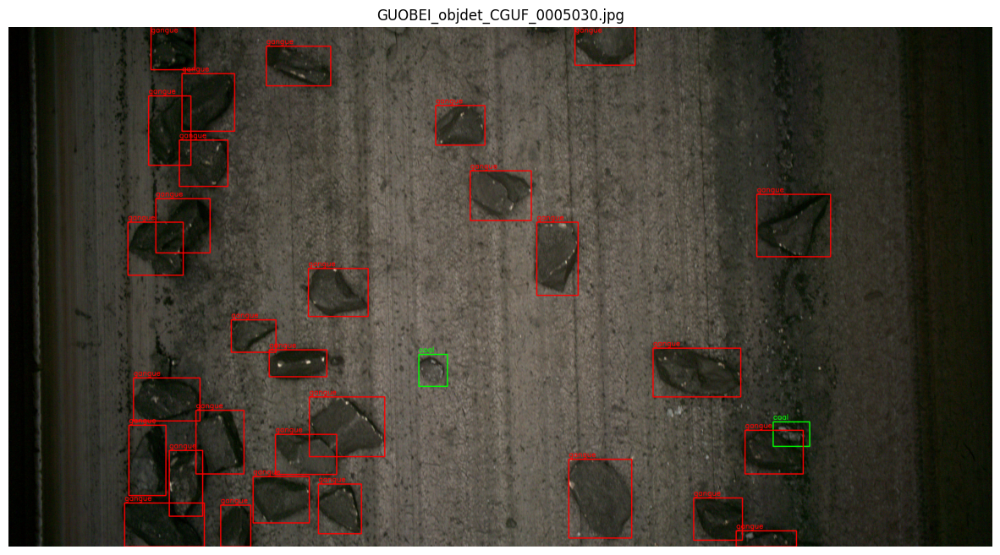

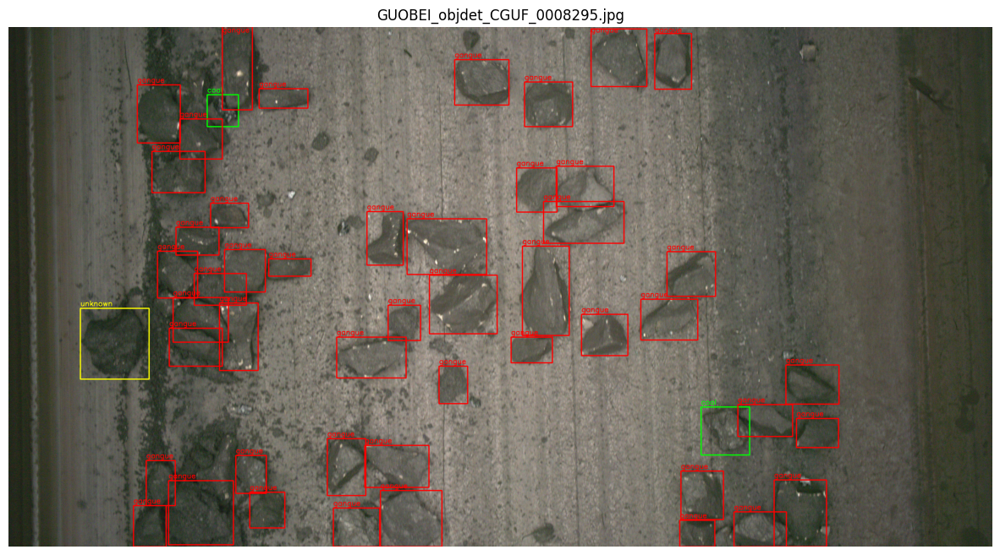

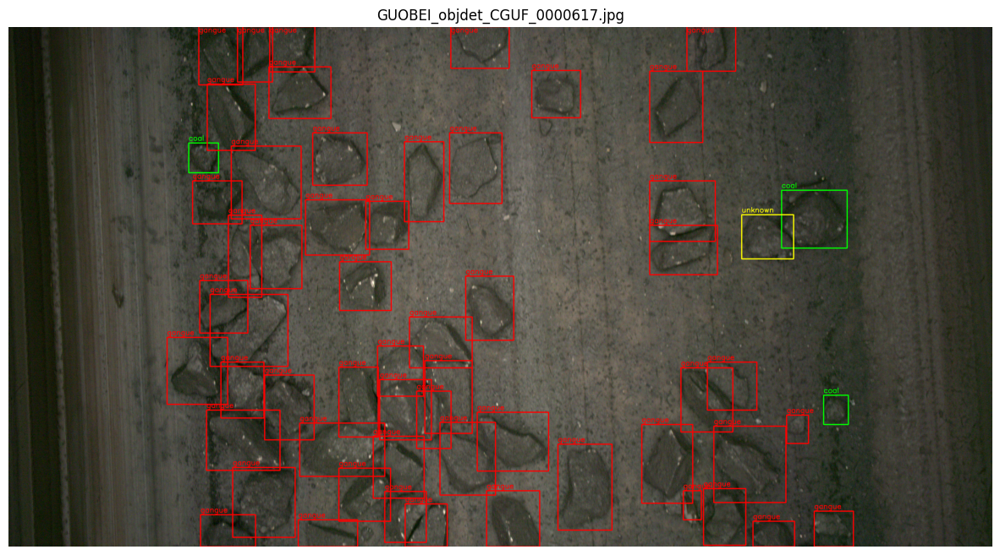

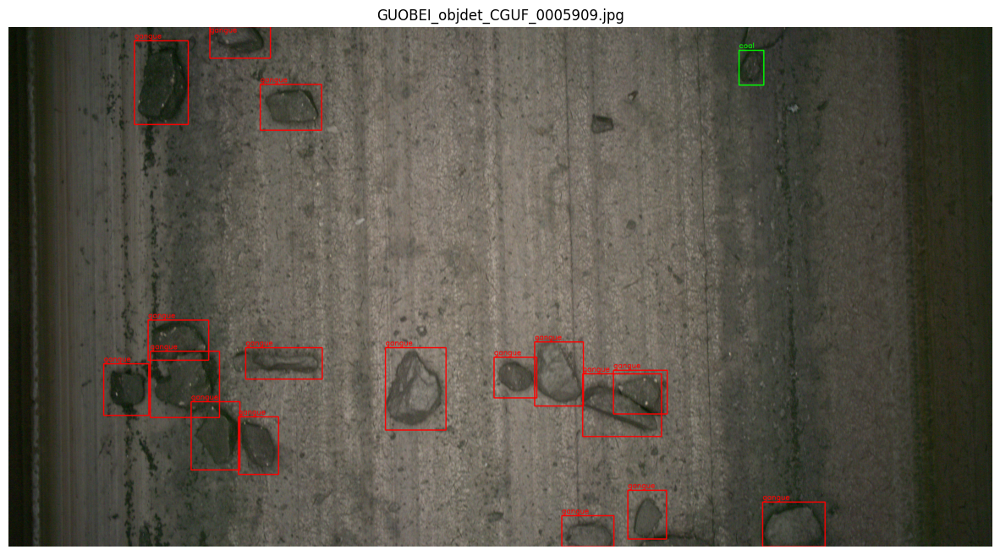

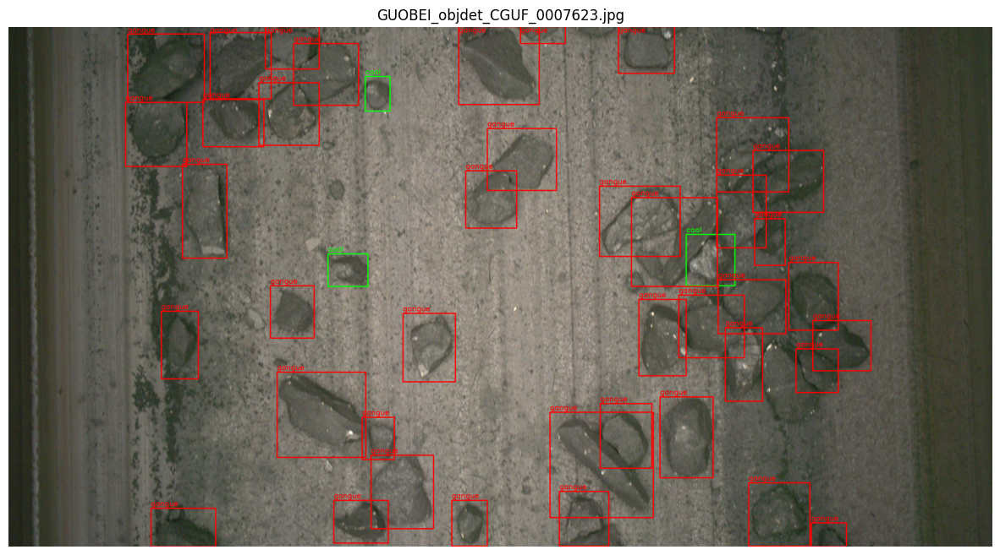

In [ ]:
import os
import random
import xml.etree.ElementTree as ET

import cv2
import matplotlib.pyplot as plt

base = "/content/extracted_data/productive_state/train"

img_dir = os.path.join(base, "img")
xml_dir = os.path.join(base, "annotation")

# Color for each class
colors = {
    "coal": (0, 255, 0),            # Green
    "gangue": (255, 0, 0),          # Blue
    "foreign_object": (0, 0, 255),  # Red
    "unknown": (255, 255, 0)        # Cyan
}

# Randomly select 5 XML files
xml_files = random.sample(
    [f for f in os.listdir(xml_dir) if f.endswith(".xml")],
    5
)

for xml_file in xml_files:

    tree = ET.parse(os.path.join(xml_dir, xml_file))
    root = tree.getroot()

    filename = root.find("filename").text

    # Some XMLs omit the .jpg extension
    if not filename.endswith(".jpg"):
        filename += ".jpg"

    image_path = os.path.join(img_dir, filename)

    image = cv2.imread(image_path)

    if image is None:
        print(f"Cannot read {filename}")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    for obj in root.findall("object"):

        cls = obj.find("name").text

        box = obj.find("bndbox")

        xmin = int(box.find("xmin").text)
        ymin = int(box.find("ymin").text)
        xmax = int(box.find("xmax").text)
        ymax = int(box.find("ymax").text)

        color = colors.get(cls, (255, 255, 255))

        cv2.rectangle(image, (xmin, ymin), (xmax, ymax), color, 3)

        cv2.putText(
            image,
            cls,
            (xmin, max(25, ymin-10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            color,
            2
        )

    plt.figure(figsize=(15,8))
    plt.imshow(image)
    plt.title(filename)
    plt.axis("off")
    plt.show()

In [ ]:
import os
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
import numpy as np

xml_dir = "/content/extracted_data/productive_state/train/annotation"

widths = []
heights = []
areas = []
aspect_ratios = []

for xml_file in os.listdir(xml_dir):

    if not xml_file.endswith(".xml"):
        continue

    root = ET.parse(os.path.join(xml_dir, xml_file)).getroot()

    for obj in root.findall("object"):

        if obj.find("name").text == "unknown":
            continue

        box = obj.find("bndbox")

        xmin = int(box.find("xmin").text)
        ymin = int(box.find("ymin").text)
        xmax = int(box.find("xmax").text)
        ymax = int(box.find("ymax").text)

        w = xmax - xmin
        h = ymax - ymin

        widths.append(w)
        heights.append(h)
        areas.append(w * h)
        aspect_ratios.append(w / h)

print(f"Total boxes: {len(widths)}")

print("\nWidth Statistics")
print(f"Mean   : {np.mean(widths):.2f}")
print(f"Median : {np.median(widths):.2f}")
print(f"Min    : {np.min(widths)}")
print(f"Max    : {np.max(widths)}")

print("\nHeight Statistics")
print(f"Mean   : {np.mean(heights):.2f}")
print(f"Median : {np.median(heights):.2f}")
print(f"Min    : {np.min(heights)}")
print(f"Max    : {np.max(heights)}")

print("\nArea Statistics")
print(f"Mean   : {np.mean(areas):.2f}")
print(f"Median : {np.median(areas):.2f}")
print(f"Min    : {np.min(areas)}")
print(f"Max    : {np.max(areas)}")

print("\nAspect Ratio")
print(f"Mean   : {np.mean(aspect_ratios):.2f}")
print(f"Median : {np.median(aspect_ratios):.2f}")

Total boxes: 271131

Width Statistics
Mean   : 213.76
Median : 210.00
Min    : 51
Max    : 1779

Height Statistics
Mean   : 215.23
Median : 212.00
Min    : 38
Max    : 2167

Area Statistics
Mean   : 47276.60
Median : 44982.00
Min    : 2535
Max    : 1490802

Aspect Ratio
Mean   : 1.07
Median : 0.99


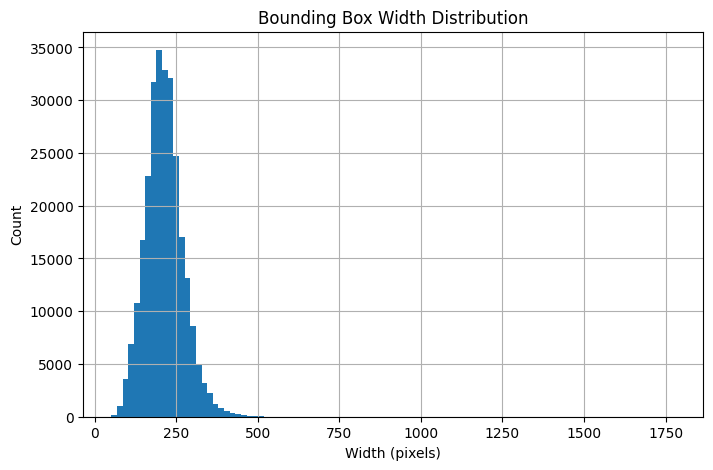

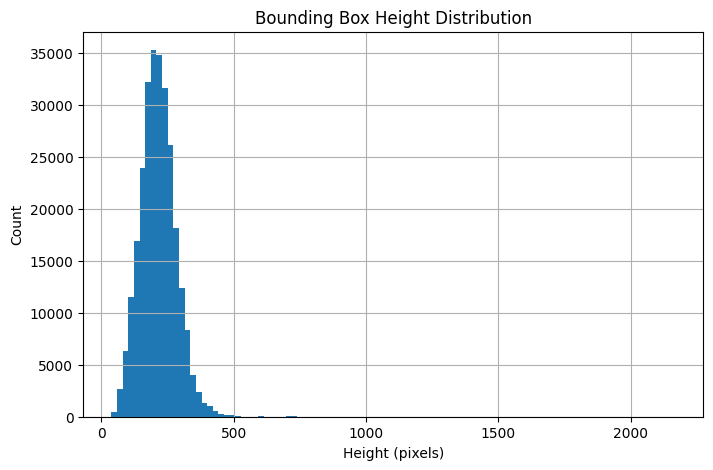

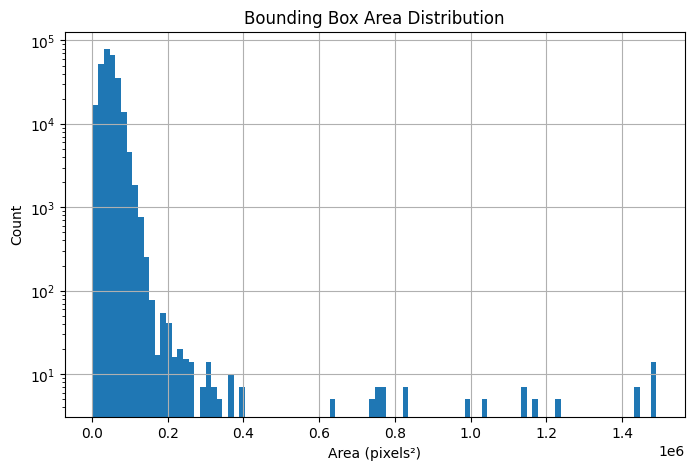

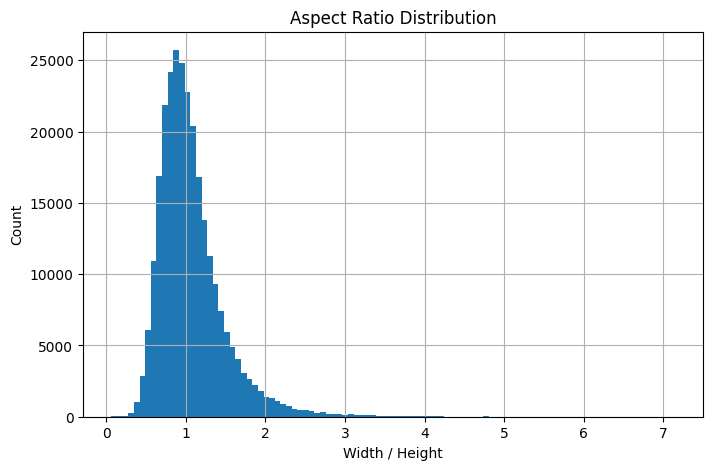

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(widths, bins=100)
plt.title("Bounding Box Width Distribution")
plt.xlabel("Width (pixels)")
plt.ylabel("Count")
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))
plt.hist(heights, bins=100)
plt.title("Bounding Box Height Distribution")
plt.xlabel("Height (pixels)")
plt.ylabel("Count")
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))
plt.hist(areas, bins=100, log=True)
plt.title("Bounding Box Area Distribution")
plt.xlabel("Area (pixels²)")
plt.ylabel("Count")
plt.grid(True)
plt.show()

plt.figure(figsize=(8,5))
plt.hist(aspect_ratios, bins=100)
plt.title("Aspect Ratio Distribution")
plt.xlabel("Width / Height")
plt.ylabel("Count")
plt.grid(True)
plt.show()

In [ ]:
for p in [5, 10, 25, 50, 75, 90, 95]:
    print(f"{p}% width  : {np.percentile(widths, p):.1f}")
print()

for p in [5, 10, 25, 50, 75, 90, 95]:
    print(f"{p}% height : {np.percentile(heights, p):.1f}")
print()

for p in [5, 10, 25, 50, 75, 90, 95]:
    print(f"{p}% area   : {np.percentile(areas, p):.1f}")

5% width  : 124.0
10% width  : 143.0
25% width  : 175.0
50% width  : 210.0
75% width  : 248.0
90% width  : 286.0
95% width  : 312.0

5% height : 110.0
10% height : 132.0
25% height : 170.0
50% height : 212.0
75% height : 256.0
90% height : 300.0
95% height : 326.0

5% area   : 15996.0
10% area   : 21321.0
25% area   : 32112.0
50% area   : 44982.0
75% area   : 59073.0
90% area   : 73632.0
95% area   : 83692.0


# **✅ Phase 2: Dataset Preparation**

In [ ]:
import os

base = "/content/extracted_data/productive_state"

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for folder in os.listdir(os.path.join(base, split)):
        path = os.path.join(base, split, folder)

        if os.path.isdir(path):
            print(f"├── {folder:<12} {len(os.listdir(path))} files")


TRAIN
├── img          8350 files
├── annotation   8350 files

VAL
├── img          3578 files
├── annotation   3578 files

TEST
├── ground_truth 900 files
├── img          900 files
├── annotation   900 files


In [ ]:
import os

base = "/content/extracted_data/productive_state"

for split in ["train", "val", "test"]:

    img_dir = os.path.join(base, split, "img")
    xml_dir = os.path.join(base, split, "annotation")

    images = {
        os.path.splitext(f)[0]
        for f in os.listdir(img_dir)
    }

    xmls = {
        os.path.splitext(f)[0]
        for f in os.listdir(xml_dir)
    }

    missing_images = xmls - images
    missing_xmls = images - xmls

    print(f"\n{split.upper()}")

    print("Missing Images :", len(missing_images))
    print("Missing XMLs   :", len(missing_xmls))


TRAIN
Missing Images : 0
Missing XMLs   : 0

VAL
Missing Images : 0
Missing XMLs   : 0

TEST
Missing Images : 0
Missing XMLs   : 0


In [ ]:
from collections import Counter
import os

base = "/content/extracted_data/productive_state"

for split in ["train", "val", "test"]:

    img_dir = os.path.join(base, split, "img")

    names = [
        os.path.splitext(f)[0]
        for f in os.listdir(img_dir)
    ]

    counter = Counter(names)

    duplicates = [
        k
        for k, v in counter.items()
        if v > 1
    ]

    print(split, "Duplicates:", len(duplicates))

train Duplicates: 0
val Duplicates: 0
test Duplicates: 0


In [ ]:
import os
from collections import Counter

img_dir = "/content/extracted_data/productive_state/train/img"

extensions = Counter(
    os.path.splitext(f)[1].lower()
    for f in os.listdir(img_dir)
)

print(extensions)

Counter({'.jpg': 8350})


In [ ]:
import os
import xml.etree.ElementTree as ET

xml_dir = "/content/extracted_data/productive_state/train/annotation"

errors = 0

for xml_file in os.listdir(xml_dir):

    root = ET.parse(os.path.join(xml_dir, xml_file)).getroot()

    xml_name = os.path.splitext(xml_file)[0]

    filename = root.find("filename").text

    if filename.endswith(".jpg"):
        filename = os.path.splitext(filename)[0]

    if filename != xml_name:
        errors += 1

print("Filename mismatches:", errors)

Filename mismatches: 0


In [4]:
import os
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

CLASS_MAP = {
    "coal": 0,
    "gangue": 1,
    "foreign_object": 2
}

base = "/content/extracted_data/productive_state"

stats = Counter()

for split in ["train", "val", "test"]:

    xml_dir = os.path.join(base, split, "annotation")
    label_dir = os.path.join(base, split, "labels")

    Path(label_dir).mkdir(exist_ok=True)

    print(f"\nConverting {split}...")

    for xml_file in os.listdir(xml_dir):

        if not xml_file.endswith(".xml"):
            continue

        tree = ET.parse(os.path.join(xml_dir, xml_file))
        root = tree.getroot()

        W = float(root.find("size/width").text)
        H = float(root.find("size/height").text)

        yolo_lines = []

        for obj in root.findall("object"):

            cls = obj.find("name").text

            # Skip unknown
            if cls not in CLASS_MAP:
                stats["Skipped Unknown"] += 1
                continue

            stats[cls] += 1

            cls_id = CLASS_MAP[cls]

            box = obj.find("bndbox")

            xmin = float(box.find("xmin").text)
            ymin = float(box.find("ymin").text)
            xmax = float(box.find("xmax").text)
            ymax = float(box.find("ymax").text)

            x = ((xmin + xmax) / 2) / W
            y = ((ymin + ymax) / 2) / H
            w = (xmax - xmin) / W
            h = (ymax - ymin) / H

            yolo_lines.append(
                f"{cls_id} {x:.6f} {y:.6f} {w:.6f} {h:.6f}"
            )

        txt_file = os.path.join(
            label_dir,
            xml_file.replace(".xml", ".txt")
        )

        with open(txt_file, "w") as f:
            f.write("\n".join(yolo_lines))

print("\nConversion Complete!\n")

print("Statistics")
for k, v in stats.items():
    print(f"{k:20s}: {v}")


Converting train...

Converting val...

Converting test...

Conversion Complete!

Statistics
coal                : 19625
Skipped Unknown     : 14735
gangue              : 385688
foreign_object      : 890


In [ ]:
import os

base = "/content/extracted_data/productive_state"

for split in ["train","val","test"]:

    img_dir = os.path.join(base, split, "img")
    label_dir = os.path.join(base, split, "labels")

    missing = []

    for img in os.listdir(img_dir):

        txt = os.path.splitext(img)[0] + ".txt"

        if not os.path.exists(os.path.join(label_dir, txt)):
            missing.append(img)

    print(f"{split}: {len(missing)} missing labels")

train: 0 missing labels
val: 0 missing labels
test: 0 missing labels


In [ ]:
for split in ["train","val","test"]:

    img_dir = os.path.join(base, split, "img")
    label_dir = os.path.join(base, split, "labels")

    images = {
        os.path.splitext(f)[0]
        for f in os.listdir(img_dir)
    }

    labels = {
        os.path.splitext(f)[0]
        for f in os.listdir(label_dir)
    }

    extra = labels - images

    print(split, len(extra))

train 0
val 0
test 0


In [ ]:
import os

base = "/content/extracted_data/productive_state"

errors = 0

for split in ["train","val","test"]:

    label_dir = os.path.join(base, split, "labels")

    for txt in os.listdir(label_dir):

        with open(os.path.join(label_dir, txt)) as f:

            for line in f:

                cls,x,y,w,h = map(float,line.split())

                if not (0 <= x <= 1):
                    errors += 1

                if not (0 <= y <= 1):
                    errors += 1

                if not (0 < w <= 1):
                    errors += 1

                if not (0 < h <= 1):
                    errors += 1

print("Errors:",errors)

Errors: 0


In [ ]:
import os

base = "/content/extracted_data/productive_state"

for split in ["train","val","test"]:

    label_dir = os.path.join(base, split, "labels")

    empty = 0

    for txt in os.listdir(label_dir):

        if os.path.getsize(os.path.join(label_dir, txt)) == 0:
            empty += 1

    print(split, empty)

train 5
val 2
test 0


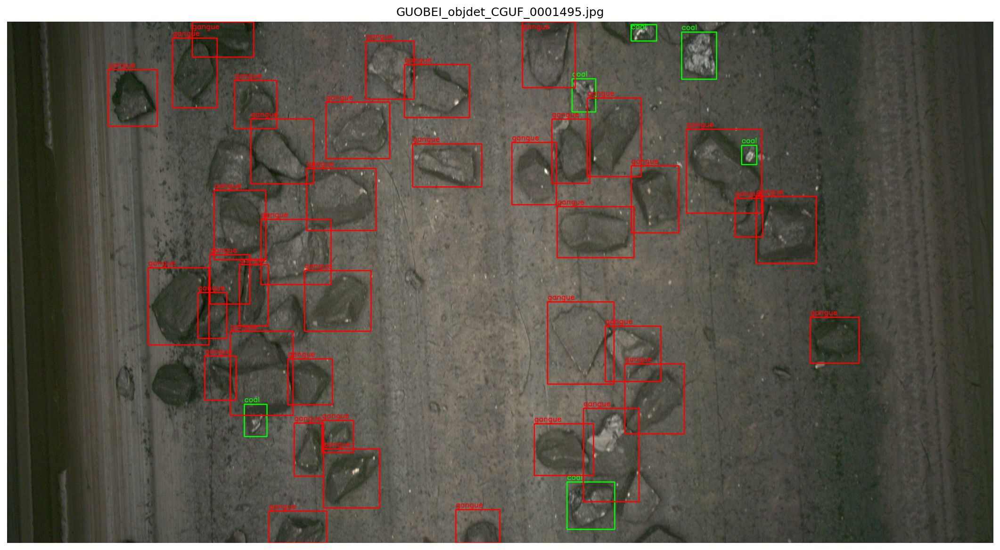

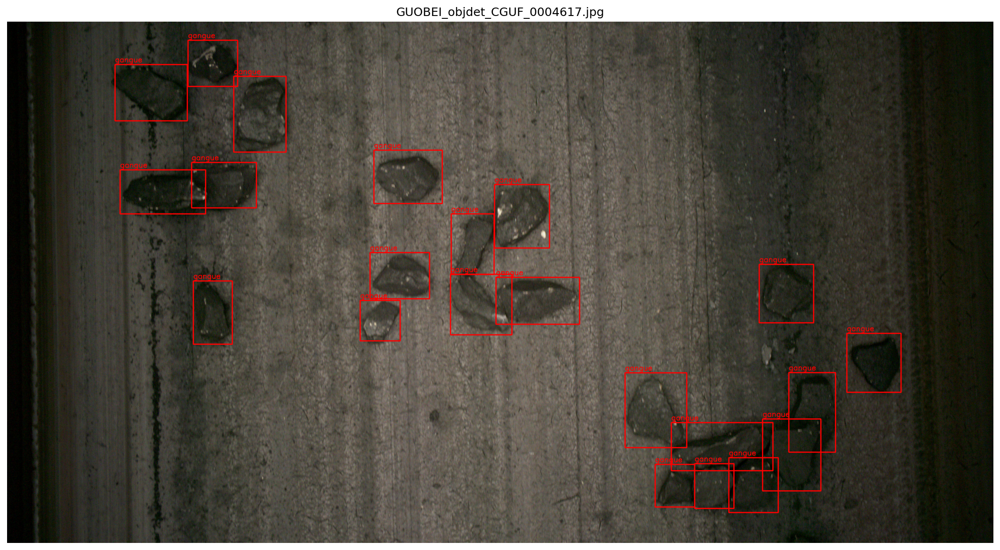

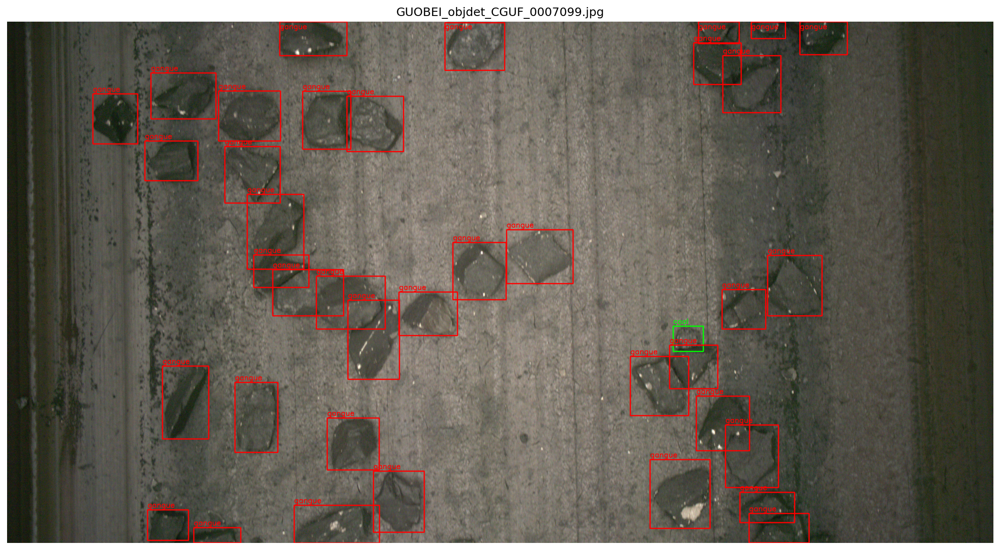

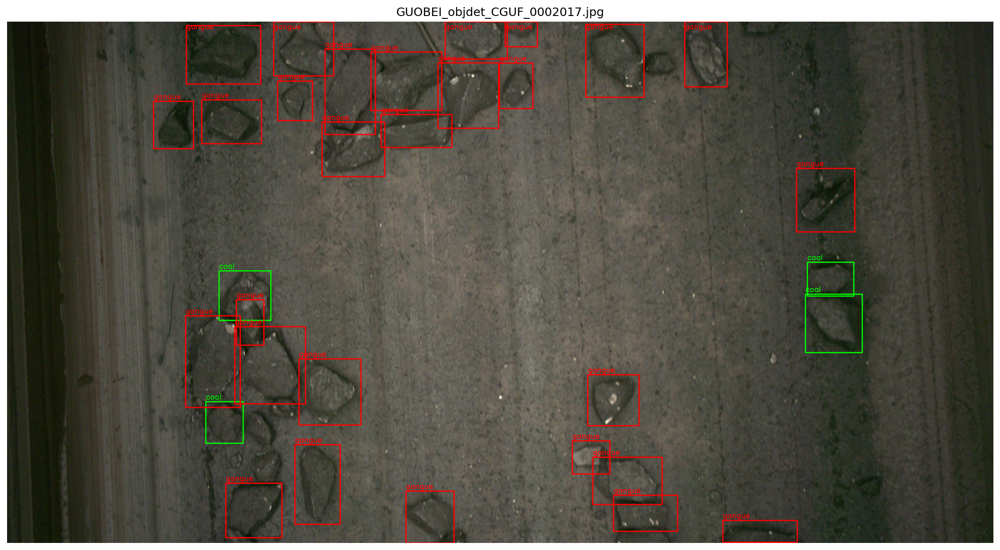

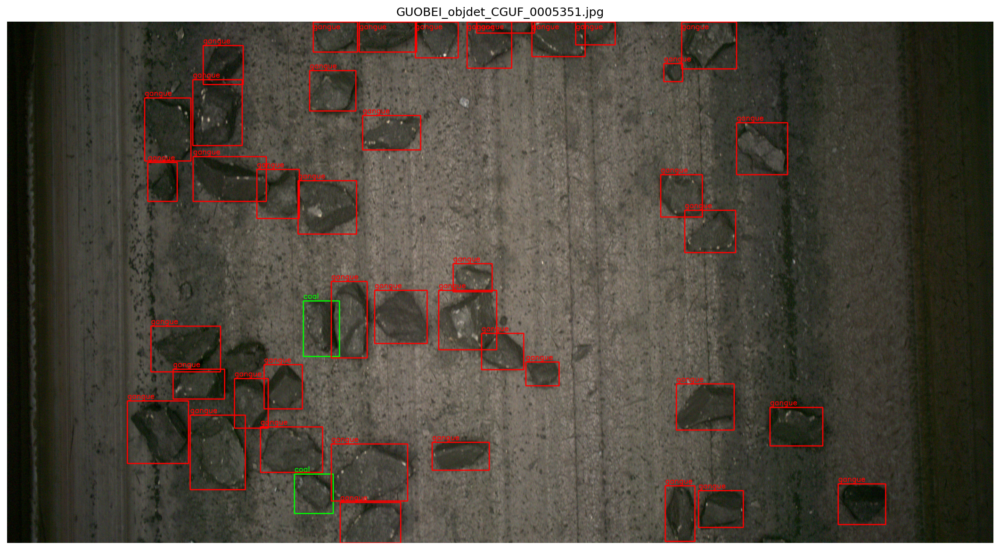

In [ ]:
import os
import random
import cv2
import matplotlib.pyplot as plt

base = "/content/extracted_data/productive_state/train"

img_dir = os.path.join(base, "img")
label_dir = os.path.join(base, "labels")

CLASS_NAMES = {
    0: "coal",
    1: "gangue",
    2: "foreign_object"
}

COLORS = {
    0: (0,255,0),
    1: (255,0,0),
    2: (255,255,0)
}

samples = random.sample(os.listdir(img_dir), 5)

for img_name in samples:

    image = cv2.imread(os.path.join(img_dir, img_name))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    H, W = image.shape[:2]

    txt = os.path.join(
        label_dir,
        os.path.splitext(img_name)[0] + ".txt"
    )

    if os.path.exists(txt):

        with open(txt) as f:

            for line in f:

                cls, x, y, w, h = map(float, line.split())

                cls = int(cls)

                xmin = int((x - w/2) * W)
                ymin = int((y - h/2) * H)
                xmax = int((x + w/2) * W)
                ymax = int((y + h/2) * H)

                cv2.rectangle(
                    image,
                    (xmin, ymin),
                    (xmax, ymax),
                    COLORS[cls],
                    3
                )

                cv2.putText(
                    image,
                    CLASS_NAMES[cls],
                    (xmin, max(30, ymin-10)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    1,
                    COLORS[cls],
                    2
                )

    plt.figure(figsize=(18,10), dpi=150)
    plt.imshow(image)
    plt.title(img_name)
    plt.axis("off")
    plt.show()

In [5]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.3/45.3 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 87.1 MB/s eta 0:00:00


# **✅ Phase 3: Model Training**

In [6]:
import torch

print("CUDA Available :", torch.cuda.is_available())
print("GPU :", torch.cuda.get_device_name(0))
print("CUDA Version :", torch.version.cuda)

CUDA Available : True
GPU : NVIDIA A100-SXM4-80GB
CUDA Version : 12.8


In [7]:
import os

base = "/content/extracted_data/productive_state"

for split in ["train", "val", "test"]:
    old = os.path.join(base, split, "img")
    new = os.path.join(base, split, "images")

    if os.path.exists(old):
        os.rename(old, new)

print("Done.")

Done.


In [8]:
# ===========================
# Create dataset.yaml
# ===========================

import yaml
from pathlib import Path

dataset = {
    "path": "/content/extracted_data/productive_state",
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "names": {
        0: "coal",
        1: "gangue",
        2: "foreign_object"
    }
}

yaml_path = "/content/dataset.yaml"

with open(yaml_path, "w") as f:
    yaml.dump(dataset, f, sort_keys=False)

print(f"dataset.yaml created at: {yaml_path}\n")

# Display file contents
with open(yaml_path, "r") as f:
    print(f.read())

dataset.yaml created at: /content/dataset.yaml

path: /content/extracted_data/productive_state
train: train/images
val: val/images
test: test/images
names:
  0: coal
  1: gangue
  2: foreign_object



In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11s.pt")

In [ ]:
import os
import glob

for f in glob.glob("/content/extracted_data/productive_state/**/*.cache", recursive=True):
    os.remove(f)
    print("Removed", f)

In [ ]:
from ultralytics.data.utils import check_det_dataset

check_det_dataset("/content/dataset.yaml")

In [ ]:
results = model.train(
    data="/content/dataset.yaml",

    # Training
    epochs=200,
    imgsz=1280,
    batch=8,

    # Hardware
    device=0,
    workers=2,
    cache=True,
    amp=True,

    # Early stopping
    patience=40,

    # Logging
    project="DsCGF",
    name="YOLO11s_Baseline",
    exist_ok=True,

    # Save
    save=True,
    save_period=10,

    # Visualization
    plots=True,
    verbose=True
)

Ultralytics 8.4.91 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11s_Baseline, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto,

In [ ]:
import shutil
import os

src = "/content/runs/detect/DsCGF/YOLO11s_Baseline"
dst = "/content/drive/MyDrive/DsCGF_Experiments/YOLO11s_Baseline"

os.makedirs(os.path.dirname(dst), exist_ok=True)

shutil.copytree(src, dst, dirs_exist_ok=True)

print("✅ Training results saved to:")
print(dst)

✅ Training results saved to:
/content/drive/MyDrive/DsCGF_Experiments/YOLO11s_Baseline


In [ ]:
import os

for f in os.listdir("/content/drive/MyDrive/DsCGF_Experiments/YOLO11s_Baseline"):
    print(f)

confusion_matrix_normalized.png
results.csv
BoxF1_curve.png
weights
val_batch0_labels.jpg
train_batch2.jpg
train_batch1.jpg
BoxPR_curve.png
val_batch1_pred.jpg
val_batch2_labels.jpg
train_batch0.jpg
labels.jpg
val_batch2_pred.jpg
results.png
confusion_matrix.png
val_batch1_labels.jpg
args.yaml
BoxP_curve.png
val_batch0_pred.jpg
BoxR_curve.png


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from pathlib import Path

GT_DIR = "/content/extracted_data/productive_state/val/labels"
PRED_DIR = "analysis/val_predictions/labels"

CLASS_NAMES = {
    0: "coal",
    1: "gangue",
    2: "foreign_object"
}

IOU_THRESH = 0.5

summary = []
false_negatives = []
false_positives = []
misclassified = []


def yolo_to_xyxy(box):
    cls, x, y, w, h = box[:5]
    return np.array([
        x-w/2,
        y-h/2,
        x+w/2,
        y+h/2
    ])


def iou(box1, box2):

    x1=max(box1[0],box2[0])
    y1=max(box1[1],box2[1])
    x2=min(box1[2],box2[2])
    y2=min(box1[3],box2[3])

    inter=max(0,x2-x1)*max(0,y2-y1)

    a1=(box1[2]-box1[0])*(box1[3]-box1[1])
    a2=(box2[2]-box2[0])*(box2[3]-box2[1])

    return inter/(a1+a2-inter+1e-6)


files = sorted(os.listdir(GT_DIR))

for file in files:

    gt_path = os.path.join(GT_DIR,file)
    pred_path = os.path.join(PRED_DIR,file)

    gt=[]
    pred=[]

    with open(gt_path) as f:

        for line in f:

            vals=list(map(float,line.split()))

            gt.append(vals)

    if os.path.exists(pred_path):

        with open(pred_path) as f:

            for line in f:

                vals=list(map(float,line.split()))

                pred.append(vals)

    matched_pred=set()

    for g in gt:

        best_iou=0
        best_idx=-1

        gbox=yolo_to_xyxy(g)

        for i,p in enumerate(pred):

            if i in matched_pred:
                continue

            pbox=yolo_to_xyxy(p)

            score=iou(gbox,pbox)

            if score>best_iou:
                best_iou=score
                best_idx=i

        if best_iou<IOU_THRESH:

            false_negatives.append([
                file,
                CLASS_NAMES[int(g[0])]
            ])

            continue

        matched_pred.add(best_idx)

        if int(pred[best_idx][0])!=int(g[0]):

            misclassified.append([
                file,
                CLASS_NAMES[int(g[0])],
                CLASS_NAMES[int(pred[best_idx][0])],
                pred[best_idx][5],
                best_iou
            ])

    for i,p in enumerate(pred):

        if i not in matched_pred:

            false_positives.append([
                file,
                CLASS_NAMES[int(p[0])],
                p[5]
            ])


pd.DataFrame(
    false_negatives,
    columns=["image","class"]
).to_csv("false_negatives.csv",index=False)

pd.DataFrame(
    false_positives,
    columns=["image","predicted_class","confidence"]
).to_csv("false_positives.csv",index=False)

pd.DataFrame(
    misclassified,
    columns=["image","ground_truth","prediction","confidence","IoU"]
).to_csv("misclassifications.csv",index=False)

print("False Negatives :",len(false_negatives))
print("False Positives :",len(false_positives))
print("Misclassified   :",len(misclassified))

False Negatives : 132062
False Positives : 0
Misclassified   : 0


In [ ]:
import pandas as pd

fn = pd.read_csv("false_negatives.csv")
fp = pd.read_csv("false_positives.csv")
mc = pd.read_csv("misclassifications.csv")

print("\nFalse Negatives")
print(fn["class"].value_counts())

print("\nFalse Positives")
print(fp["predicted_class"].value_counts())

print("\nMisclassifications")
print(mc.groupby(["ground_truth","prediction"]).size())


False Negatives
class
gangue            127781
coal                3962
foreign_object       319
Name: count, dtype: int64

False Positives
Series([], Name: count, dtype: int64)

Misclassifications
Series([], dtype: int64)


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11m.pt")

In [ ]:
results = model.train(
    data="/content/dataset.yaml",

    epochs=200,
    imgsz=1280,
    batch=8,

    device=0,
    workers=2,

    cache=True,
    amp=True,

    patience=40,

    project="DsCGF",

    name="YOLO11m_Baseline",

    exist_ok=True,

    save=True,
    save_period=10,

    plots=True,

    verbose=True,

    deterministic=True,

    seed=42
)

Ultralytics 8.4.92 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=True, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11m_Baseline, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto,

In [ ]:
import shutil
import os

src = "/content/runs/detect/DsCGF/YOLO11m_Baseline"
dst = "/content/drive/MyDrive/DsCGF_Experiments/YOLO11m_Baseline"

os.makedirs(os.path.dirname(dst), exist_ok=True)

shutil.copytree(src, dst, dirs_exist_ok=True)

print("✅ Training results saved to:")
print(dst)

✅ Training results saved to:
/content/drive/MyDrive/DsCGF_Experiments/YOLO11m_Baseline


In [ ]:
import os

for f in os.listdir("/content/drive/MyDrive/DsCGF_Experiments/YOLO11m_Baseline"):
    print(f)

val_batch1_labels.jpg
val_batch2_labels.jpg
results.png
val_batch1_pred.jpg
confusion_matrix.png
train_batch0.jpg
val_batch0_labels.jpg
args.yaml
confusion_matrix_normalized.png
BoxR_curve.png
labels.jpg
BoxF1_curve.png
BoxPR_curve.png
train_batch2.jpg
weights
val_batch2_pred.jpg
train_batch1.jpg
results.csv
val_batch0_pred.jpg
BoxP_curve.png


In [ ]:
import os
import pandas as pd
from collections import Counter

# -----------------------------
# Paths
# -----------------------------
train_img_dir = "/content/extracted_data/productive_state/train/images"
train_label_dir = "/content/extracted_data/productive_state/train/labels"

# Class names (same order as dataset.yaml)
class_names = {
    0: "coal",
    1: "gangue",
    2: "foreign_object"
}

rows = []

# -----------------------------
# Process every image
# -----------------------------
image_files = sorted([
    f for f in os.listdir(train_img_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

for image_name in image_files:

    label_file = os.path.join(
        train_label_dir,
        os.path.splitext(image_name)[0] + ".txt"
    )

    counts = Counter()

    if os.path.exists(label_file):

        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) == 5:
                    cls = int(parts[0])
                    counts[class_names[cls]] += 1

    coal = counts["coal"]
    gangue = counts["gangue"]
    foreign = counts["foreign_object"]

    rows.append({
        "image_id": image_name,
        "coal": coal,
        "gangue": gangue,
        "foreign_object": foreign,
        "total_objects": coal + gangue + foreign
    })

# -----------------------------
# Create DataFrame
# -----------------------------
df = pd.DataFrame(rows)

# Save CSV
output_csv = "train_image_class_distribution.csv"
df.to_csv(output_csv, index=False)

print(f"Saved to {output_csv}")

# -----------------------------
# Dataset Summary
# -----------------------------
print("\n==============================")
print("DATASET SUMMARY")
print("==============================")

print(f"Total training images : {len(df)}")

print("\nTotal instances")
print(df[["coal","gangue","foreign_object"]].sum())

print("\nImages containing each class")
print("Coal            :", (df.coal > 0).sum())
print("Gangue          :", (df.gangue > 0).sum())
print("Foreign Object  :", (df.foreign_object > 0).sum())

print("\nImages containing ONLY one class")
print("Only Coal       :", ((df.coal>0) & (df.gangue==0) & (df.foreign_object==0)).sum())
print("Only Gangue     :", ((df.coal==0) & (df.gangue>0) & (df.foreign_object==0)).sum())
print("Only Foreign    :", ((df.coal==0) & (df.gangue==0) & (df.foreign_object>0)).sum())

print("\nImages containing all three classes")
print(((df.coal>0) &
       (df.gangue>0) &
       (df.foreign_object>0)).sum())

print("\nAverage objects per image")
print(df[["coal","gangue","foreign_object","total_objects"]].mean().round(2))

print("\nMaximum objects in one image")
print(df[["coal","gangue","foreign_object","total_objects"]].max())

Saved to train_image_class_distribution.csv

DATASET SUMMARY
Total training images : 8350

Total instances
coal               14140
gangue            256526
foreign_object       465
dtype: int64

Images containing each class
Coal            : 5902
Gangue          : 8325
Foreign Object  : 361

Images containing ONLY one class
Only Coal       : 20
Only Gangue     : 2313
Only Foreign    : 0

Images containing all three classes
231

Average objects per image
coal               1.69
gangue            30.72
foreign_object     0.06
total_objects     32.47
dtype: float64

Maximum objects in one image
coal               9
gangue            86
foreign_object     4
total_objects     91
dtype: int64


In [ ]:
import pandas as pd

# ------------------------------------------------
# Load CSV
# ------------------------------------------------
df = pd.read_csv("train_image_class_distribution.csv")
# If using Colab, replace with full path if needed:
# df = pd.read_csv("/content/train_image_class_distribution.csv")

# Boolean masks
coal = df["coal"] > 0
gangue = df["gangue"] > 0
foreign = df["foreign_object"] > 0

# ------------------------------------------------
# Image combinations
# ------------------------------------------------
summary = {
    "Only Coal":
        (coal & ~gangue & ~foreign).sum(),

    "Only Gangue":
        (~coal & gangue & ~foreign).sum(),

    "Only Foreign Object":
        (~coal & ~gangue & foreign).sum(),

    "Coal + Gangue":
        (coal & gangue & ~foreign).sum(),

    "Coal + Foreign Object":
        (coal & ~gangue & foreign).sum(),

    "Gangue + Foreign Object":
        (~coal & gangue & foreign).sum(),

    "Coal + Gangue + Foreign Object":
        (coal & gangue & foreign).sum(),

    "No Objects":
        (~coal & ~gangue & ~foreign).sum()
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Category", "Number of Images"]
)

summary_df["Percentage"] = (
    summary_df["Number of Images"] / len(df) * 100
).round(2)

print(summary_df)

# ------------------------------------------------
# Save summary
# ------------------------------------------------
summary_df.to_csv("image_class_combinations.csv", index=False)

print("\nSaved to image_class_combinations.csv")

                         Category  Number of Images  Percentage
0                       Only Coal                20        0.24
1                     Only Gangue              2313       27.70
2             Only Foreign Object                 0        0.00
3                   Coal + Gangue              5651       67.68
4           Coal + Foreign Object                 0        0.00
5         Gangue + Foreign Object               130        1.56
6  Coal + Gangue + Foreign Object               231        2.77
7                      No Objects                 5        0.06

Saved to image_class_combinations.csv


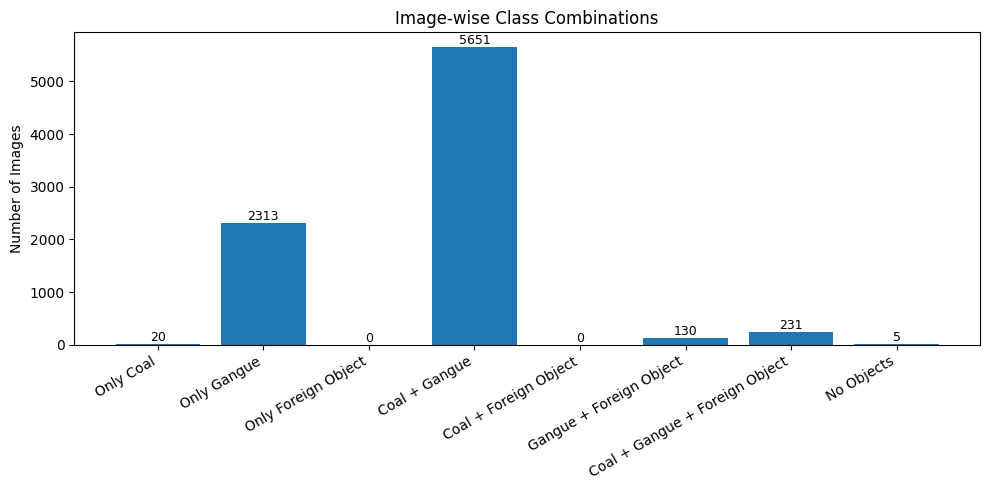

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

bars = plt.bar(
    summary_df["Category"],
    summary_df["Number of Images"]
)

plt.ylabel("Number of Images")
plt.title("Image-wise Class Combinations")
plt.xticks(rotation=30, ha="right")

for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        h,
        f"{int(h)}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import pandas as pd

# -----------------------------
# CONFIG
# -----------------------------
IMAGE_DIR = "/content/extracted_data/productive_state/train/images"
LABEL_DIR = "/content/extracted_data/productive_state/train/labels"

OUT_DIR = "/content/foreign_object_library"

CROP_DIR = os.path.join(OUT_DIR, "images")

os.makedirs(CROP_DIR, exist_ok=True)

PADDING = 10

metadata = []

crop_id = 0

# -----------------------------
# Process all labels
# -----------------------------
label_files = sorted(
    [f for f in os.listdir(LABEL_DIR) if f.endswith(".txt")]
)

for label_file in label_files:

    image_file = label_file.replace(".txt", ".jpg")

    img_path = os.path.join(IMAGE_DIR, image_file)

    if not os.path.exists(img_path):
        continue

    image = cv2.imread(img_path)

    H, W = image.shape[:2]

    with open(os.path.join(LABEL_DIR, label_file)) as f:

        for line in f:

            vals = line.strip().split()

            cls = int(vals[0])

            if cls != 2:
                continue

            x = float(vals[1])
            y = float(vals[2])
            w = float(vals[3])
            h = float(vals[4])

            xmin = int((x - w/2) * W)
            ymin = int((y - h/2) * H)
            xmax = int((x + w/2) * W)
            ymax = int((y + h/2) * H)

            xmin = max(0, xmin - PADDING)
            ymin = max(0, ymin - PADDING)
            xmax = min(W, xmax + PADDING)
            ymax = min(H, ymax + PADDING)

            crop = image[ymin:ymax, xmin:xmax]

            crop_name = f"foreign_{crop_id:06d}.png"

            cv2.imwrite(
                os.path.join(CROP_DIR, crop_name),
                crop
            )

            metadata.append({
                "crop_id": crop_id,
                "crop_name": crop_name,
                "source_image": image_file,
                "xmin": xmin,
                "ymin": ymin,
                "xmax": xmax,
                "ymax": ymax,
                "width": xmax - xmin,
                "height": ymax - ymin
            })

            crop_id += 1

# -----------------------------
# Save metadata
# -----------------------------
df = pd.DataFrame(metadata)

df.to_csv(
    os.path.join(OUT_DIR, "metadata.csv"),
    index=False
)

print("="*50)
print("Extraction Complete")
print("="*50)
print(f"Foreign objects extracted : {len(df)}")
print(f"Saved to : {OUT_DIR}")

Extraction Complete
Foreign objects extracted : 465
Saved to : /content/foreign_object_library


In [ ]:
import os
import cv2
import numpy as np

# -------------------------------------------------------
# CONFIG
# -------------------------------------------------------

CROP_DIR = "/content/foreign_object_library/images"

MASK_DIR = "/content/foreign_object_library/masks"

RGBA_DIR = "/content/foreign_object_library/masked_objects"

os.makedirs(MASK_DIR, exist_ok=True)
os.makedirs(RGBA_DIR, exist_ok=True)

# -------------------------------------------------------
# Process every crop
# -------------------------------------------------------

files = sorted(os.listdir(CROP_DIR))

for file in files:

    img = cv2.imread(os.path.join(CROP_DIR, file))

    if img is None:
        continue

    h, w = img.shape[:2]

    # ----------------------------
    # GrabCut initialization
    # ----------------------------

    mask = np.zeros((h, w), np.uint8)

    bgModel = np.zeros((1,65), np.float64)
    fgModel = np.zeros((1,65), np.float64)

    # Rectangle slightly inside crop
    rect = (
        2,
        2,
        max(1, w-4),
        max(1, h-4)
    )

    try:

        cv2.grabCut(
            img,
            mask,
            rect,
            bgModel,
            fgModel,
            5,
            cv2.GC_INIT_WITH_RECT
        )

    except:
        continue

    # ----------------------------
    # Binary mask
    # ----------------------------

    binary = np.where(
        (mask==cv2.GC_FGD) |
        (mask==cv2.GC_PR_FGD),
        255,
        0
    ).astype("uint8")

    # ----------------------------
    # Morphological cleanup
    # ----------------------------

    kernel = np.ones((3,3), np.uint8)

    binary = cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        kernel
    )

    binary = cv2.morphologyEx(
        binary,
        cv2.MORPH_CLOSE,
        kernel
    )

    # ----------------------------
    # Keep largest connected component
    # ----------------------------

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary)

    if num_labels > 1:

        largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])

        binary = np.where(labels==largest,255,0).astype(np.uint8)

    # ----------------------------
    # Save binary mask
    # ----------------------------

    cv2.imwrite(
        os.path.join(MASK_DIR,file),
        binary
    )

    # ----------------------------
    # Create transparent PNG
    # ----------------------------

    rgba = cv2.cvtColor(img, cv2.COLOR_BGR2BGRA)

    rgba[:,:,3] = binary

    cv2.imwrite(
        os.path.join(RGBA_DIR,file),
        rgba
    )

print("="*60)
print("Mask generation completed.")
print("="*60)

Mask generation completed.


In [ ]:
# import os
# import cv2
# import math
# import numpy as np
# import pandas as pd

# # =====================================================
# # CONFIG
# # =====================================================

# MASK_DIR = "/content/foreign_object_library/masks"
# RGBA_DIR = "/content/foreign_object_library/masked_objects"

# REPORT_CSV = "/content/foreign_object_library/mask_quality_report.csv"
# CONTACT_SHEET = "/content/foreign_object_library/mask_contact_sheet.jpg"

# THUMB_SIZE = 120

# # Thresholds
# MIN_FOREGROUND_AREA = 200          # pixels
# MAX_FOREGROUND_RATIO = 0.90        # >90% foreground -> suspicious
# MIN_FOREGROUND_RATIO = 0.02        # <2% foreground -> suspicious

# # =====================================================
# # ANALYZE MASKS
# # =====================================================

# results = []

# mask_files = sorted(os.listdir(MASK_DIR))

# for file in mask_files:

#     mask_path = os.path.join(MASK_DIR, file)

#     mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

#     if mask is None:
#         continue

#     h, w = mask.shape

#     foreground = np.count_nonzero(mask)

#     ratio = foreground / (h * w)

#     # Connected Components
#     num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask)

#     largest_component = 0

#     if num_labels > 1:
#         largest_component = np.max(stats[1:, cv2.CC_STAT_AREA])

#     # ------------------------------------------------
#     # Touching Borders
#     # ------------------------------------------------

#     touches_left = np.any(mask[:,0] > 0)
#     touches_right = np.any(mask[:,-1] > 0)
#     touches_top = np.any(mask[0,:] > 0)
#     touches_bottom = np.any(mask[-1,:] > 0)

#     touching_borders = (
#         touches_left +
#         touches_right +
#         touches_top +
#         touches_bottom
#     )

#     # ------------------------------------------------
#     # Quality Checks
#     # ------------------------------------------------

#     quality = "GOOD"

#     if foreground < MIN_FOREGROUND_AREA:
#         quality = "SMALL_MASK"

#     elif ratio < MIN_FOREGROUND_RATIO:
#         quality = "LOW_FOREGROUND"

#     elif ratio > MAX_FOREGROUND_RATIO:
#         quality = "TOO_LARGE"

#     elif touching_borders >= 3:
#         quality = "TOUCHING_BORDER"

#     elif num_labels > 5:
#         quality = "TOO_FRAGMENTED"

#     results.append({
#         "file": file,
#         "width": w,
#         "height": h,
#         "foreground_pixels": foreground,
#         "foreground_ratio": round(ratio,4),
#         "connected_components": num_labels-1,
#         "largest_component": largest_component,
#         "touching_borders": touching_borders,
#         "quality": quality
#     })

# # =====================================================
# # SAVE REPORT
# # =====================================================

# df = pd.DataFrame(results)

# df.to_csv(REPORT_CSV,index=False)

# print("="*60)
# print("Mask Quality Report")
# print("="*60)

# print(df["quality"].value_counts())

# print("\nSaved report to:")
# print(REPORT_CSV)

# # =====================================================
# # CONTACT SHEET
# # =====================================================

# good_files = df[df["quality"]=="GOOD"]["file"].tolist()

# N = len(good_files)

# cols = 10
# rows = math.ceil(N/cols)

# canvas = np.ones(
#     (
#         rows*THUMB_SIZE,
#         cols*THUMB_SIZE,
#         3
#     ),
#     dtype=np.uint8
# )*255

# for i,file in enumerate(good_files):

#     img = cv2.imread(os.path.join(RGBA_DIR,file),cv2.IMREAD_UNCHANGED)

#     if img is None:
#         continue

#     if img.shape[2] == 4:

#         alpha = img[:,:,3]

#         rgb = img[:,:,:3]

#         bg = np.ones_like(rgb)*255

#         alpha = alpha[:,:,None]/255.0

#         rgb = (rgb*alpha + bg*(1-alpha)).astype(np.uint8)

#     else:

#         rgb = img

#     thumb = cv2.resize(rgb,(THUMB_SIZE,THUMB_SIZE))

#     r = i//cols
#     c = i%cols

#     canvas[
#         r*THUMB_SIZE:(r+1)*THUMB_SIZE,
#         c*THUMB_SIZE:(c+1)*THUMB_SIZE
#     ] = thumb

# cv2.imwrite(CONTACT_SHEET,canvas)

# print("\nContact sheet saved:")
# print(CONTACT_SHEET)

Mask Quality Report
quality
SMALL_MASK        241
GOOD              115
LOW_FOREGROUND    109
Name: count, dtype: int64

Saved report to:
/content/foreign_object_library/mask_quality_report.csv

Contact sheet saved:
/content/foreign_object_library/mask_contact_sheet.jpg


In [ ]:
import os
import cv2
import numpy as np

# =====================================================
# CONFIG
# =====================================================

RGBA_DIR = "/content/foreign_object_library/masked_objects"

MASK_DIR = "/content/foreign_object_library/masks"

OUT_DIR = "/content/foreign_object_library/tight_objects"

os.makedirs(OUT_DIR, exist_ok=True)

PADDING = 5

# =====================================================

files = sorted(os.listdir(RGBA_DIR))

count = 0

for file in files:

    rgba = cv2.imread(
        os.path.join(RGBA_DIR, file),
        cv2.IMREAD_UNCHANGED
    )

    mask = cv2.imread(
        os.path.join(MASK_DIR, file),
        cv2.IMREAD_GRAYSCALE
    )

    if rgba is None or mask is None:
        continue

    ys, xs = np.where(mask > 0)

    if len(xs) == 0:
        continue

    xmin = xs.min()
    xmax = xs.max()

    ymin = ys.min()
    ymax = ys.max()

    tight = rgba[ymin:ymax+1, xmin:xmax+1]

    h, w = tight.shape[:2]

    canvas = np.zeros(
        (h + 2*PADDING,
         w + 2*PADDING,
         4),
        dtype=np.uint8
    )

    canvas[
        PADDING:PADDING+h,
        PADDING:PADDING+w
    ] = tight

    cv2.imwrite(
        os.path.join(OUT_DIR, file),
        canvas
    )

    count += 1

print("="*50)
print("Finished")
print("Objects:", count)
print("Saved to:", OUT_DIR)

Finished
Objects: 311
Saved to: /content/foreign_object_library/tight_objects


In [9]:
!unzip -q copy_paste_pipeline.zip

In [10]:
import sys

sys.path.append("/content")

In [11]:
from copy_paste_pipeline import Config, run_pipeline

In [12]:
import zipfile
import os

zip_file_path = '/content/drive/MyDrive/summer_training/foreign_object_library_archive.zip'
extraction_path = '/content/foreign_object_library'

# Create the extraction directory if it doesn't exist
os.makedirs(extraction_path, exist_ok=True)

print(f"Unzipping '{zip_file_path}' to '{extraction_path}'")

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extraction_path)

print(f"Successfully unzipped to '{extraction_path}'")

# Verify the contents of the newly unzipped directory
print(f"Contents of '{extraction_path}':")
print(os.listdir(extraction_path))

Unzipping '/content/drive/MyDrive/summer_training/foreign_object_library_archive.zip' to '/content/foreign_object_library'
Successfully unzipped to '/content/foreign_object_library'
Contents of '/content/foreign_object_library':
['masked_objects', 'images', 'metadata.csv', 'masks', 'tight_objects']


In [13]:
from pathlib import Path

cfg = Config(
    DATASET_ROOT=Path("/content/extracted_data/productive_state"),
    FOREIGN_OBJECT_LIB=Path("/content/foreign_object_library"),
    OUTPUT_ROOT=Path("/content/augmented_dataset")
)

report = run_pipeline(cfg)

Generating previews: 100%|██████████| 50/50 [00:13<00:00,  3.74it/s]


CONTEXT-AWARE COPY-PASTE AUGMENTATION -- SUMMARY
Training images processed        : 8350
Images that failed processing     : 0
Images selected for augmentation  : 4013 (48.1%)
  - without existing foreign_object: 3968/7989
  - with existing foreign_object   : 45/361
Total placement attempts          : 7993
Successful pastes                 : 7805
Failed placements                 : 188
  Failure reason breakdown:
    - object_too_large_for_roi: 186
    - iou_retry_budget_exhausted: 2
Images with >=1 object pasted     : 3985 (47.7%)
Average objects pasted per image  : 0.93
  Additions-per-image distribution:
    - 0 object(s): 4365 image(s)
    - 1 object(s): 1380 image(s)
    - 2 object(s): 1390 image(s)
    - 3 object(s): 1215 image(s)



In [ ]:
# import shutil
# import os

# folder_to_delete = "/content/copy_paste_pipeline"

# # Create a dummy folder for demonstration if it doesn't exist
# # os.makedirs(folder_to_delete, exist_ok=True)
# # print(f"Created dummy folder: {folder_to_delete}")

# if os.path.exists(folder_to_delete):
#     shutil.rmtree(folder_to_delete)
#     print(f"Successfully deleted folder: {folder_to_delete}")
# else:
#     print(f"Folder does not exist: {folder_to_delete}")

Successfully deleted folder: /content/copy_paste_pipeline


In [ ]:
# import shutil
# import os
# from google.colab import files

# # Define the directory to be archived
# folder_to_archive = "/content/foreign_object_library"

# # Define the output path for the zip file (without .zip extension)
# output_zip_path = "/content/foreign_object_library_archive"

# if os.path.exists(folder_to_archive):
#     # Create a zip archive of the specified folder
#     shutil.make_archive(
#         base_name=output_zip_path, # The name of the archive without extension
#         format='zip',              # The archive format (e.g., 'zip', 'tar')
#         root_dir=folder_to_archive # The directory to archive
#     )

#     print(f"Archive created: {output_zip_path}.zip")

#     # Offer the file for download
#     files.download(f"{output_zip_path}.zip")
# else:
#     print(f"Folder not found: {folder_to_archive}")

Archive created: /content/foreign_object_library_archive.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import pandas as pd
from collections import Counter

# -----------------------------
# Paths
# -----------------------------
train_img_dir = "/content/augmented_dataset/train/images"
train_label_dir = "/content/augmented_dataset/train/labels"

# Class names (same order as dataset.yaml)
class_names = {
    0: "coal",
    1: "gangue",
    2: "foreign_object"
}

rows = []

# -----------------------------
# Process every image
# -----------------------------
image_files = sorted([
    f for f in os.listdir(train_img_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

for image_name in image_files:

    label_file = os.path.join(
        train_label_dir,
        os.path.splitext(image_name)[0] + ".txt"
    )

    counts = Counter()

    if os.path.exists(label_file):

        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) == 5:
                    cls = int(parts[0])
                    counts[class_names[cls]] += 1

    coal = counts["coal"]
    gangue = counts["gangue"]
    foreign = counts["foreign_object"]

    rows.append({
        "image_id": image_name,
        "coal": coal,
        "gangue": gangue,
        "foreign_object": foreign,
        "total_objects": coal + gangue + foreign
    })

# -----------------------------
# Create DataFrame
# -----------------------------
df = pd.DataFrame(rows)

# Save CSV
output_csv = "augmented_train_image_class_distribution.csv"
df.to_csv(output_csv, index=False)

print(f"Saved to {output_csv}")

# -----------------------------
# Dataset Summary
# -----------------------------
print("\n==============================")
print("DATASET SUMMARY")
print("==============================")

print(f"Total training images : {len(df)}")

print("\nTotal instances")
print(df[["coal","gangue","foreign_object"]].sum())

print("\nImages containing each class")
print("Coal            :", (df.coal > 0).sum())
print("Gangue          :", (df.gangue > 0).sum())
print("Foreign Object  :", (df.foreign_object > 0).sum())

print("\nImages containing ONLY one class")
print("Only Coal       :", ((df.coal>0) & (df.gangue==0) & (df.foreign_object==0)).sum())
print("Only Gangue     :", ((df.coal==0) & (df.gangue>0) & (df.foreign_object==0)).sum())
print("Only Foreign    :", ((df.coal==0) & (df.gangue==0) & (df.foreign_object>0)).sum())

print("\nImages containing all three classes")
print(((df.coal>0) &
       (df.gangue>0) &
       (df.foreign_object>0)).sum())

print("\nAverage objects per image")
print(df[["coal","gangue","foreign_object","total_objects"]].mean().round(2))

print("\nMaximum objects in one image")
print(df[["coal","gangue","foreign_object","total_objects"]].max())

Saved to augmented_train_image_class_distribution.csv

DATASET SUMMARY
Total training images : 8350

Total instances
coal               14140
gangue            256526
foreign_object      8413
dtype: int64

Images containing each class
Coal            : 5902
Gangue          : 8325
Foreign Object  : 4340

Images containing ONLY one class
Only Coal       : 10
Only Gangue     : 1154
Only Foreign    : 3

Images containing all three classes
3038

Average objects per image
coal               1.69
gangue            30.72
foreign_object     1.01
total_objects     33.42
dtype: float64

Maximum objects in one image
coal               9
gangue            86
foreign_object     5
total_objects     92
dtype: int64


In [ ]:
from pathlib import Path
import pandas as pd

# ------------------------------------------------
# Dataset root
# ------------------------------------------------
DATASET_ROOT = Path("/content/augmented_dataset")
# DATASET_ROOT = Path("/content/extracted_data/productive_state")   # Original dataset

csv_path = "/content/augmented_train_image_class_distribution.csv"

df = pd.read_csv(csv_path)

# ------------------------------------------------
# Boolean masks
# ------------------------------------------------
coal = df["coal"] > 0
gangue = df["gangue"] > 0
foreign = df["foreign_object"] > 0

# ------------------------------------------------
# Image combinations
# ------------------------------------------------
summary = {
    "Only Coal":
        (coal & ~gangue & ~foreign).sum(),

    "Only Gangue":
        (~coal & gangue & ~foreign).sum(),

    "Only Foreign Object":
        (~coal & ~gangue & foreign).sum(),

    "Coal + Gangue":
        (coal & gangue & ~foreign).sum(),

    "Coal + Foreign Object":
        (coal & ~gangue & foreign).sum(),

    "Gangue + Foreign Object":
        (~coal & gangue & foreign).sum(),

    "Coal + Gangue + Foreign Object":
        (coal & gangue & foreign).sum(),

    "No Objects":
        (~coal & ~gangue & ~foreign).sum()
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Category", "Number of Images"]
)

summary_df["Percentage"] = (
    summary_df["Number of Images"] / len(df) * 100
).round(2)

print(summary_df)

# ------------------------------------------------
# Save summary
# ------------------------------------------------
output_csv = DATASET_ROOT / "image_class_combinations.csv"
summary_df.to_csv(output_csv, index=False)

print(f"\nSaved to {output_csv}")

                         Category  Number of Images  Percentage
0                       Only Coal                10        0.12
1                     Only Gangue              1154       13.82
2             Only Foreign Object                 3        0.04
3                   Coal + Gangue              2844       34.06
4           Coal + Foreign Object                10        0.12
5         Gangue + Foreign Object              1289       15.44
6  Coal + Gangue + Foreign Object              3038       36.38
7                      No Objects                 2        0.02

Saved to /content/augmented_dataset/image_class_combinations.csv


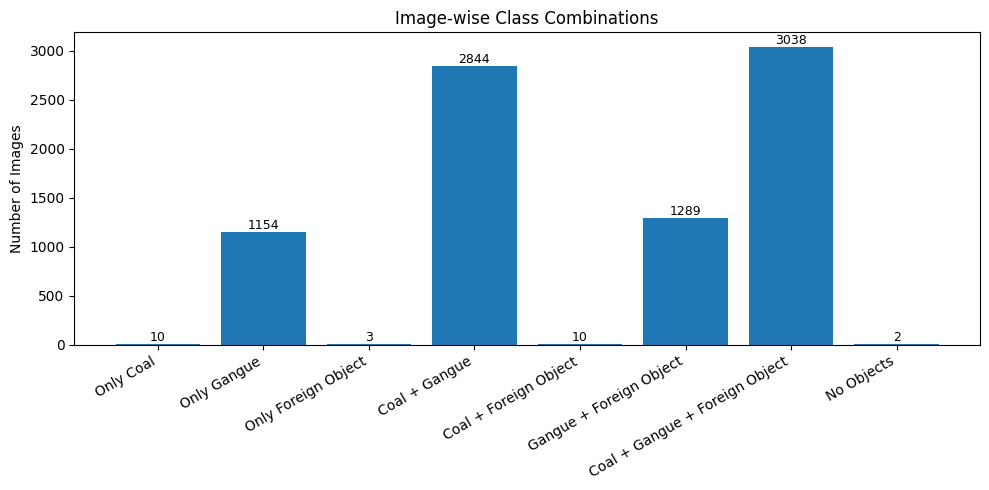

Saved plot to /content/augmented_dataset/image_class_combinations.png


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

bars = plt.bar(
    summary_df["Category"],
    summary_df["Number of Images"]
)

plt.ylabel("Number of Images")
plt.title("Image-wise Class Combinations")
plt.xticks(rotation=30, ha="right")

for bar in bars:
    h = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        h,
        f"{int(h)}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

output_plot = DATASET_ROOT / "image_class_combinations.png"
plt.savefig(output_plot, dpi=300, bbox_inches="tight")

plt.show()

print(f"Saved plot to {output_plot}")

In [ ]:
!pip install -q ultralytics

In [14]:
from pathlib import Path
import yaml

dataset = {
    "path": "/content/augmented_dataset",
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "names": {
        0: "coal",
        1: "gangue",
        2: "foreign_object"
    }
}

with open("/content/augmented_dataset/dataset.yaml", "w") as f:
    yaml.dump(dataset, f, sort_keys=False)

print("dataset.yaml created.")

dataset.yaml created.


In [ ]:
import os
from google.colab import drive
from ultralytics import YOLO


checkpoint_dir = "/content/drive/MyDrive/MyProjectFolder/runs"
run_name = "yolo11m_augmented"

last_checkpoint = os.path.join(
    checkpoint_dir,
    run_name,
    "weights",
    "last.pt"
)

# -------------------------------------------------
# Resume if checkpoint exists
# -------------------------------------------------
if os.path.exists(last_checkpoint):

    print(f"Resuming from:\n{last_checkpoint}")

    model = YOLO(last_checkpoint)

    results = model.train(resume=True)

# -------------------------------------------------
# Otherwise start a new training run
# -------------------------------------------------
else:

    print("Starting new training run...")

    model = YOLO("yolo11m.pt")

    results = model.train(

        # Dataset
        data="/content/augmented_dataset/dataset.yaml",

        # Training
        epochs=150,
        imgsz=640,
        batch=24,
        workers=12,

        # Output
        project=checkpoint_dir,
        name=run_name,
        exist_ok=True,

        # Optimization
        optimizer="auto",
        lr0=0.01,
        amp=True,

        # Early stopping
        patience=30,

        # Checkpoints
        save=True,
        save_period=5,

        # Performance
        cache="ram",

        # Misc
        device=0,
        seed=42,
        verbose=True,
        plots=True
    )

# -------------------------------------------------
# Print useful paths
# -------------------------------------------------
best_model = os.path.join(
    checkpoint_dir,
    run_name,
    "weights",
    "best.pt"
)

last_model = os.path.join(
    checkpoint_dir,
    run_name,
    "weights",
    "last.pt"
)

print("\nTraining complete.")
print(f"Best model : {best_model}")
print(f"Last model : {last_model}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.100 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/augmented_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze

In [ ]:
from ultralytics import YOLO
import pandas as pd
from pathlib import Path

# -------------------------------------------------
# Paths
# -------------------------------------------------
run_dir = Path("/content/drive/MyDrive/MyProjectFolder/runs/yolo11m_augmented")
results_dir = Path("/content/drive/MyDrive/MyProjectFolder/results")
results_dir.mkdir(parents=True, exist_ok=True)

best_model_path = run_dir / "weights" / "best.pt"

# -------------------------------------------------
# Load best model
# -------------------------------------------------
model = YOLO(best_model_path)

# -------------------------------------------------
# Validation Set Evaluation
# -------------------------------------------------
val_metrics = model.val(
    data="/content/augmented_dataset/dataset.yaml",
    split="val"
)

# -------------------------------------------------
# Test Set Evaluation
# -------------------------------------------------
test_metrics = model.val(
    data="/content/augmented_dataset/dataset.yaml",
    split="test"
)

# -------------------------------------------------
# Save summary metrics
# -------------------------------------------------
summary = pd.DataFrame([
    {
        "Dataset": "Validation",
        "Precision": val_metrics.box.mp,
        "Recall": val_metrics.box.mr,
        "mAP50": val_metrics.box.map50,
        "mAP50-95": val_metrics.box.map
    },
    {
        "Dataset": "Test",
        "Precision": test_metrics.box.mp,
        "Recall": test_metrics.box.mr,
        "mAP50": test_metrics.box.map50,
        "mAP50-95": test_metrics.box.map
    }
])

summary.to_csv(results_dir / "metrics_summary.csv", index=False)

print(summary)

print("\nMetrics saved to:")
print(results_dir / "metrics_summary.csv")

Ultralytics 8.4.100 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11m summary (fused): 126 layers, 20,032,345 parameters, 0 gradients, 67.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3990.0±482.3 MB/s, size: 2626.4 KB)
val: Scanning /content/augmented_dataset/val/labels.cache... 3578 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3578/3578 1.0Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 224/224 4.7it/s 47.6s
                   all       3578     132062       0.78      0.764      0.765      0.554
                  coal       1994       3962      0.688      0.683       0.64      0.525
                gangue       3568     127781      0.943      0.945      0.964      0.667
        foreign_object        283        319      0.708      0.665      0.691       0.47
Speed: 0.5ms preprocess, 6.1ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /content/runs/det

# **Testing**

In [15]:
import zipfile
import os

zip_file_path = '/content/best_yolos.zip'
extraction_path = '/content/yolo11s_baseline/'

# Create the extraction directory if it doesn't exist
os.makedirs(extraction_path, exist_ok=True)

print(f"Unzipping '{zip_file_path}' to '{extraction_path}'")

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extraction_path)

print(f"Successfully unzipped to '{extraction_path}'")

# Verify the contents of the newly unzipped directory
print(f"Contents of '{extraction_path}':")
print(os.listdir(extraction_path))

Unzipping '/content/best_yolos.zip' to '/content/yolo11s_baseline/'
Successfully unzipped to '/content/yolo11s_baseline/'
Contents of '/content/yolo11s_baseline/':
['best.pt']


In [16]:
from ultralytics import YOLO

model = YOLO("/content/yolo11s_baseline/best.pt")

metrics = model.val(
    data="/content/dataset.yaml",   # YAML pointing to test split
    split="test",
    imgsz=1280,
    batch=16,
    conf=0.001,
    iou=0.6,
    save=True,
    project="comparison",
    name="yolo11s_test"
)

print(metrics)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.104 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
YOLO11s summary (fused): 101 layers, 9,413,961 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1499.3±1629.7 MB/s, size: 4406.9 KB)
val: Scanning /content/extracted_data/productive_state/test/labels... 900 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 900/900 284.0it/s 3.2s
val: New cache created: /content/extracted_data/productive_state/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 57/57 3.1it/s 18.5s
                   all        900       3010      0.781      

In [17]:
import pandas as pd
pd.DataFrame([{
    "model": "yolo11s_baseline_1280",
    "map50": metrics.box.map50,
    "map50_95": metrics.box.map,
    "precision": metrics.box.mp,
    "recall": metrics.box.mr,
}]).to_csv(f"{metrics.save_dir}/metrics_summary.csv", index=False)
print(f"Saved to: {metrics.save_dir}/metrics_summary.csv")

per_class_rows = []
for i, cls_id in enumerate(metrics.box.ap_class_index):
    per_class_rows.append({
        "class": metrics.names[cls_id],
        "precision": metrics.box.p[i],
        "recall": metrics.box.r[i],
        "ap50": metrics.box.ap50[i],
        "ap50_95": metrics.box.ap[i],
    })
pd.DataFrame(per_class_rows).to_csv(f"{metrics.save_dir}/per_class_metrics.csv", index=False)
print(f"Per-class saved to: {metrics.save_dir}/per_class_metrics.csv")

Saved to: /content/runs/detect/comparison/yolo11s_test/metrics_summary.csv
Per-class saved to: /content/runs/detect/comparison/yolo11s_test/per_class_metrics.csv


In [18]:
import zipfile
import os

zip_file_path = '/content/best.zip'
extraction_path = '/content/yolo11m_baseline'

# Create the extraction directory if it doesn't exist
os.makedirs(extraction_path, exist_ok=True)

print(f"Unzipping '{zip_file_path}' to '{extraction_path}'")

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extraction_path)

print(f"Successfully unzipped to '{extraction_path}'")

# Verify the contents of the newly unzipped directory
print(f"Contents of '{extraction_path}':")
print(os.listdir(extraction_path))

Unzipping '/content/best.zip' to '/content/yolo11m_baseline'
Successfully unzipped to '/content/yolo11m_baseline'
Contents of '/content/yolo11m_baseline':
['best.pt']


In [19]:
from ultralytics import YOLO

model = YOLO("/content/yolo11m_baseline/best.pt")

metrics = model.val(
    data="/content/dataset.yaml",
    split="test",
    imgsz=1280,
    batch=16,
    conf=0.001,
    iou=0.6,
    save=True,
    project="comparison",
    name="yolo11m_test"
)

print(metrics)

Ultralytics 8.4.104 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
YOLO11m summary (fused): 126 layers, 20,032,345 parameters, 0 gradients, 67.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4272.6±1058.8 MB/s, size: 4410.8 KB)
val: Scanning /content/extracted_data/productive_state/test/labels.cache... 900 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 900/900 343.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 57/57 2.9it/s 19.4s
                   all        900       3010      0.813      0.741      0.763      0.534
                  coal        481       1523       0.95      0.729      0.824      0.659
                gangue        501       1381      0.742      0.937      0.877      0.609
        foreign_object        100        106      0.748      0.557      0.589      0.334
Speed: 1.9ms preprocess, 4.7ms inference, 0.0ms loss, 1.6ms postprocess per image
Results s

In [20]:
import pandas as pd
pd.DataFrame([{
    "model": "yolo11m_baseline_1280",
    "map50": metrics.box.map50,
    "map50_95": metrics.box.map,
    "precision": metrics.box.mp,
    "recall": metrics.box.mr,
}]).to_csv(f"{metrics.save_dir}/metrics_summary.csv", index=False)
print(f"Saved to: {metrics.save_dir}/metrics_summary.csv")

per_class_rows = []
for i, cls_id in enumerate(metrics.box.ap_class_index):
    per_class_rows.append({
        "class": metrics.names[cls_id],
        "precision": metrics.box.p[i],
        "recall": metrics.box.r[i],
        "ap50": metrics.box.ap50[i],
        "ap50_95": metrics.box.ap[i],
    })
pd.DataFrame(per_class_rows).to_csv(f"{metrics.save_dir}/per_class_metrics.csv", index=False)
print(f"Per-class saved to: {metrics.save_dir}/per_class_metrics.csv")

Saved to: /content/runs/detect/comparison/yolo11m_test/metrics_summary.csv
Per-class saved to: /content/runs/detect/comparison/yolo11m_test/per_class_metrics.csv


In [ ]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/runs/yolo11m_augmented/weights/best.pt")

metrics = model.val(
    data="/content/augmented_dataset/dataset.yaml",
    split="test",
    imgsz=640,
    batch=16,
    conf=0.001,
    iou=0.6,
    save=True,
    project="comparison",
    name="yolo11m_augm_test"
)

print(metrics)

Ultralytics 8.4.104 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
YOLO11m summary (fused): 126 layers, 20,032,345 parameters, 0 gradients, 67.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4431.1±361.2 MB/s, size: 4438.7 KB)
val: Scanning /content/augmented_dataset/test/labels.cache... 900 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 900/900 290.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 57/57 3.3it/s 17.5s
                   all        900       3010      0.813      0.686      0.733      0.554
                  coal        481       1523      0.959      0.565      0.746      0.587
                gangue        501       1381      0.724        0.9      0.802      0.543
        foreign_object        100        106      0.756      0.594       0.65      0.531
Speed: 0.6ms preprocess, 2.1ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /conten

In [ ]:
import pandas as pd
pd.DataFrame([{
    "model": "yolo11m_augment_640",
    "map50": metrics.box.map50,
    "map50_95": metrics.box.map,
    "precision": metrics.box.mp,
    "recall": metrics.box.mr,
}]).to_csv(f"{metrics.save_dir}/metrics_summary.csv", index=False)
print(f"Saved to: {metrics.save_dir}/metrics_summary.csv")

per_class_rows = []
for i, cls_id in enumerate(metrics.box.ap_class_index):
    per_class_rows.append({
        "class": metrics.names[cls_id],
        "precision": metrics.box.p[i],
        "recall": metrics.box.r[i],
        "ap50": metrics.box.ap50[i],
        "ap50_95": metrics.box.ap[i],
    })
pd.DataFrame(per_class_rows).to_csv(f"{metrics.save_dir}/per_class_metrics.csv", index=False)
print(f"Per-class saved to: {metrics.save_dir}/per_class_metrics.csv")

Saved to: /content/runs/detect/comparison/yolo11m_augm_test-3/metrics_summary.csv
Per-class saved to: /content/runs/detect/comparison/yolo11m_augm_test-3/per_class_metrics.csv


In [ ]:
import shutil
import os

# Define the directory to be archived (replace with your folder path)
folder_to_archive = '/content/runs/detect/comparison/yolo11m_augm_test'

# Define the output path for the zip file (without .zip extension, it will be added automatically)
output_zip_path = '/content/yolo11m_augm_test'

try:
    if os.path.exists(folder_to_archive):
        # Create a zip archive of the specified folder
        shutil.make_archive(
            base_name=output_zip_path, # The name of the archive without extension
            format='zip',              # The archive format (e.g., 'zip', 'tar')
            root_dir=folder_to_archive # The directory to archive
        )
        print(f"Successfully created zip archive: {output_zip_path}.zip")
    else:
        print(f"Error: Folder not found at '{folder_to_archive}'")
except FileNotFoundError:
    print(f"Error: The folder '{folder_to_archive}' does not exist.")
except Exception as e:
    print(f"An error occurred while trying to zip the folder: {e}")


Successfully created zip archive: /content/yolo11m_augm_test.zip


In [21]:
import shutil
import os

# Define the directory to be archived (replace with your folder path)
folder_to_archive = '/content/runs/detect/comparison/yolo11s_test'

# Define the output path for the zip file (without .zip extension, it will be added automatically)
output_zip_path = '/content/yolo11s_test'

try:
    if os.path.exists(folder_to_archive):
        # Create a zip archive of the specified folder
        shutil.make_archive(
            base_name=output_zip_path, # The name of the archive without extension
            format='zip',              # The archive format (e.g., 'zip', 'tar')
            root_dir=folder_to_archive # The directory to archive
        )
        print(f"Successfully created zip archive: {output_zip_path}.zip")
    else:
        print(f"Error: Folder not found at '{folder_to_archive}'")
except FileNotFoundError:
    print(f"Error: The folder '{folder_to_archive}' does not exist.")
except Exception as e:
    print(f"An error occurred while trying to zip the folder: {e}")


Successfully created zip archive: /content/yolo11s_test.zip


In [22]:
import shutil
import os

# Define the directory to be archived (replace with your folder path)
folder_to_archive = '/content/runs/detect/comparison/yolo11m_test'

# Define the output path for the zip file (without .zip extension, it will be added automatically)
output_zip_path = '/content/yolo11m_test'

try:
    if os.path.exists(folder_to_archive):
        # Create a zip archive of the specified folder
        shutil.make_archive(
            base_name=output_zip_path, # The name of the archive without extension
            format='zip',              # The archive format (e.g., 'zip', 'tar')
            root_dir=folder_to_archive # The directory to archive
        )
        print(f"Successfully created zip archive: {output_zip_path}.zip")
    else:
        print(f"Error: Folder not found at '{folder_to_archive}'")
except FileNotFoundError:
    print(f"Error: The folder '{folder_to_archive}' does not exist.")
except Exception as e:
    print(f"An error occurred while trying to zip the folder: {e}")


Successfully created zip archive: /content/yolo11m_test.zip


In [ ]:

# =========================================================================================
# RUNNER CELL — paste this in Colab FIRST, edit the paths, run it, then run the main script cell.
# =========================================================================================



# --- 2. Set your paths here (these get reused by the main script) ---
BASELINE_MODEL         = "/content/yolo11m_baseline/best.pt"
AUGMENTED_MODEL        = "/content/drive/MyDrive/runs/yolo11m_augmented/weights/best.pt"
ORIGINAL_DATASET_YAML  = "/content/dataset.yaml"
AUGMENTED_DATASET_YAML = "/content/augmented_dataset/dataset.yaml"
OUTPUT_DIR             = "/content/drive/MyDrive/DsCGF/results"   # Drive path so results survive disconnects

# --- 3. Sanity-check everything exists BEFORE running inference ---
from pathlib import Path
import yaml

checks = {
    "BASELINE_MODEL": BASELINE_MODEL,
    "AUGMENTED_MODEL": AUGMENTED_MODEL,
    "ORIGINAL_DATASET_YAML": ORIGINAL_DATASET_YAML,
    "AUGMENTED_DATASET_YAML": AUGMENTED_DATASET_YAML,
}

all_ok = True
for name, path in checks.items():
    exists = Path(path).exists()
    print(f"[{'OK' if exists else 'MISSING'}] {name}: {path}")
    if not exists:
        all_ok = False

# --- 4. Check each dataset yaml resolves real image folders ---
def check_yaml(yaml_path, label):
    if not Path(yaml_path).exists():
        return
    with open(yaml_path) as f:
        data = yaml.safe_load(f)
    base = Path(data.get("path", Path(yaml_path).parent))
    if not base.is_absolute():
        base = (Path(yaml_path).parent / base).resolve()
    print(f"\n[{label}] base path: {base}")
    for split in ["train", "val", "test"]:
        if split not in data:
            print(f"  [WARN] '{split}' key missing in {label} yaml")
            continue
        split_path = base / data[split] if not Path(data[split]).is_absolute() else Path(data[split])
        n_images = len(list(split_path.rglob("*.jpg"))) + len(list(split_path.rglob("*.png"))) if split_path.is_dir() else "N/A (file list)"
        print(f"  {split}: {split_path}  ->  images found: {n_images}")

check_yaml(ORIGINAL_DATASET_YAML, "ORIGINAL_DATASET_YAML")
check_yaml(AUGMENTED_DATASET_YAML, "AUGMENTED_DATASET_YAML")

if not all_ok:
    raise FileNotFoundError("One or more paths above are MISSING — fix them before running the main script.")
else:
    print("\nAll paths found. Now open ensemble_wbf_yolo11.py, update its top variable block to match "
          "the paths above (and set DEVICE/IMGSZ/CONF/IOU), paste it into the NEXT cell, and run it.")


[OK] BASELINE_MODEL: /content/yolo11m_baseline/best.pt
[OK] AUGMENTED_MODEL: /content/drive/MyDrive/runs/yolo11m_augmented/weights/best.pt
[OK] ORIGINAL_DATASET_YAML: /content/dataset.yaml
[OK] AUGMENTED_DATASET_YAML: /content/augmented_dataset/dataset.yaml

[ORIGINAL_DATASET_YAML] base path: /content/extracted_data/productive_state
  train: /content/extracted_data/productive_state/train/images  ->  images found: 8350
  val: /content/extracted_data/productive_state/val/images  ->  images found: 3578
  test: /content/extracted_data/productive_state/test/images  ->  images found: 900

[AUGMENTED_DATASET_YAML] base path: /content/augmented_dataset
  train: /content/augmented_dataset/train/images  ->  images found: 8350
  val: /content/augmented_dataset/val/images  ->  images found: 3578
  test: /content/augmented_dataset/test/images  ->  images found: 900

All paths found. Now open ensemble_wbf_yolo11.py, update its top variable block to match the paths above (and set DEVICE/IMGSZ/CONF/IO

In [ ]:
# =========================================================================================
# YOLO11m Class-Wise Weighted-Box-Fusion Ensemble Search  (Baseline vs Context-Aware Copy-Paste)
# Paste this entire cell into Jupyter / Google Colab and run top to bottom. No other edits needed.
# =========================================================================================

get_ipython().system('pip install -q ultralytics ensemble-boxes') if 'get_ipython' in globals() else None
import subprocess, sys
try:
    import ultralytics, ensemble_boxes  # noqa
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics", "ensemble-boxes"], check=True)

# =========================================================================================
# EDITABLE VARIABLES
# =========================================================================================
BASELINE_MODEL         = "/content/yolo11m_baseline/best.pt"
AUGMENTED_MODEL        = "/content/drive/MyDrive/runs/yolo11m_augmented/weights/best.pt"
ORIGINAL_DATASET_YAML  = "/content/dataset.yaml"
AUGMENTED_DATASET_YAML = "/content/augmented_dataset/dataset.yaml"
DEVICE                 = 0
IMGSZ                  = 1280
CONF                   = 0.001
IOU                    = 0.60
OUTPUT_DIR             = "/content/results"

# =========================================================================================
# IMPORTS
# =========================================================================================
import os
import json
import pickle
import yaml
import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm

from ultralytics import YOLO
from ultralytics.utils.metrics import ap_per_class, box_iou, ConfusionMatrix
from ensemble_boxes import weighted_boxes_fusion

# =========================================================================================
# CONSTANTS (internal, not user-editable per spec)
# =========================================================================================
CLASS_NAMES = {0: "coal", 1: "gangue", 2: "foreign_object"}
NUM_CLASSES = len(CLASS_NAMES)
IOUV = np.linspace(0.50, 0.95, 10)          # IoU thresholds for mAP50-95, mirrors Ultralytics validator
WEIGHT_GRID = [round(x, 1) for x in np.arange(0.0, 1.0001, 0.1)]
WBF_IOU_THR = 0.55                          # box-merge IoU threshold used inside WBF itself
WBF_SKIP_BOX_THR = 0.0                      # boxes are already filtered by CONF at inference time
MAX_ANNOTATED_IMAGES = 60                   # cap number of annotated images written per split (perf)

DEVICE_STR = str(DEVICE) if torch.cuda.is_available() else "cpu"
print(f"[INFO] Using device: {DEVICE_STR}")

OUTPUT_DIR = Path(OUTPUT_DIR)
CACHE_DIR = OUTPUT_DIR / "cache"
ANNOT_VAL_DIR = OUTPUT_DIR / "annotated_val"
ANNOT_TEST_DIR = OUTPUT_DIR / "annotated_test"
for d in [OUTPUT_DIR, CACHE_DIR, ANNOT_VAL_DIR, ANNOT_TEST_DIR]:
    d.mkdir(parents=True, exist_ok=True)

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# =========================================================================================
# DATASET RESOLUTION
# NOTE: Validation and test images/labels are resolved from ORIGINAL_DATASET_YAML only.
# The Context-Aware Copy-Paste augmentation is a TRAIN-TIME-ONLY pipeline, so the canonical
# val/test images (used for fair, unbiased comparison of both models) come from the
# original dataset definition. AUGMENTED_DATASET_YAML is loaded only for bookkeeping /
# sanity checks and is not used to source evaluation images.
# =========================================================================================

def load_dataset_yaml(yaml_path):
    yaml_path = Path(yaml_path)
    with open(yaml_path, "r") as f:
        data = yaml.safe_load(f)
    base = Path(data.get("path", yaml_path.parent))
    if not base.is_absolute():
        base = (yaml_path.parent / base).resolve()
    return data, base


def resolve_split_images(data, base, split):
    field = data.get(split, None)
    if field is None:
        return None
    entries = field if isinstance(field, list) else [field]
    image_paths = []
    for entry in entries:
        p = Path(entry)
        if not p.is_absolute():
            p = base / entry
        if p.is_file() and p.suffix.lower() == ".txt":
            with open(p, "r") as f:
                for line in f:
                    line = line.strip()
                    if not line:
                        continue
                    ip = Path(line)
                    if not ip.is_absolute():
                        ip = base / line
                    image_paths.append(ip)
        elif p.is_dir():
            image_paths.extend(sorted([q for q in p.rglob("*") if q.suffix.lower() in IMG_EXTS]))
        else:
            print(f"[WARN] Could not resolve split entry: {p}")
    return sorted(set(image_paths))


def label_path_for(img_path: Path) -> Path:
    parts = list(img_path.parts)
    for i in range(len(parts) - 1, -1, -1):
        if parts[i] == "images":
            parts[i] = "labels"
            break
    return Path(*parts).with_suffix(".txt")


def load_gt(label_path: Path):
    boxes, classes = [], []
    if label_path.exists():
        with open(label_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                c = int(float(parts[0]))
                xc, yc, w, h = map(float, parts[1:5])
                x1, y1, x2, y2 = xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2
                boxes.append([max(0.0, x1), max(0.0, y1), min(1.0, x2), min(1.0, y2)])
                classes.append(c)
    boxes_arr = np.array(boxes, dtype=np.float32).reshape(-1, 4)
    classes_arr = np.array(classes, dtype=np.int64)
    return boxes_arr, classes_arr


print("[INFO] Resolving dataset splits from ORIGINAL_DATASET_YAML ...")
orig_data, orig_base = load_dataset_yaml(ORIGINAL_DATASET_YAML)
val_images = resolve_split_images(orig_data, orig_base, "val")
test_images = resolve_split_images(orig_data, orig_base, "test")
if test_images is None:
    print("[WARN] No 'test' split found in ORIGINAL_DATASET_YAML. Falling back to 'val' split for testing too.")
    test_images = val_images
if val_images is None or len(val_images) == 0:
    raise RuntimeError("No validation images resolved from ORIGINAL_DATASET_YAML. Check the yaml 'val' field.")

_ = load_dataset_yaml(AUGMENTED_DATASET_YAML)  # sanity check the yaml is readable/valid

print(f"[INFO] Validation images: {len(val_images)}")
print(f"[INFO] Test images: {len(test_images)}")

gt_lookup_val = {str(p): load_gt(label_path_for(p)) for p in val_images}
gt_lookup_test = {str(p): load_gt(label_path_for(p)) for p in test_images}

# =========================================================================================
# MODEL LOADING
# =========================================================================================
print("[INFO] Loading models ...")
model_baseline = YOLO(BASELINE_MODEL)
model_augmented = YOLO(AUGMENTED_MODEL)

# =========================================================================================
# INFERENCE (RUN ONCE, CACHE EVERYTHING)
# =========================================================================================

def run_and_cache(model, image_paths, cache_file: Path, desc: str):
    if cache_file.exists():
        print(f"[INFO] Loading cached predictions: {cache_file}")
        with open(cache_file, "rb") as f:
            return pickle.load(f)

    cache = {}
    with torch.no_grad():
        for img_path in tqdm(image_paths, desc=desc):
            results = model.predict(
                source=str(img_path),
                imgsz=IMGSZ,
                conf=CONF,
                iou=IOU,
                device=DEVICE_STR,
                verbose=False,
            )[0]
            h, w = results.orig_shape
            if results.boxes is not None and len(results.boxes) > 0:
                xyxy = results.boxes.xyxy.cpu().numpy().astype(np.float32)
                boxes_norm = xyxy.copy()
                boxes_norm[:, [0, 2]] /= w
                boxes_norm[:, [1, 3]] /= h
                boxes_norm = np.clip(boxes_norm, 0.0, 1.0)
                scores = results.boxes.conf.cpu().numpy().astype(np.float32)
                classes = results.boxes.cls.cpu().numpy().astype(np.int64)
            else:
                boxes_norm = np.zeros((0, 4), dtype=np.float32)
                scores = np.zeros((0,), dtype=np.float32)
                classes = np.zeros((0,), dtype=np.int64)
            cache[str(img_path)] = dict(boxes=boxes_norm, scores=scores, classes=classes, w=w, h=h)

    with open(cache_file, "wb") as f:
        pickle.dump(cache, f)
    return cache


print("[INFO] Running inference (once per model per split), caching results ...")
cache_val_baseline = run_and_cache(model_baseline, val_images, CACHE_DIR / "val_baseline.pkl", "Val/Baseline inference")
cache_val_augmented = run_and_cache(model_augmented, val_images, CACHE_DIR / "val_augmented.pkl", "Val/Augmented inference")
cache_test_baseline = run_and_cache(model_baseline, test_images, CACHE_DIR / "test_baseline.pkl", "Test/Baseline inference")
cache_test_augmented = run_and_cache(model_augmented, test_images, CACHE_DIR / "test_augmented.pkl", "Test/Augmented inference")

# =========================================================================================
# CLASS-WISE WEIGHTED BOX FUSION
# =========================================================================================

def wbf_single_class(boxes1, scores1, labels1, boxes2, scores2, labels2, class_id, w1, w2):
    m1 = labels1 == class_id
    m2 = labels2 == class_id
    b1, s1 = boxes1[m1].tolist(), scores1[m1].tolist()
    b2, s2 = boxes2[m2].tolist(), scores2[m2].tolist()
    l1 = [int(class_id)] * len(s1)
    l2 = [int(class_id)] * len(s2)
    if len(s1) == 0 and len(s2) == 0:
        return (np.zeros((0, 4), dtype=np.float32), np.zeros((0,), dtype=np.float32), np.zeros((0,), dtype=np.int64))
    fb, fs, fl = weighted_boxes_fusion(
        [b1, b2], [s1, s2], [l1, l2],
        weights=[w1, w2],
        iou_thr=WBF_IOU_THR,
        skip_box_thr=WBF_SKIP_BOX_THR,
    )
    return np.array(fb, dtype=np.float32), np.array(fs, dtype=np.float32), np.array(fl, dtype=np.int64)


def fuse_image_all_classes(pred1, pred2, class_weights):
    all_b, all_s, all_l = [], [], []
    for c, w1 in class_weights.items():
        w2 = round(1.0 - w1, 4)
        fb, fs, fl = wbf_single_class(
            pred1["boxes"], pred1["scores"], pred1["classes"],
            pred2["boxes"], pred2["scores"], pred2["classes"],
            c, w1, w2,
        )
        if len(fb):
            all_b.append(fb); all_s.append(fs); all_l.append(fl)
    if all_b:
        return np.concatenate(all_b), np.concatenate(all_s), np.concatenate(all_l)
    return np.zeros((0, 4), dtype=np.float32), np.zeros((0,), dtype=np.float32), np.zeros((0,), dtype=np.int64)

# =========================================================================================
# IOU-BASED MATCHING (mirrors Ultralytics DetectionValidator._process_batch)
# Produces the TP matrix consumed by Ultralytics' own ap_per_class — no manual mAP math.
# =========================================================================================

def match_predictions(pred_boxes, pred_cls, gt_boxes, gt_cls, iouv=IOUV):
    n_pred = len(pred_cls)
    tp = np.zeros((n_pred, len(iouv)), dtype=bool)
    if n_pred == 0 or len(gt_cls) == 0:
        return tp
    iou = box_iou(torch.tensor(gt_boxes), torch.tensor(pred_boxes)).cpu().numpy()
    correct_class = gt_cls[:, None] == pred_cls[None, :]
    for i, thresh in enumerate(iouv):
        gt_idx, pred_idx = np.where((iou >= thresh) & correct_class)
        if gt_idx.shape[0]:
            matches = np.stack([gt_idx, pred_idx], axis=1)
            if matches.shape[0] > 1:
                match_iou = iou[matches[:, 0], matches[:, 1]]
                matches = matches[match_iou.argsort()[::-1]]
                matches = matches[np.unique(matches[:, 1], return_index=True)[1]]
                matches = matches[np.unique(matches[:, 0], return_index=True)[1]]
            tp[matches[:, 1].astype(int), i] = True
    return tp

# =========================================================================================
# PER-CLASS GRID SEARCH (validation split only)
# =========================================================================================

def evaluate_class_weight(cache1, cache2, image_paths, gt_lookup, class_id, w1):
    w2 = round(1.0 - w1, 4)
    tp_list, conf_list, predcls_list, targetcls_list = [], [], [], []
    for img_path in image_paths:
        key = str(img_path)
        p1, p2 = cache1[key], cache2[key]
        fb, fs, fl = wbf_single_class(
            p1["boxes"], p1["scores"], p1["classes"],
            p2["boxes"], p2["scores"], p2["classes"],
            class_id, w1, w2,
        )
        gt_boxes, gt_cls = gt_lookup[key]
        mask = gt_cls == class_id
        gt_b, gt_c = gt_boxes[mask], gt_cls[mask]
        tp = match_predictions(fb, fl, gt_b, gt_c)
        tp_list.append(tp); conf_list.append(fs); predcls_list.append(fl); targetcls_list.append(gt_c)

    tp_arr = np.concatenate(tp_list) if tp_list else np.zeros((0, len(IOUV)), dtype=bool)
    conf_arr = np.concatenate(conf_list) if conf_list else np.zeros((0,), dtype=np.float32)
    predcls_arr = np.concatenate(predcls_list) if predcls_list else np.zeros((0,), dtype=np.int64)
    targetcls_arr = np.concatenate(targetcls_list) if targetcls_list else np.zeros((0,), dtype=np.int64)

    results = ap_per_class(tp_arr, conf_arr, predcls_arr, targetcls_arr, plot=False)
    p, r, ap = results[2], results[3], results[5]
    if len(ap) == 0:
        return 0.0, 0.0, 0.0, 0.0
    return float(p.mean()), float(r.mean()), float(ap[:, 0].mean()), float(ap.mean())


def grid_search_class(cache1, cache2, image_paths, gt_lookup, class_id):
    rows = []
    best_w, best_score = None, -1.0
    for w1 in tqdm(WEIGHT_GRID, desc=f"Grid search [{CLASS_NAMES[class_id]}]"):
        p, r, map50, map5095 = evaluate_class_weight(cache1, cache2, image_paths, gt_lookup, class_id, w1)
        rows.append({
            "class": CLASS_NAMES[class_id],
            "baseline_weight": w1,
            "augmented_weight": round(1.0 - w1, 1),
            "precision": p,
            "recall": r,
            "map50": map50,
            "map50_95": map5095,
        })
        if map5095 > best_score:  # selection criterion: mAP50-95 for this class
            best_score, best_w = map5095, w1
    return best_w, pd.DataFrame(rows)


print("[INFO] Performing class-wise grid search for WBF weights on the VALIDATION split ...")
search_frames = []
best_weights = {}
for class_id in CLASS_NAMES:
    best_w, df = grid_search_class(cache_val_baseline, cache_val_augmented, val_images, gt_lookup_val, class_id)
    best_weights[class_id] = best_w
    search_frames.append(df)

validation_search_df = pd.concat(search_frames, ignore_index=True)
validation_search_df.to_csv(OUTPUT_DIR / "validation_search.csv", index=False)

best_weights_json = {
    CLASS_NAMES[c]: {"baseline_weight": best_weights[c], "augmented_weight": round(1.0 - best_weights[c], 1)}
    for c in CLASS_NAMES
}
with open(OUTPUT_DIR / "best_weights.json", "w") as f:
    json.dump(best_weights_json, f, indent=2)

print(f"[INFO] Best weights (frozen): {best_weights_json}")

# Diagnostic plot of the search (uses matplotlib directly)
plt.figure(figsize=(8, 5))
for class_id, cname in CLASS_NAMES.items():
    sub = validation_search_df[validation_search_df["class"] == cname]
    plt.plot(sub["baseline_weight"], sub["map50_95"], marker="o", label=cname)
plt.xlabel("Baseline model weight (augmented = 1 - baseline)")
plt.ylabel("Validation mAP50-95 (class-wise)")
plt.title("WBF weight search per class")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "weight_search_plot.png", dpi=150)
plt.close()

# =========================================================================================
# COMBINED EVALUATION (class-wise fusion using the frozen best weights)
# =========================================================================================

def evaluate_combined(cache1, cache2, image_paths, gt_lookup, class_weights, save_dir=None, prefix=""):
    tp_list, conf_list, predcls_list, targetcls_list = [], [], [], []
    fused_predictions = {}
    cm = ConfusionMatrix(nc=NUM_CLASSES, task="detect")

    for img_path in tqdm(image_paths, desc=f"Evaluating [{prefix or 'combined'}]"):
        key = str(img_path)
        p1, p2 = cache1[key], cache2[key]
        fb, fs, fl = fuse_image_all_classes(p1, p2, class_weights)
        gt_boxes, gt_cls = gt_lookup[key]

        tp = match_predictions(fb, fl, gt_boxes, gt_cls)
        tp_list.append(tp); conf_list.append(fs); predcls_list.append(fl); targetcls_list.append(gt_cls)

        det = (torch.tensor(np.concatenate([fb, fs[:, None], fl[:, None].astype(np.float32)], axis=1))
               if len(fb) else torch.zeros((0, 6)))
        gtb = torch.tensor(gt_boxes) if len(gt_boxes) else torch.zeros((0, 4))
        gtc = torch.tensor(gt_cls.astype(np.float32)) if len(gt_cls) else torch.zeros((0,))
        cm.process_batch(det, gtb, gtc)

        fused_predictions[key] = {"boxes": fb.tolist(), "scores": fs.tolist(), "classes": fl.tolist(),
                                   "w": p1["w"], "h": p1["h"]}

    tp_arr = np.concatenate(tp_list)
    conf_arr = np.concatenate(conf_list)
    predcls_arr = np.concatenate(predcls_list)
    targetcls_arr = np.concatenate(targetcls_list)

    if save_dir is not None:
        results = ap_per_class(tp_arr, conf_arr, predcls_arr, targetcls_arr, plot=True,
                                save_dir=Path(save_dir), names=CLASS_NAMES, prefix=prefix)
        cm.plot(save_dir=Path(save_dir), names=list(CLASS_NAMES.values()))
    else:
        results = ap_per_class(tp_arr, conf_arr, predcls_arr, targetcls_arr, plot=False)

    p, r, ap = results[2], results[3], results[5]
    metrics = {
        "precision": float(p.mean()) if len(p) else 0.0,
        "recall": float(r.mean()) if len(r) else 0.0,
        "map50": float(ap[:, 0].mean()) if len(ap) else 0.0,
        "map50_95": float(ap.mean()) if len(ap) else 0.0,
    }
    return metrics, fused_predictions


print("[INFO] Computing final VALIDATION metrics with frozen weights ...")


[INFO] Using device: 0
[INFO] Resolving dataset splits from ORIGINAL_DATASET_YAML ...
[INFO] Validation images: 3578
[INFO] Test images: 900
[INFO] Loading models ...
[INFO] Running inference (once per model per split), caching results ...


Val/Baseline inference:   0%|          | 0/3578 [00:00<?, ?it/s]

Val/Augmented inference:   0%|          | 0/3578 [00:00<?, ?it/s]

Test/Baseline inference:   0%|          | 0/900 [00:00<?, ?it/s]

Test/Augmented inference:   0%|          | 0/900 [00:00<?, ?it/s]

...

Grid search [gangue]:   0%|          | 0/11 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.14115743339061737, 1.0, 0.17296691238880157, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.4556061923503876, 0.0, 0.5046559572219849, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.2707282602787018, 0.0, 0.31735759973526, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.16256289184093475, 1.0, 0.19904518127441406, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_

Grid search [foreign_object]:   0%|          | 0/11 [00:00<?, ?it/s]

[INFO] Best weights (frozen): {'coal': {'baseline_weight': np.float64(0.8), 'augmented_weight': np.float64(0.2)}, 'gangue': {'baseline_weight': np.float64(0.5), 'augmented_weight': np.float64(0.5)}, 'foreign_object': {'baseline_weight': np.float64(0.6), 'augmented_weight': np.float64(0.4)}}
[INFO] Computing final VALIDATION metrics with frozen weights ...


TypeError: ConfusionMatrix.__init__() got an unexpected keyword argument 'nc'

In [ ]:
# =========================================================================================
# PATCH 4: draw_and_save was never defined because the original cell crashed before reaching
# it. Your metrics/predictions already saved successfully (check OUTPUT_DIR). This just adds
# the missing function and finishes annotation + the final printed report using val_metrics,
# test_metrics, fused_val_predictions, fused_test_predictions already sitting in memory.
# =========================================================================================

BOX_COLORS = {0: (0, 255, 255), 1: (255, 0, 0), 2: (0, 0, 255)}


def draw_and_save(image_paths, fused_predictions, out_dir: Path, max_images=None):
    out_dir.mkdir(parents=True, exist_ok=True)
    paths = image_paths if max_images is None else image_paths[:max_images]
    for img_path in tqdm(paths, desc=f"Annotating -> {out_dir.name}"):
        key = str(img_path)
        pred = fused_predictions.get(key)
        if pred is None:
            continue
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]
        for box, score, cls in zip(pred["boxes"], pred["scores"], pred["classes"]):
            x1, y1, x2, y2 = box
            x1, x2 = int(x1 * w), int(x2 * w)
            y1, y2 = int(y1 * h), int(y2 * h)
            color = BOX_COLORS.get(int(cls), (0, 255, 0))
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
            label = f"{CLASS_NAMES.get(int(cls), str(cls))} {score:.2f}"
            cv2.putText(img, label, (x1, max(0, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
        cv2.imwrite(str(out_dir / Path(img_path).name), img)


print("[INFO] Writing annotated validation and test images ...")
draw_and_save(val_images, fused_val_predictions, ANNOT_VAL_DIR, max_images=MAX_ANNOTATED_IMAGES)
draw_and_save(test_images, fused_test_predictions, ANNOT_TEST_DIR, max_images=MAX_ANNOTATED_IMAGES)

print("\n" + "=" * 60)
print("FINAL RESULTS")
print("=" * 60)
print(f"Best Coal Weight (baseline / augmented):            {best_weights_json['coal']['baseline_weight']:.1f} / {best_weights_json['coal']['augmented_weight']:.1f}")
print(f"Best Gangue Weight (baseline / augmented):           {best_weights_json['gangue']['baseline_weight']:.1f} / {best_weights_json['gangue']['augmented_weight']:.1f}")
print(f"Best Foreign Object Weight (baseline / augmented):   {best_weights_json['foreign_object']['baseline_weight']:.1f} / {best_weights_json['foreign_object']['augmented_weight']:.1f}")
print(f"Validation mAP50:                                    {val_metrics['map50']:.4f}")
print(f"Validation mAP50-95:                                 {val_metrics['map50_95']:.4f}")
print(f"Test Precision:                                      {test_metrics['precision']:.4f}")
print(f"Test Recall:                                         {test_metrics['recall']:.4f}")
print(f"Test mAP50:                                           {test_metrics['map50']:.4f}")
print(f"Test mAP50-95:                                        {test_metrics['map50_95']:.4f}")
print("=" * 60)
print(f"All outputs saved to: {OUTPUT_DIR}")

[INFO] Writing annotated validation and test images ...


Annotating -> annotated_val:   0%|          | 0/60 [00:00<?, ?it/s]

Annotating -> annotated_test:   0%|          | 0/60 [00:00<?, ?it/s]


FINAL RESULTS
Best Coal Weight (baseline / augmented):            0.8 / 0.2
Best Gangue Weight (baseline / augmented):           0.5 / 0.5
Best Foreign Object Weight (baseline / augmented):   0.6 / 0.4
Validation mAP50:                                    0.7750
Validation mAP50-95:                                 0.5549
Test Precision:                                      0.8667
Test Recall:                                         0.7279
Test mAP50:                                           0.7599
Test mAP50-95:                                        0.5425
All outputs saved to: /content/results


In [ ]:
import shutil
import os

# Define the directory to be archived (replace with your folder path)
folder_to_archive = '/content/results'

# Define the output path for the zip file (without .zip extension, it will be added automatically)
output_zip_path = '/content/results'

try:
    if os.path.exists(folder_to_archive):
        # Create a zip archive of the specified folder
        shutil.make_archive(
            base_name=output_zip_path, # The name of the archive without extension
            format='zip',              # The archive format (e.g., 'zip', 'tar')
            root_dir=folder_to_archive # The directory to archive
        )
        print(f"Successfully created zip archive: {output_zip_path}.zip")
    else:
        print(f"Error: Folder not found at '{folder_to_archive}'")
except FileNotFoundError:
    print(f"Error: The folder '{folder_to_archive}' does not exist.")
except Exception as e:
    print(f"An error occurred while trying to zip the folder: {e}")


Successfully created zip archive: /content/results.zip


In [ ]:
import shutil
import os

# Define the directory to be archived (replace with your folder path)
folder_to_archive = '/content/runs/detect/comparison/yolo11m_test'

# Define the output path for the zip file (without .zip extension, it will be added automatically)
output_zip_path = '/content/yolo11m_test'

try:
    if os.path.exists(folder_to_archive):
        # Create a zip archive of the specified folder
        shutil.make_archive(
            base_name=output_zip_path, # The name of the archive without extension
            format='zip',              # The archive format (e.g., 'zip', 'tar')
            root_dir=folder_to_archive # The directory to archive
        )
        print(f"Successfully created zip archive: {output_zip_path}.zip")
    else:
        print(f"Error: Folder not found at '{folder_to_archive}'")
except FileNotFoundError:
    print(f"Error: The folder '{folder_to_archive}' does not exist.")
except Exception as e:
    print(f"An error occurred while trying to zip the folder: {e}")


Successfully created zip archive: /content/yolo11m_test.zip


In [ ]:
!unzip -q /content/predictions.zip

replace predictions.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: y


In [ ]:
# =========================================================================================
# CPU-ONLY RECOVERY SCRIPT — no GPU, no models, no re-inference, no WBF re-fusion.
# Reconstructs per-class metrics purely from predictions.json (already computed with your
# frozen weights) + your dataset's ground-truth label files. Safe to run on a GPU-less
# Colab runtime even if your GPU compute quota is exhausted.
# =========================================================================================

get_ipython().system('pip install -q ultralytics') if 'get_ipython' in globals() else None

import json
import yaml
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from ultralytics.utils.metrics import ap_per_class, box_iou

# ---- EDIT THESE TWO PATHS ----
PREDICTIONS_JSON = "/content/predictions.json"   # wherever predictions.json is saved (Drive or /content)
ORIGINAL_DATASET_YAML = "/content/dataset.yaml"           # your original dataset.yaml (labels must be reachable)
# -------------------------------

CLASS_NAMES = {0: "coal", 1: "gangue", 2: "foreign_object"}
IOUV = np.linspace(0.50, 0.95, 10)
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def load_dataset_yaml(yaml_path):
    yaml_path = Path(yaml_path)
    with open(yaml_path, "r") as f:
        data = yaml.safe_load(f)
    base = Path(data.get("path", yaml_path.parent))
    if not base.is_absolute():
        base = (yaml_path.parent / base).resolve()
    return data, base


def resolve_split_images(data, base, split):
    field = data.get(split)
    if field is None:
        return []
    entries = field if isinstance(field, list) else [field]
    image_paths = []
    for entry in entries:
        p = Path(entry)
        if not p.is_absolute():
            p = base / entry
        if p.is_dir():
            image_paths.extend(sorted([q for q in p.rglob("*") if q.suffix.lower() in IMG_EXTS]))
    return sorted(set(image_paths))


def label_path_for(img_path: Path) -> Path:
    parts = list(img_path.parts)
    for i in range(len(parts) - 1, -1, -1):
        if parts[i] == "images":
            parts[i] = "labels"
            break
    return Path(*parts).with_suffix(".txt")


def load_gt(label_path: Path):
    boxes, classes = [], []
    if label_path.exists():
        with open(label_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                c = int(float(parts[0]))
                xc, yc, w, h = map(float, parts[1:5])
                x1, y1, x2, y2 = xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2
                boxes.append([max(0.0, x1), max(0.0, y1), min(1.0, x2), min(1.0, y2)])
                classes.append(c)
    return np.array(boxes, dtype=np.float32).reshape(-1, 4), np.array(classes, dtype=np.int64)


def match_predictions(pred_boxes, pred_cls, gt_boxes, gt_cls, iouv=IOUV):
    n_pred = len(pred_cls)
    tp = np.zeros((n_pred, len(iouv)), dtype=bool)
    if n_pred == 0 or len(gt_cls) == 0:
        return tp
    iou = box_iou(torch.tensor(gt_boxes), torch.tensor(pred_boxes)).cpu().numpy()
    correct_class = gt_cls[:, None] == pred_cls[None, :]
    for i, thresh in enumerate(iouv):
        gt_idx, pred_idx = np.where((iou >= thresh) & correct_class)
        if gt_idx.shape[0]:
            matches = np.stack([gt_idx, pred_idx], axis=1)
            if matches.shape[0] > 1:
                match_iou = iou[matches[:, 0], matches[:, 1]]
                matches = matches[match_iou.argsort()[::-1]]
                matches = matches[np.unique(matches[:, 1], return_index=True)[1]]
                matches = matches[np.unique(matches[:, 0], return_index=True)[1]]
            tp[matches[:, 1].astype(int), i] = True
    return tp


def per_class_report(fused_predictions, gt_lookup, image_keys):
    tp_list, conf_list, predcls_list, targetcls_list = [], [], [], []
    for key in image_keys:
        pred = fused_predictions[key]
        fb = np.array(pred["boxes"], dtype=np.float32).reshape(-1, 4)
        fs = np.array(pred["scores"], dtype=np.float32)
        fl = np.array(pred["classes"], dtype=np.int64)
        gt_boxes, gt_cls = gt_lookup[key]
        tp = match_predictions(fb, fl, gt_boxes, gt_cls)
        tp_list.append(tp); conf_list.append(fs); predcls_list.append(fl); targetcls_list.append(gt_cls)

    tp_arr = np.concatenate(tp_list)
    conf_arr = np.concatenate(conf_list)
    predcls_arr = np.concatenate(predcls_list)
    targetcls_arr = np.concatenate(targetcls_list)

    results = ap_per_class(tp_arr, conf_arr, predcls_arr, targetcls_arr, plot=False)
    p, r, ap, unique_classes = results[2], results[3], results[5], results[6]

    rows = []
    for idx, c in enumerate(unique_classes):
        rows.append({
            "class": CLASS_NAMES.get(int(c), str(c)),
            "precision": float(p[idx]),
            "recall": float(r[idx]),
            "map50": float(ap[idx, 0]),
            "map50_95": float(ap[idx].mean()),
        })
    return pd.DataFrame(rows)


# ---- Run ----
print("[INFO] Loading cached fused predictions (no model, no inference) ...")
with open(PREDICTIONS_JSON, "r") as f:
    predictions = json.load(f)
fused_val_predictions = predictions["validation"]
fused_test_predictions = predictions["test"]

print("[INFO] Rebuilding ground truth from dataset labels ...")
orig_data, orig_base = load_dataset_yaml(ORIGINAL_DATASET_YAML)
val_images = resolve_split_images(orig_data, orig_base, "val")
test_images = resolve_split_images(orig_data, orig_base, "test")
gt_lookup_val = {str(p): load_gt(label_path_for(p)) for p in val_images}
gt_lookup_test = {str(p): load_gt(label_path_for(p)) for p in test_images}

val_keys = [k for k in fused_val_predictions.keys() if k in gt_lookup_val]
test_keys = [k for k in fused_test_predictions.keys() if k in gt_lookup_test]
print(f"[INFO] Matched {len(val_keys)}/{len(fused_val_predictions)} val keys, "
      f"{len(test_keys)}/{len(fused_test_predictions)} test keys")

if len(val_keys) == 0 or len(test_keys) == 0:
    print("[WARN] Zero keys matched — your dataset path structure has likely changed since the "
          "original run (e.g. re-extracted to a different folder). Check that ORIGINAL_DATASET_YAML "
          "resolves to the SAME absolute image paths used when predictions.json was generated. "
          "You can inspect a sample key from predictions.json with: list(fused_val_predictions)[:3]")
else:
    val_per_class_df = per_class_report(fused_val_predictions, gt_lookup_val, val_keys)
    test_per_class_df = per_class_report(fused_test_predictions, gt_lookup_test, test_keys)

    print("\nVALIDATION — per-class metrics:")
    print(val_per_class_df.to_string(index=False))
    print("\nTEST — per-class metrics:")
    print(test_per_class_df.to_string(index=False))

    val_per_class_df.to_csv("/content/per_class_metrics_val.csv", index=False)
    test_per_class_df.to_csv("/content/per_class_metrics_test.csv", index=False)
    print("\n[INFO] Saved to /content/per_class_metrics_val.csv and /content/per_class_metrics_test.csv")

[INFO] Loading cached fused predictions (no model, no inference) ...
[INFO] Rebuilding ground truth from dataset labels ...
[INFO] Matched 3578/3578 val keys, 900/900 test keys

VALIDATION — per-class metrics:
         class  precision   recall    map50  map50_95
          coal   0.623081 0.747602 0.669575  0.526297
        gangue   0.920103 0.972983 0.975726  0.677877
foreign_object   0.918083 0.526998 0.679783  0.460564

TEST — per-class metrics:
         class  precision   recall    map50  map50_95
          coal   0.956384 0.719872 0.762462  0.609578
        gangue   0.748486 0.944967 0.891926  0.620264
foreign_object   0.895163 0.518868 0.625203  0.397785

[INFO] Saved to /content/per_class_metrics_val.csv and /content/per_class_metrics_test.csv


# **Improved weight finding**

In [ ]:
# =========================================================================================
# YOLO11m Class-Wise Weighted-Box-Fusion Ensemble Search  (Baseline vs Context-Aware Copy-Paste)
# v2 — updated per "WBF_Ensemble_Script_Improvements" review.
#
# METHODOLOGY (item #12):
#   - The VALIDATION split is used EXCLUSIVELY to search for the WBF fusion weights
#     (both per-class and jointly, see below). No test-split information is ever
#     touched during this search.
#   - Once the weights are frozen (best_weights.json), the TEST split is evaluated
#     EXACTLY ONCE, using those frozen weights, to produce the reported numbers.
#   - Predictions for both models are cached once and re-used for every weight
#     combination in the search, so the search is just re-fusion + re-scoring
#     (cheap) rather than re-running inference (expensive).
#
# Paste this entire cell into Jupyter / Google Colab and run top to bottom.
# =========================================================================================

get_ipython().system('pip install -q ultralytics ensemble-boxes') if 'get_ipython' in globals() else None
import subprocess, sys
try:
    import ultralytics, ensemble_boxes  # noqa
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics", "ensemble-boxes"], check=True)

# =========================================================================================
# EDITABLE VARIABLES
# =========================================================================================
BASELINE_MODEL         = "/content/yolo11m_baseline/best.pt"
AUGMENTED_MODEL        = "/content/drive/MyDrive/runs/yolo11m_augmented/weights/best.pt"
ORIGINAL_DATASET_YAML  = "/content/dataset.yaml"
DEVICE                 = 0
IMGSZ                  = 1280
CONF                   = 0.001
IOU                    = 0.60
OUTPUT_DIR             = "/content/results"
RANDOM_SEED            = 42                 # item #11: fix seeds for reproducibility

# =========================================================================================
# IMPORTS
# =========================================================================================
import os
import json
import time
import pickle
import random
import platform
import yaml
import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import product
from tqdm.auto import tqdm

from ultralytics import YOLO
from ultralytics.utils.metrics import ap_per_class, box_iou, ConfusionMatrix
from ensemble_boxes import weighted_boxes_fusion

# item #11: fix random seeds up front, before anything stochastic could run
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# =========================================================================================
# CONSTANTS (internal, not user-editable per spec)
# =========================================================================================
CLASS_NAMES = {0: "coal", 1: "gangue", 2: "foreign_object"}
NUM_CLASSES = len(CLASS_NAMES)
IOUV = np.linspace(0.50, 0.95, 10)          # IoU thresholds for mAP50-95, mirrors Ultralytics validator

# item #8: finer search grid (0.05 step -> 21 values) since predictions are cached and
# re-fusion is cheap.
WEIGHT_GRID = [round(x, 2) for x in np.arange(0.0, 1.0001, 0.05)]

WBF_IOU_THR = 0.55                          # box-merge IoU threshold used inside WBF itself
# item #5: keep the WBF skip threshold consistent with the inference confidence threshold,
# instead of an unconditional 0.0, so boxes below CONF never enter fusion twice-filtered.
WBF_SKIP_BOX_THR = CONF
MAX_ANNOTATED_IMAGES = 60                   # cap number of annotated images written per split (perf)

DEVICE_STR = str(DEVICE) if torch.cuda.is_available() else "cpu"
print(f"[INFO] Using device: {DEVICE_STR}")

OUTPUT_DIR = Path(OUTPUT_DIR)
CACHE_DIR = OUTPUT_DIR / "cache"
ANNOT_VAL_DIR = OUTPUT_DIR / "annotated_val"
ANNOT_TEST_DIR = OUTPUT_DIR / "annotated_test"
for d in [OUTPUT_DIR, CACHE_DIR, ANNOT_VAL_DIR, ANNOT_TEST_DIR]:
    d.mkdir(parents=True, exist_ok=True)

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# item #11: record the exact library/environment versions alongside the results so a run
# can be reproduced later.
RUN_CONFIG = {
    "random_seed": RANDOM_SEED,
    "device": DEVICE_STR,
    "imgsz": IMGSZ,
    "conf": CONF,
    "iou": IOU,
    "wbf_iou_thr": WBF_IOU_THR,
    "wbf_skip_box_thr": WBF_SKIP_BOX_THR,
    "weight_grid_step": 0.05,
    "python_version": platform.python_version(),
    "ultralytics_version": getattr(ultralytics, "__version__", "unknown"),
    "torch_version": torch.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "opencv_version": cv2.__version__,
    "baseline_model": BASELINE_MODEL,
    "augmented_model": AUGMENTED_MODEL,
    "original_dataset_yaml": ORIGINAL_DATASET_YAML,
}

# =========================================================================================
# DATASET RESOLUTION
# NOTE: Validation and test images/labels are resolved from ORIGINAL_DATASET_YAML only.
# The Context-Aware Copy-Paste augmentation is a TRAIN-TIME-ONLY pipeline, so the canonical
# val/test images (used for fair, unbiased comparison of both models) come from the
# original dataset definition.
#
# item #9: the augmented dataset yaml was previously loaded here purely for a sanity check
# and never used for anything else. That dead load has been removed — the augmented
# pipeline's dataset definition plays no role in evaluation, only in training.
# =========================================================================================

def load_dataset_yaml(yaml_path):
    yaml_path = Path(yaml_path)
    with open(yaml_path, "r") as f:
        data = yaml.safe_load(f)
    base = Path(data.get("path", yaml_path.parent))
    if not base.is_absolute():
        base = (yaml_path.parent / base).resolve()
    return data, base


def resolve_split_images(data, base, split):
    field = data.get(split, None)
    if field is None:
        return None
    entries = field if isinstance(field, list) else [field]
    image_paths = []
    for entry in entries:
        p = Path(entry)
        if not p.is_absolute():
            p = base / entry
        if p.is_file() and p.suffix.lower() == ".txt":
            with open(p, "r") as f:
                for line in f:
                    line = line.strip()
                    if not line:
                        continue
                    ip = Path(line)
                    if not ip.is_absolute():
                        ip = base / line
                    image_paths.append(ip)
        elif p.is_dir():
            image_paths.extend(sorted([q for q in p.rglob("*") if q.suffix.lower() in IMG_EXTS]))
        else:
            print(f"[WARN] Could not resolve split entry: {p}")
    return sorted(set(image_paths))


def label_path_for(img_path: Path) -> Path:
    parts = list(img_path.parts)
    for i in range(len(parts) - 1, -1, -1):
        if parts[i] == "images":
            parts[i] = "labels"
            break
    return Path(*parts).with_suffix(".txt")


def load_gt(label_path: Path):
    boxes, classes = [], []
    if label_path.exists():
        with open(label_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                c = int(float(parts[0]))
                xc, yc, w, h = map(float, parts[1:5])
                x1, y1, x2, y2 = xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2
                boxes.append([max(0.0, x1), max(0.0, y1), min(1.0, x2), min(1.0, y2)])
                classes.append(c)
    boxes_arr = np.array(boxes, dtype=np.float32).reshape(-1, 4)
    classes_arr = np.array(classes, dtype=np.int64)
    return boxes_arr, classes_arr


print("[INFO] Resolving dataset splits from ORIGINAL_DATASET_YAML ...")
orig_data, orig_base = load_dataset_yaml(ORIGINAL_DATASET_YAML)
val_images = resolve_split_images(orig_data, orig_base, "val")
test_images = resolve_split_images(orig_data, orig_base, "test")
if test_images is None:
    print("[WARN] No 'test' split found in ORIGINAL_DATASET_YAML. Falling back to 'val' split for testing too.")
    test_images = val_images
if val_images is None or len(val_images) == 0:
    raise RuntimeError("No validation images resolved from ORIGINAL_DATASET_YAML. Check the yaml 'val' field.")

print(f"[INFO] Validation images: {len(val_images)}")
print(f"[INFO] Test images: {len(test_images)}")

gt_lookup_val = {str(p): load_gt(label_path_for(p)) for p in val_images}
gt_lookup_test = {str(p): load_gt(label_path_for(p)) for p in test_images}

# =========================================================================================
# MODEL LOADING
# =========================================================================================
print("[INFO] Loading models ...")
model_baseline = YOLO(BASELINE_MODEL)
model_augmented = YOLO(AUGMENTED_MODEL)

# =========================================================================================
# INFERENCE (RUN ONCE, CACHE EVERYTHING)
# item #10: also record per-image inference time so we can report avg inference time
# per model in the final statistics.
# =========================================================================================

def run_and_cache(model, image_paths, cache_file: Path, desc: str):
    if cache_file.exists():
        print(f"[INFO] Loading cached predictions: {cache_file}")
        with open(cache_file, "rb") as f:
            return pickle.load(f)

    cache = {}
    total_time = 0.0
    with torch.no_grad():
        for img_path in tqdm(image_paths, desc=desc):
            t0 = time.perf_counter()
            results = model.predict(
                source=str(img_path),
                imgsz=IMGSZ,
                conf=CONF,
                iou=IOU,
                device=DEVICE_STR,
                verbose=False,
            )[0]
            elapsed = time.perf_counter() - t0
            total_time += elapsed
            h, w = results.orig_shape
            if results.boxes is not None and len(results.boxes) > 0:
                xyxy = results.boxes.xyxy.cpu().numpy().astype(np.float32)
                boxes_norm = xyxy.copy()
                boxes_norm[:, [0, 2]] /= w
                boxes_norm[:, [1, 3]] /= h
                boxes_norm = np.clip(boxes_norm, 0.0, 1.0)
                scores = results.boxes.conf.cpu().numpy().astype(np.float32)
                classes = results.boxes.cls.cpu().numpy().astype(np.int64)
            else:
                boxes_norm = np.zeros((0, 4), dtype=np.float32)
                scores = np.zeros((0,), dtype=np.float32)
                classes = np.zeros((0,), dtype=np.int64)
            cache[str(img_path)] = dict(boxes=boxes_norm, scores=scores, classes=classes, w=w, h=h,
                                         inference_time=elapsed)

    cache["__meta__"] = {"total_time_s": total_time, "avg_time_s": total_time / max(1, len(image_paths))}
    with open(cache_file, "wb") as f:
        pickle.dump(cache, f)
    return cache


print("[INFO] Running inference (once per model per split), caching results ...")
cache_val_baseline = run_and_cache(model_baseline, val_images, CACHE_DIR / "val_baseline.pkl", "Val/Baseline inference")
cache_val_augmented = run_and_cache(model_augmented, val_images, CACHE_DIR / "val_augmented.pkl", "Val/Augmented inference")
cache_test_baseline = run_and_cache(model_baseline, test_images, CACHE_DIR / "test_baseline.pkl", "Test/Baseline inference")
cache_test_augmented = run_and_cache(model_augmented, test_images, CACHE_DIR / "test_augmented.pkl", "Test/Augmented inference")

# =========================================================================================
# CLASS-WISE WEIGHTED BOX FUSION
# item #4: sort detections by descending confidence before calling weighted_boxes_fusion
# so the fusion is deterministic regardless of the order boxes came back from the model.
# =========================================================================================

def _sort_by_conf_desc(boxes, scores, labels):
    if len(scores) == 0:
        return boxes, scores, labels
    order = np.argsort(scores)[::-1]
    return boxes[order], scores[order], labels[order]


def wbf_single_class(boxes1, scores1, labels1, boxes2, scores2, labels2, class_id, w1, w2):
    m1 = labels1 == class_id
    m2 = labels2 == class_id

    b1, s1, l1c = _sort_by_conf_desc(boxes1[m1], scores1[m1], labels1[m1])
    b2, s2, l2c = _sort_by_conf_desc(boxes2[m2], scores2[m2], labels2[m2])

    b1, s1 = b1.tolist(), s1.tolist()
    b2, s2 = b2.tolist(), s2.tolist()
    l1 = [int(class_id)] * len(s1)
    l2 = [int(class_id)] * len(s2)
    if len(s1) == 0 and len(s2) == 0:
        return (np.zeros((0, 4), dtype=np.float32), np.zeros((0,), dtype=np.float32), np.zeros((0,), dtype=np.int64))
    fb, fs, fl = weighted_boxes_fusion(
        [b1, b2], [s1, s2], [l1, l2],
        weights=[w1, w2],
        iou_thr=WBF_IOU_THR,
        skip_box_thr=WBF_SKIP_BOX_THR,
    )
    return np.array(fb, dtype=np.float32), np.array(fs, dtype=np.float32), np.array(fl, dtype=np.int64)


def fuse_image_all_classes(pred1, pred2, class_weights):
    all_b, all_s, all_l = [], [], []
    for c, w1 in class_weights.items():
        w2 = round(1.0 - w1, 4)
        fb, fs, fl = wbf_single_class(
            pred1["boxes"], pred1["scores"], pred1["classes"],
            pred2["boxes"], pred2["scores"], pred2["classes"],
            c, w1, w2,
        )
        if len(fb):
            all_b.append(fb); all_s.append(fs); all_l.append(fl)
    if all_b:
        return np.concatenate(all_b), np.concatenate(all_s), np.concatenate(all_l)
    return np.zeros((0, 4), dtype=np.float32), np.zeros((0,), dtype=np.float32), np.zeros((0,), dtype=np.int64)

# =========================================================================================
# IOU-BASED MATCHING (mirrors Ultralytics DetectionValidator._process_batch)
# Produces the TP matrix consumed by Ultralytics' own ap_per_class — no manual mAP math.
# =========================================================================================

def match_predictions(pred_boxes, pred_cls, gt_boxes, gt_cls, iouv=IOUV):
    n_pred = len(pred_cls)
    tp = np.zeros((n_pred, len(iouv)), dtype=bool)
    if n_pred == 0 or len(gt_cls) == 0:
        return tp
    iou = box_iou(torch.tensor(gt_boxes), torch.tensor(pred_boxes)).cpu().numpy()
    correct_class = gt_cls[:, None] == pred_cls[None, :]
    for i, thresh in enumerate(iouv):
        gt_idx, pred_idx = np.where((iou >= thresh) & correct_class)
        if gt_idx.shape[0]:
            matches = np.stack([gt_idx, pred_idx], axis=1)
            if matches.shape[0] > 1:
                match_iou = iou[matches[:, 0], matches[:, 1]]
                matches = matches[match_iou.argsort()[::-1]]
                matches = matches[np.unique(matches[:, 1], return_index=True)[1]]
                matches = matches[np.unique(matches[:, 0], return_index=True)[1]]
            tp[matches[:, 1].astype(int), i] = True
    return tp

# =========================================================================================
# PER-CLASS x PER-WEIGHT PRECOMPUTATION (validation split only)
#
# item #1 / #7: rather than picking each class's weight independently (which is not
# guaranteed to be the globally optimal ensemble), we precompute the matched TP/conf/label
# arrays for EVERY class at EVERY grid weight once, then do a full joint grid search over
# all class-weight combinations, scoring each combination by *overall* validation
# mAP50-95 (item #7). This is only tractable because fusion + matching per (class, weight)
# is cached here and combinations are just cheap concatenations of the precomputed arrays.
# =========================================================================================

def precompute_class_weight_arrays(cache1, cache2, image_paths, gt_lookup, class_id):
    """For a single class, return {w1: (tp, conf, predcls, targetcls)} for every grid weight."""
    per_weight = {}
    for w1 in tqdm(WEIGHT_GRID, desc=f"Precompute [{CLASS_NAMES[class_id]}]"):
        w2 = round(1.0 - w1, 4)
        tp_list, conf_list, predcls_list, targetcls_list = [], [], [], []
        for img_path in image_paths:
            key = str(img_path)
            p1, p2 = cache1[key], cache2[key]
            fb, fs, fl = wbf_single_class(
                p1["boxes"], p1["scores"], p1["classes"],
                p2["boxes"], p2["scores"], p2["classes"],
                class_id, w1, w2,
            )
            gt_boxes, gt_cls = gt_lookup[key]
            mask = gt_cls == class_id
            gt_b, gt_c = gt_boxes[mask], gt_cls[mask]
            tp = match_predictions(fb, fl, gt_b, gt_c)
            tp_list.append(tp); conf_list.append(fs); predcls_list.append(fl); targetcls_list.append(gt_c)

        per_weight[w1] = (
            np.concatenate(tp_list) if tp_list else np.zeros((0, len(IOUV)), dtype=bool),
            np.concatenate(conf_list) if conf_list else np.zeros((0,), dtype=np.float32),
            np.concatenate(predcls_list) if predcls_list else np.zeros((0,), dtype=np.int64),
            np.concatenate(targetcls_list) if targetcls_list else np.zeros((0,), dtype=np.int64),
        )
    return per_weight


def class_ap_from_arrays(tp, conf, predcls, targetcls, class_id):
    results = ap_per_class(tp, conf, predcls, targetcls, plot=False)
    p, r, ap = results[2], results[3], results[5]
    if len(ap) == 0:
        return 0.0, 0.0, 0.0, 0.0
    return float(p.mean()), float(r.mean()), float(ap[:, 0].mean()), float(ap.mean())


def overall_ap_from_combo(per_weight_by_class, combo):
    """combo: dict {class_id: w1}. Concatenate every class's precomputed arrays for its
    chosen weight and score the OVERALL (mean-over-classes) metrics in one ap_per_class call."""
    tp_list, conf_list, predcls_list, targetcls_list = [], [], [], []
    for class_id, w1 in combo.items():
        tp, conf, predcls, targetcls = per_weight_by_class[class_id][w1]
        tp_list.append(tp); conf_list.append(conf); predcls_list.append(predcls); targetcls_list.append(targetcls)
    tp_arr = np.concatenate(tp_list)
    conf_arr = np.concatenate(conf_list)
    predcls_arr = np.concatenate(predcls_list)
    targetcls_arr = np.concatenate(targetcls_list)
    return class_ap_from_arrays(tp_arr, conf_arr, predcls_arr, targetcls_arr, None)


print("[INFO] Precomputing per-class fusion + matching for every candidate weight (validation split) ...")
per_weight_by_class = {}
per_class_rows = []
for class_id in CLASS_NAMES:
    per_weight_by_class[class_id] = precompute_class_weight_arrays(
        cache_val_baseline, cache_val_augmented, val_images, gt_lookup_val, class_id
    )
    for w1, (tp, conf, predcls, targetcls) in per_weight_by_class[class_id].items():
        p, r, map50, map5095 = class_ap_from_arrays(tp, conf, predcls, targetcls, class_id)
        per_class_rows.append({
            "class": CLASS_NAMES[class_id],
            "baseline_weight": w1,
            "augmented_weight": round(1.0 - w1, 2),
            "precision": p, "recall": r, "map50": map50, "map50_95": map5095,
        })

validation_search_df = pd.DataFrame(per_class_rows)
validation_search_df.to_csv(OUTPUT_DIR / "validation_search_per_class.csv", index=False)

# --- Joint grid search over ALL class-weight combinations (item #1) ---
# Selection criterion: overall (mean-over-classes) validation mAP50-95 (item #7).
print(f"[INFO] Joint grid search over {len(WEIGHT_GRID)}^{NUM_CLASSES} = "
      f"{len(WEIGHT_GRID) ** NUM_CLASSES} class-weight combinations ...")

best_combo, best_overall = None, -1.0
joint_rows = []
class_ids = list(CLASS_NAMES.keys())
for combo_weights in tqdm(list(product(WEIGHT_GRID, repeat=NUM_CLASSES)), desc="Joint weight search"):
    combo = dict(zip(class_ids, combo_weights))
    p, r, map50, map5095 = overall_ap_from_combo(per_weight_by_class, combo)
    joint_rows.append({**{f"w_{CLASS_NAMES[c]}": combo[c] for c in class_ids},
                        "precision": p, "recall": r, "map50": map50, "map50_95": map5095})
    if map5095 > best_overall:
        best_overall, best_combo = map5095, combo

joint_search_df = pd.DataFrame(joint_rows)
joint_search_df.to_csv(OUTPUT_DIR / "validation_search_joint.csv", index=False)

best_weights = best_combo  # {class_id: baseline_weight}
best_weights_json = {
    CLASS_NAMES[c]: {"baseline_weight": best_weights[c], "augmented_weight": round(1.0 - best_weights[c], 2)}
    for c in CLASS_NAMES
}
best_weights_json["_selection_criterion"] = "overall (mean-over-classes) validation mAP50-95"
best_weights_json["_overall_val_map50_95"] = best_overall

with open(OUTPUT_DIR / "best_weights.json", "w") as f:
    json.dump(best_weights_json, f, indent=2)

# also persist the run configuration next to the weights, for reproducibility (item #11)
with open(OUTPUT_DIR / "run_config.json", "w") as f:
    json.dump(RUN_CONFIG, f, indent=2)

print(f"[INFO] Best JOINT weights (frozen), selected by overall val mAP50-95: {best_weights_json}")

# Diagnostic plot of the per-class search (still useful even though selection is joint)
plt.figure(figsize=(8, 5))
for class_id, cname in CLASS_NAMES.items():
    sub = validation_search_df[validation_search_df["class"] == cname]
    plt.plot(sub["baseline_weight"], sub["map50_95"], marker="o", label=cname)
plt.xlabel("Baseline model weight (augmented = 1 - baseline)")
plt.ylabel("Validation mAP50-95 (per-class, independent axis)")
plt.title("Per-class WBF weight search (diagnostic only — final weights chosen jointly)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "weight_search_plot.png", dpi=150)
plt.close()

# =========================================================================================
# COMBINED (ENSEMBLE) EVALUATION (class-wise fusion using the frozen best weights)
# =========================================================================================

def evaluate_combined(cache1, cache2, image_paths, gt_lookup, class_weights, save_dir=None, prefix=""):
    tp_list, conf_list, predcls_list, targetcls_list = [], [], [], []
    fused_predictions = {}
    cm = ConfusionMatrix(nc=NUM_CLASSES, task="detect")
    n_boxes_total = 0

    for img_path in tqdm(image_paths, desc=f"Evaluating [{prefix or 'combined'}]"):
        key = str(img_path)
        p1, p2 = cache1[key], cache2[key]
        fb, fs, fl = fuse_image_all_classes(p1, p2, class_weights)
        n_boxes_total += len(fl)
        gt_boxes, gt_cls = gt_lookup[key]

        tp = match_predictions(fb, fl, gt_boxes, gt_cls)
        tp_list.append(tp); conf_list.append(fs); predcls_list.append(fl); targetcls_list.append(gt_cls)

        det = (torch.tensor(np.concatenate([fb, fs[:, None], fl[:, None].astype(np.float32)], axis=1))
               if len(fb) else torch.zeros((0, 6)))
        gtb = torch.tensor(gt_boxes) if len(gt_boxes) else torch.zeros((0, 4))
        gtc = torch.tensor(gt_cls.astype(np.float32)) if len(gt_cls) else torch.zeros((0,))
        cm.process_batch(det, gtb, gtc)

        fused_predictions[key] = {"boxes": fb.tolist(), "scores": fs.tolist(), "classes": fl.tolist(),
                                   "w": p1["w"], "h": p1["h"]}

    tp_arr = np.concatenate(tp_list)
    conf_arr = np.concatenate(conf_list)
    predcls_arr = np.concatenate(predcls_list)
    targetcls_arr = np.concatenate(targetcls_list)

    if save_dir is not None:
        results = ap_per_class(tp_arr, conf_arr, predcls_arr, targetcls_arr, plot=True,
                                save_dir=Path(save_dir), names=CLASS_NAMES, prefix=prefix)
        cm.plot(save_dir=Path(save_dir), names=list(CLASS_NAMES.values()))
    else:
        results = ap_per_class(tp_arr, conf_arr, predcls_arr, targetcls_arr, plot=False)

    p, r, ap = results[2], results[3], results[5]
    # item #10: report per-class AP explicitly, not just the mean
    per_class_ap = {CLASS_NAMES[c]: float(ap[i].mean()) if len(ap) else 0.0
                    for i, c in enumerate(sorted(CLASS_NAMES))} if len(ap) == NUM_CLASSES else {}
    metrics = {
        "precision": float(p.mean()) if len(p) else 0.0,
        "recall": float(r.mean()) if len(r) else 0.0,
        "map50": float(ap[:, 0].mean()) if len(ap) else 0.0,
        "map50_95": float(ap.mean()) if len(ap) else 0.0,
        "per_class_ap50_95": per_class_ap,
        "n_fused_boxes_total": n_boxes_total,
        "n_images": len(image_paths),
    }
    return metrics, fused_predictions


def evaluate_single_model(cache, image_paths, gt_lookup, prefix=""):
    """item #6: evaluate a single (non-ensembled) model's cached predictions with the exact
    same matching/AP code path as the ensemble, so baseline/augmented/ensemble numbers are
    directly comparable."""
    tp_list, conf_list, predcls_list, targetcls_list = [], [], [], []
    n_boxes_total = 0
    for img_path in tqdm(image_paths, desc=f"Evaluating [{prefix}]"):
        key = str(img_path)
        pred = cache[key]
        n_boxes_total += len(pred["classes"])
        gt_boxes, gt_cls = gt_lookup[key]
        tp = match_predictions(pred["boxes"], pred["classes"], gt_boxes, gt_cls)
        tp_list.append(tp); conf_list.append(pred["scores"])
        predcls_list.append(pred["classes"]); targetcls_list.append(gt_cls)

    tp_arr = np.concatenate(tp_list)
    conf_arr = np.concatenate(conf_list)
    predcls_arr = np.concatenate(predcls_list)
    targetcls_arr = np.concatenate(targetcls_list)
    results = ap_per_class(tp_arr, conf_arr, predcls_arr, targetcls_arr, plot=False)
    p, r, ap = results[2], results[3], results[5]
    return {
        "precision": float(p.mean()) if len(p) else 0.0,
        "recall": float(r.mean()) if len(r) else 0.0,
        "map50": float(ap[:, 0].mean()) if len(ap) else 0.0,
        "map50_95": float(ap.mean()) if len(ap) else 0.0,
        "n_boxes_total": n_boxes_total,
        "n_images": len(image_paths),
    }


print("[INFO] Computing final VALIDATION metrics with frozen weights ...")
val_metrics, fused_val_predictions = evaluate_combined(
    cache_val_baseline, cache_val_augmented, val_images, gt_lookup_val, best_weights,
    save_dir=OUTPUT_DIR / "val_plots", prefix="val_"
)

print("[INFO] Computing final TEST metrics with frozen weights (evaluated once) ...")
test_metrics, fused_test_predictions = evaluate_combined(
    cache_test_baseline, cache_test_augmented, test_images, gt_lookup_test, best_weights,
    save_dir=OUTPUT_DIR / "test_plots", prefix="test_"
)

# item #6: also evaluate each individual model (baseline-only, augmented-only) on both
# splits so the final report can show baseline vs augmented vs ensemble side by side.
print("[INFO] Evaluating individual models (baseline-only / augmented-only) for comparison ...")
val_baseline_metrics = evaluate_single_model(cache_val_baseline, val_images, gt_lookup_val, "val/baseline-only")
val_augmented_metrics = evaluate_single_model(cache_val_augmented, val_images, gt_lookup_val, "val/augmented-only")
test_baseline_metrics = evaluate_single_model(cache_test_baseline, test_images, gt_lookup_test, "test/baseline-only")
test_augmented_metrics = evaluate_single_model(cache_test_augmented, test_images, gt_lookup_test, "test/augmented-only")

# =========================================================================================
# ITEM #2 / #3: CROSS-CHECK AGAINST THE OFFICIAL ULTRALYTICS VALIDATOR
# Runs each individual model through Ultralytics' own model.val() on the original dataset
# yaml, and prints it next to our custom matching pipeline's single-model numbers so any
# divergence between the custom matcher and the official validator is immediately visible.
# (The ensemble itself obviously can't be validated this way since model.val() only knows
# about a single model — this is a sanity check on the matching code, not the fusion code.)
# =========================================================================================

def run_official_validation(model, split_name, label):
    try:
        metrics = model.val(data=ORIGINAL_DATASET_YAML, split=split_name, imgsz=IMGSZ,
                             conf=CONF, iou=IOU, device=DEVICE_STR, verbose=False)
        return {
            "map50": float(metrics.box.map50),
            "map50_95": float(metrics.box.map),
            "precision": float(metrics.box.mp),
            "recall": float(metrics.box.mr),
        }
    except Exception as e:
        print(f"[WARN] Official Ultralytics validation failed for {label}: {e}")
        return None


print("[INFO] Cross-checking custom matching pipeline against the official Ultralytics validator ...")
official_val_baseline = run_official_validation(model_baseline, "val", "baseline/val")
official_val_augmented = run_official_validation(model_augmented, "val", "augmented/val")

validator_comparison_rows = []
for label, official, custom in [
    ("baseline (val)", official_val_baseline, val_baseline_metrics),
    ("augmented (val)", official_val_augmented, val_augmented_metrics),
]:
    if official is not None:
        validator_comparison_rows.append({
            "model_split": label,
            "official_map50": official["map50"], "custom_map50": custom["map50"],
            "official_map50_95": official["map50_95"], "custom_map50_95": custom["map50_95"],
            "delta_map50_95": custom["map50_95"] - official["map50_95"],
        })
validator_comparison_df = pd.DataFrame(validator_comparison_rows)
if len(validator_comparison_df):
    validator_comparison_df.to_csv(OUTPUT_DIR / "validator_cross_check.csv", index=False)
    print(validator_comparison_df.to_string(index=False))
    if (validator_comparison_df["delta_map50_95"].abs() > 0.01).any():
        print("[WARN] Custom matching pipeline diverges from the official Ultralytics validator "
              "by more than 0.01 mAP50-95 on at least one model — investigate before trusting "
              "the ensemble numbers.")
else:
    print("[WARN] Official validator cross-check unavailable; proceeding with custom pipeline only.")

# =========================================================================================
# ANNOTATION
# =========================================================================================

BOX_COLORS = {0: (0, 255, 255), 1: (255, 0, 0), 2: (0, 0, 255)}


def draw_and_save(image_paths, fused_predictions, out_dir: Path, max_images=None):
    out_dir.mkdir(parents=True, exist_ok=True)
    paths = image_paths if max_images is None else image_paths[:max_images]
    for img_path in tqdm(paths, desc=f"Annotating -> {out_dir.name}"):
        key = str(img_path)
        pred = fused_predictions.get(key)
        if pred is None:
            continue
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]
        for box, score, cls in zip(pred["boxes"], pred["scores"], pred["classes"]):
            x1, y1, x2, y2 = box
            x1, x2 = int(x1 * w), int(x2 * w)
            y1, y2 = int(y1 * h), int(y2 * h)
            color = BOX_COLORS.get(int(cls), (0, 255, 0))
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
            label = f"{CLASS_NAMES.get(int(cls), str(cls))} {score:.2f}"
            cv2.putText(img, label, (x1, max(0, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
        cv2.imwrite(str(out_dir / Path(img_path).name), img)


print("[INFO] Writing annotated validation and test images ...")
draw_and_save(val_images, fused_val_predictions, ANNOT_VAL_DIR, max_images=MAX_ANNOTATED_IMAGES)
draw_and_save(test_images, fused_test_predictions, ANNOT_TEST_DIR, max_images=MAX_ANNOTATED_IMAGES)

# =========================================================================================
# FINAL REPORT
# item #6: baseline vs augmented vs ensemble, side by side, on both splits.
# item #10: inference time + fused box counts + improvement deltas.
# =========================================================================================

report_rows = []
for split_name, baseline_m, augmented_m, ensemble_m in [
    ("val", val_baseline_metrics, val_augmented_metrics, val_metrics),
    ("test", test_baseline_metrics, test_augmented_metrics, test_metrics),
]:
    for model_label, m in [("baseline", baseline_m), ("augmented", augmented_m), ("ensemble", ensemble_m)]:
        report_rows.append({
            "split": split_name, "model": model_label,
            "precision": m["precision"], "recall": m["recall"],
            "map50": m["map50"], "map50_95": m["map50_95"],
        })
report_df = pd.DataFrame(report_rows)
report_df.to_csv(OUTPUT_DIR / "final_comparison_report.csv", index=False)

meta_val_baseline = cache_val_baseline.get("__meta__", {})
meta_val_augmented = cache_val_augmented.get("__meta__", {})
meta_test_baseline = cache_test_baseline.get("__meta__", {})
meta_test_augmented = cache_test_augmented.get("__meta__", {})

print("\n" + "=" * 78)
print("FINAL RESULTS")
print("=" * 78)
print(f"Best Coal Weight (baseline / augmented):            "
      f"{best_weights_json['coal']['baseline_weight']:.2f} / {best_weights_json['coal']['augmented_weight']:.2f}")
print(f"Best Gangue Weight (baseline / augmented):           "
      f"{best_weights_json['gangue']['baseline_weight']:.2f} / {best_weights_json['gangue']['augmented_weight']:.2f}")
print(f"Best Foreign Object Weight (baseline / augmented):   "
      f"{best_weights_json['foreign_object']['baseline_weight']:.2f} / "
      f"{best_weights_json['foreign_object']['augmented_weight']:.2f}")
print(f"Selection criterion:                                 {best_weights_json['_selection_criterion']}")
print(f"Overall validation mAP50-95 at selected weights:      {best_weights_json['_overall_val_map50_95']:.4f}")
print("-" * 78)
print("Baseline vs Augmented vs Ensemble (Precision / Recall / mAP50 / mAP50-95):")
print(report_df.to_string(index=False))
print("-" * 78)
print("Per-class ensemble AP50-95:")
print(f"  Val:  {val_metrics.get('per_class_ap50_95', {})}")
print(f"  Test: {test_metrics.get('per_class_ap50_95', {})}")
print("-" * 78)
print(f"Fused boxes -> Val: {val_metrics['n_fused_boxes_total']} over {val_metrics['n_images']} images | "
      f"Test: {test_metrics['n_fused_boxes_total']} over {test_metrics['n_images']} images")
print(f"Improvement (ensemble - best of baseline/augmented), mAP50-95:")
val_best_single = max(val_baseline_metrics["map50_95"], val_augmented_metrics["map50_95"])
test_best_single = max(test_baseline_metrics["map50_95"], test_augmented_metrics["map50_95"])
print(f"  Val:  {val_metrics['map50_95'] - val_best_single:+.4f}")
print(f"  Test: {test_metrics['map50_95'] - test_best_single:+.4f}")
print("-" * 78)
print(f"Avg inference time/image (s) -> baseline: val={meta_val_baseline.get('avg_time_s', float('nan')):.4f}, "
      f"test={meta_test_baseline.get('avg_time_s', float('nan')):.4f}")
print(f"Avg inference time/image (s) -> augmented: val={meta_val_augmented.get('avg_time_s', float('nan')):.4f}, "
      f"test={meta_test_augmented.get('avg_time_s', float('nan')):.4f}")
print("=" * 78)
print(f"All outputs saved to: {OUTPUT_DIR}")
print(f"  - best_weights.json                (frozen fusion weights + selection criterion)")
print(f"  - run_config.json                  (seeds + library versions, for reproducibility)")
print(f"  - validation_search_per_class.csv  (diagnostic per-class sweep)")
print(f"  - validation_search_joint.csv       (full joint grid search results)")
print(f"  - final_comparison_report.csv       (baseline vs augmented vs ensemble)")
print(f"  - validator_cross_check.csv         (custom matcher vs official Ultralytics validator)")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
[INFO] Using device: cpu
[INFO] Resolving dataset splits from ORIGINAL_DATASET_YAML ...
[INFO] Validation images: 3578
[INFO] Test images: 900
[INFO] Loading models ...
[INFO] Running inference (once per model per split), caching results ...


Val/Baseline inference:   0%|          | 0/3578 [00:00<?, ?it/s]

In [ ]:
# =========================================================================================
# PATCH for v2 script: same root cause as before — ultralytics' ConfusionMatrix class keeps
# changing its constructor/process_batch signature between versions. This replaces it with
# a self-contained, version-proof confusion matrix built from box_iou (which HAS been
# stable), then finishes everything that never got to run: val/test evaluate_combined,
# annotation, and the full v2 final report.
#
# Assumes your kernel still has (from the successful parts of your run):
#   cache_val_baseline, cache_val_augmented, cache_test_baseline, cache_test_augmented,
#   val_images, test_images, gt_lookup_val, gt_lookup_test, best_weights, best_weights_json,
#   val_baseline_metrics, val_augmented_metrics, test_baseline_metrics, test_augmented_metrics,
#   fuse_image_all_classes, match_predictions, CLASS_NAMES, NUM_CLASSES, OUTPUT_DIR,
#   ANNOT_VAL_DIR, ANNOT_TEST_DIR, MAX_ANNOTATED_IMAGES
# =========================================================================================

CM_CONF_THRES = 0.25   # standard display threshold for confusion matrices
CM_IOU_THRES = 0.50


def update_confusion_matrix(conf_mat, pred_boxes, pred_scores, pred_cls, gt_boxes, gt_cls,
                             conf_thres=CM_CONF_THRES, iou_thres=CM_IOU_THRES, nc=NUM_CLASSES):
    keep = pred_scores >= conf_thres
    pred_boxes = pred_boxes[keep]
    pred_cls = pred_cls[keep]
    n_pred = len(pred_cls)
    n_gt = len(gt_cls)

    if n_gt == 0:
        for c in pred_cls:
            conf_mat[int(c), nc] += 1
        return
    if n_pred == 0:
        for c in gt_cls:
            conf_mat[nc, int(c)] += 1
        return

    iou = box_iou(torch.tensor(gt_boxes), torch.tensor(pred_boxes)).cpu().numpy()
    gt_matched = np.zeros(n_gt, dtype=bool)
    pred_matched = np.zeros(n_pred, dtype=bool)

    pairs = [(iou[i, j], i, j) for i in range(n_gt) for j in range(n_pred) if iou[i, j] >= iou_thres]
    pairs.sort(key=lambda x: -x[0])
    for _, i, j in pairs:
        if gt_matched[i] or pred_matched[j]:
            continue
        gt_matched[i] = True
        pred_matched[j] = True
        conf_mat[int(pred_cls[j]), int(gt_cls[i])] += 1

    for i in range(n_gt):
        if not gt_matched[i]:
            conf_mat[nc, int(gt_cls[i])] += 1
    for j in range(n_pred):
        if not pred_matched[j]:
            conf_mat[int(pred_cls[j]), nc] += 1


def plot_confusion_matrix(conf_mat, class_names, save_path, normalize=True):
    labels = list(class_names.values()) + ["background"]
    mat = conf_mat.astype(np.float64)
    if normalize:
        col_sums = mat.sum(axis=0, keepdims=True)
        col_sums[col_sums == 0] = 1
        mat_disp = mat / col_sums
        vmax = 1.0
    else:
        mat_disp = mat
        vmax = mat.max() if mat.max() > 0 else 1

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(mat_disp, cmap="Blues", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel("True")
    ax.set_ylabel("Predicted")
    ax.set_title("Confusion Matrix")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f"{int(mat[i, j])}", ha="center", va="center",
                     color="white" if mat_disp[i, j] > 0.5 else "black", fontsize=8)
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close(fig)


def evaluate_combined(cache1, cache2, image_paths, gt_lookup, class_weights, save_dir=None, prefix=""):
    tp_list, conf_list, predcls_list, targetcls_list = [], [], [], []
    fused_predictions = {}
    conf_mat = np.zeros((NUM_CLASSES + 1, NUM_CLASSES + 1), dtype=np.int64)
    n_boxes_total = 0

    for img_path in tqdm(image_paths, desc=f"Evaluating [{prefix or 'combined'}]"):
        key = str(img_path)
        p1, p2 = cache1[key], cache2[key]
        fb, fs, fl = fuse_image_all_classes(p1, p2, class_weights)
        n_boxes_total += len(fl)
        gt_boxes, gt_cls = gt_lookup[key]

        tp = match_predictions(fb, fl, gt_boxes, gt_cls)
        tp_list.append(tp); conf_list.append(fs); predcls_list.append(fl); targetcls_list.append(gt_cls)

        update_confusion_matrix(conf_mat, fb, fs, fl, gt_boxes, gt_cls)

        fused_predictions[key] = {"boxes": fb.tolist(), "scores": fs.tolist(), "classes": fl.tolist(),
                                   "w": p1["w"], "h": p1["h"]}

    tp_arr = np.concatenate(tp_list)
    conf_arr = np.concatenate(conf_list)
    predcls_arr = np.concatenate(predcls_list)
    targetcls_arr = np.concatenate(targetcls_list)

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        results = ap_per_class(tp_arr, conf_arr, predcls_arr, targetcls_arr, plot=True,
                                save_dir=save_dir, names=CLASS_NAMES, prefix=prefix)
        plot_confusion_matrix(conf_mat, CLASS_NAMES, save_dir / f"{prefix}confusion_matrix.png")
    else:
        results = ap_per_class(tp_arr, conf_arr, predcls_arr, targetcls_arr, plot=False)

    p, r, ap, unique_classes = results[2], results[3], results[5], results[6]
    # per-class AP mapped via the ACTUAL unique_classes returned, not an assumed 0/1/2 order
    # (fixes a subtle mismapping risk in the original v2 code if a class had 0 GT instances)
    per_class_ap = {CLASS_NAMES.get(int(c), str(c)): float(ap[i].mean()) for i, c in enumerate(unique_classes)}
    metrics = {
        "precision": float(p.mean()) if len(p) else 0.0,
        "recall": float(r.mean()) if len(r) else 0.0,
        "map50": float(ap[:, 0].mean()) if len(ap) else 0.0,
        "map50_95": float(ap.mean()) if len(ap) else 0.0,
        "per_class_ap50_95": per_class_ap,
        "n_fused_boxes_total": n_boxes_total,
        "n_images": len(image_paths),
    }
    return metrics, fused_predictions


# --- Resume: run the ensemble evaluation that crashed before ---
print("[INFO] Computing final VALIDATION metrics with frozen weights ...")
val_metrics, fused_val_predictions = evaluate_combined(
    cache_val_baseline, cache_val_augmented, val_images, gt_lookup_val, best_weights,
    save_dir=OUTPUT_DIR / "val_plots", prefix="val_"
)

print("[INFO] Computing final TEST metrics with frozen weights (evaluated once) ...")
test_metrics, fused_test_predictions = evaluate_combined(
    cache_test_baseline, cache_test_augmented, test_images, gt_lookup_test, best_weights,
    save_dir=OUTPUT_DIR / "test_plots", prefix="test_"
)

# --- Annotation (redefined in case it wasn't already, harmless if it was) ---
BOX_COLORS = {0: (0, 255, 255), 1: (255, 0, 0), 2: (0, 0, 255)}


def draw_and_save(image_paths, fused_predictions, out_dir: Path, max_images=None):
    out_dir.mkdir(parents=True, exist_ok=True)
    paths = image_paths if max_images is None else image_paths[:max_images]
    for img_path in tqdm(paths, desc=f"Annotating -> {out_dir.name}"):
        key = str(img_path)
        pred = fused_predictions.get(key)
        if pred is None:
            continue
        img = cv2.imread(str(img_path))
        if img is None:
            continue
        h, w = img.shape[:2]
        for box, score, cls in zip(pred["boxes"], pred["scores"], pred["classes"]):
            x1, y1, x2, y2 = box
            x1, x2 = int(x1 * w), int(x2 * w)
            y1, y2 = int(y1 * h), int(y2 * h)
            color = BOX_COLORS.get(int(cls), (0, 255, 0))
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
            label = f"{CLASS_NAMES.get(int(cls), str(cls))} {score:.2f}"
            cv2.putText(img, label, (x1, max(0, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
        cv2.imwrite(str(out_dir / Path(img_path).name), img)


print("[INFO] Writing annotated validation and test images ...")
draw_and_save(val_images, fused_val_predictions, ANNOT_VAL_DIR, max_images=MAX_ANNOTATED_IMAGES)
draw_and_save(test_images, fused_test_predictions, ANNOT_TEST_DIR, max_images=MAX_ANNOTATED_IMAGES)

# --- Final report (v2 format) ---
report_rows = []
for split_name, baseline_m, augmented_m, ensemble_m in [
    ("val", val_baseline_metrics, val_augmented_metrics, val_metrics),
    ("test", test_baseline_metrics, test_augmented_metrics, test_metrics),
]:
    for model_label, m in [("baseline", baseline_m), ("augmented", augmented_m), ("ensemble", ensemble_m)]:
        report_rows.append({
            "split": split_name, "model": model_label,
            "precision": m["precision"], "recall": m["recall"],
            "map50": m["map50"], "map50_95": m["map50_95"],
        })
report_df = pd.DataFrame(report_rows)
report_df.to_csv(OUTPUT_DIR / "final_comparison_report.csv", index=False)

meta_val_baseline = cache_val_baseline.get("__meta__", {})
meta_val_augmented = cache_val_augmented.get("__meta__", {})
meta_test_baseline = cache_test_baseline.get("__meta__", {})
meta_test_augmented = cache_test_augmented.get("__meta__", {})

print("\n" + "=" * 78)
print("FINAL RESULTS")
print("=" * 78)
print(f"Best Coal Weight (baseline / augmented):            "
      f"{best_weights_json['coal']['baseline_weight']:.2f} / {best_weights_json['coal']['augmented_weight']:.2f}")
print(f"Best Gangue Weight (baseline / augmented):           "
      f"{best_weights_json['gangue']['baseline_weight']:.2f} / {best_weights_json['gangue']['augmented_weight']:.2f}")
print(f"Best Foreign Object Weight (baseline / augmented):   "
      f"{best_weights_json['foreign_object']['baseline_weight']:.2f} / "
      f"{best_weights_json['foreign_object']['augmented_weight']:.2f}")
print(f"Selection criterion:                                 {best_weights_json['_selection_criterion']}")
print(f"Overall validation mAP50-95 at selected weights:      {best_weights_json['_overall_val_map50_95']:.4f}")
print("-" * 78)
print("Baseline vs Augmented vs Ensemble (Precision / Recall / mAP50 / mAP50-95):")
print(report_df.to_string(index=False))
print("-" * 78)
print("Per-class ensemble AP50-95:")
print(f"  Val:  {val_metrics.get('per_class_ap50_95', {})}")
print(f"  Test: {test_metrics.get('per_class_ap50_95', {})}")
print("-" * 78)
print(f"Fused boxes -> Val: {val_metrics['n_fused_boxes_total']} over {val_metrics['n_images']} images | "
      f"Test: {test_metrics['n_fused_boxes_total']} over {test_metrics['n_images']} images")
print(f"Improvement (ensemble - best of baseline/augmented), mAP50-95:")
val_best_single = max(val_baseline_metrics["map50_95"], val_augmented_metrics["map50_95"])
test_best_single = max(test_baseline_metrics["map50_95"], test_augmented_metrics["map50_95"])
print(f"  Val:  {val_metrics['map50_95'] - val_best_single:+.4f}")
print(f"  Test: {test_metrics['map50_95'] - test_best_single:+.4f}")
print("-" * 78)
print(f"Avg inference time/image (s) -> baseline: val={meta_val_baseline.get('avg_time_s', float('nan')):.4f}, "
      f"test={meta_test_baseline.get('avg_time_s', float('nan')):.4f}")
print(f"Avg inference time/image (s) -> augmented: val={meta_val_augmented.get('avg_time_s', float('nan')):.4f}, "
      f"test={meta_test_augmented.get('avg_time_s', float('nan')):.4f}")
print("=" * 78)
print(f"All outputs saved to: {OUTPUT_DIR}")

[INFO] Computing final VALIDATION metrics with frozen weights ...


Evaluating [val_]:   0%|          | 0/3578 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.1411595195531845, 1.0, 0.17296282947063446, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.45561036467552185, 0.0, 0.5046564936637878, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.2707328796386719, 0.0, 0.317347913980484, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.1625610589981079, 1.0, 0.19905225932598114, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_

[INFO] Computing final TEST metrics with frozen weights (evaluated once) ...


Evaluating [test_]:   0%|          | 0/900 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.4955308139324188, 1.0, 0.5415590405464172, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.5143724679946899, 1.0, 0.5505539178848267, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.29543107748031616, 0.0, 0.3445720076560974, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.0, 1.0, 0.014557885937392712, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: Use

[INFO] Writing annotated validation and test images ...


Annotating -> annotated_val:   0%|          | 0/60 [00:00<?, ?it/s]

Annotating -> annotated_test:   0%|          | 0/60 [00:00<?, ?it/s]


FINAL RESULTS
Best Coal Weight (baseline / augmented):            0.80 / 0.20
Best Gangue Weight (baseline / augmented):           0.55 / 0.45
Best Foreign Object Weight (baseline / augmented):   0.95 / 0.05
Selection criterion:                                 overall (mean-over-classes) validation mAP50-95
Overall validation mAP50-95 at selected weights:      0.5544
------------------------------------------------------------------------------
Baseline vs Augmented vs Ensemble (Precision / Recall / mAP50 / mAP50-95):
split     model  precision   recall    map50  map50_95
  val  baseline   0.831702 0.724954 0.721969  0.523477
  val augmented   0.650513 0.742664 0.623098  0.421181
  val  ensemble   0.815836 0.737802 0.768141  0.554437
 test  baseline   0.831235 0.711782 0.722638  0.506682
 test augmented   0.594682 0.686351 0.563189  0.414005
 test  ensemble   0.820114 0.718619 0.744299  0.515925
------------------------------------------------------------------------------
Per-class e

In [ ]:
import shutil
import os

# Define the directory to be archived (replace with your folder path)
folder_to_archive = '/content/results'

# Define the output path for the zip file (without .zip extension, it will be added automatically)
output_zip_path = '/content/results'

try:
    if os.path.exists(folder_to_archive):
        # Create a zip archive of the specified folder
        shutil.make_archive(
            base_name=output_zip_path, # The name of the archive without extension
            format='zip',              # The archive format (e.g., 'zip', 'tar')
            root_dir=folder_to_archive # The directory to archive
        )
        print(f"Successfully created zip archive: {output_zip_path}.zip")
    else:
        print(f"Error: Folder not found at '{folder_to_archive}'")
except FileNotFoundError:
    print(f"Error: The folder '{folder_to_archive}' does not exist.")
except Exception as e:
    print(f"An error occurred while trying to zip the folder: {e}")


Successfully created zip archive: /content/results.zip


In [ ]:
# =========================================================================================
# ADD-ON: save full per-class breakdown (precision, recall, mAP50, mAP50-95) to CSV for
# both val and test — not just the AP50-95-only console printout from the main report.
# Reuses fused_val_predictions / fused_test_predictions already in memory — no
# re-inference, no re-fusion.
# =========================================================================================

def per_class_report(fused_predictions, gt_lookup, image_paths):
    tp_list, conf_list, predcls_list, targetcls_list = [], [], [], []
    for img_path in image_paths:
        key = str(img_path)
        pred = fused_predictions[key]
        fb = np.array(pred["boxes"], dtype=np.float32).reshape(-1, 4)
        fs = np.array(pred["scores"], dtype=np.float32)
        fl = np.array(pred["classes"], dtype=np.int64)
        gt_boxes, gt_cls = gt_lookup[key]
        tp = match_predictions(fb, fl, gt_boxes, gt_cls)
        tp_list.append(tp); conf_list.append(fs); predcls_list.append(fl); targetcls_list.append(gt_cls)

    tp_arr = np.concatenate(tp_list)
    conf_arr = np.concatenate(conf_list)
    predcls_arr = np.concatenate(predcls_list)
    targetcls_arr = np.concatenate(targetcls_list)

    results = ap_per_class(tp_arr, conf_arr, predcls_arr, targetcls_arr, plot=False)
    p, r, ap, unique_classes = results[2], results[3], results[5], results[6]

    rows = []
    for idx, c in enumerate(unique_classes):
        rows.append({
            "class": CLASS_NAMES.get(int(c), str(c)),
            "precision": float(p[idx]),
            "recall": float(r[idx]),
            "map50": float(ap[idx, 0]),
            "map50_95": float(ap[idx].mean()),
        })
    return pd.DataFrame(rows)


val_per_class_df = per_class_report(fused_val_predictions, gt_lookup_val, val_images)
test_per_class_df = per_class_report(fused_test_predictions, gt_lookup_test, test_images)

val_per_class_df.to_csv(OUTPUT_DIR / "per_class_metrics_val.csv", index=False)
test_per_class_df.to_csv(OUTPUT_DIR / "per_class_metrics_test.csv", index=False)

print("VALIDATION — per-class metrics:")
print(val_per_class_df.to_string(index=False))
print("\nTEST — per-class metrics:")
print(test_per_class_df.to_string(index=False))
print(f"\n[INFO] Saved to {OUTPUT_DIR / 'per_class_metrics_val.csv'} and "
      f"{OUTPUT_DIR / 'per_class_metrics_test.csv'}")

VALIDATION — per-class metrics:
         class  precision   recall    map50  map50_95
          coal   0.621391 0.738189 0.678789  0.561033
        gangue   0.940217 0.959286 0.968058  0.676348
foreign_object   0.887380 0.589342 0.731041  0.514925

TEST — per-class metrics:
         class  precision   recall    map50  map50_95
          coal   0.945329 0.726625 0.785126  0.633164
        gangue   0.686445 0.952737 0.879124  0.612181
foreign_object   0.774237 0.660377 0.678715  0.475694

[INFO] Saved to /content/results/per_class_metrics_val.csv and /content/results/per_class_metrics_test.csv


In [ ]:
# =========================================================================================
# PATCH: RESOLUTION MISMATCH FIX
# Root cause: the augmented model was trained at imgsz=640, but the fusion script's shared
# IMGSZ=1280 setting ran it through inference at 2x its training resolution — an
# out-of-distribution test condition that made it look far weaker than it actually is.
# Baseline was trained at 1280, so its cached predictions are still correct and reused as-is.
# This re-caches ONLY the augmented model's predictions at its correct native resolution
# (640), then reruns the weight search and final val/test evaluation on the corrected data.
# =========================================================================================

IMGSZ_BASELINE = 1280   # baseline model's actual training resolution — unchanged, cache reused
IMGSZ_AUGMENTED = 640   # augmented model's actual training resolution — the fix

# Safety net: reload models if they're not still in memory (e.g. fresh session)
try:
    model_baseline
    model_augmented
except NameError:
    print("[INFO] Reloading models (not found in memory) ...")
    model_baseline = YOLO(BASELINE_MODEL)
    model_augmented = YOLO(AUGMENTED_MODEL)


def run_and_cache_fixed(model, image_paths, cache_file: Path, desc: str, imgsz: int):
    if cache_file.exists():
        print(f"[INFO] Loading cached predictions: {cache_file}")
        with open(cache_file, "rb") as f:
            return pickle.load(f)

    cache = {}
    with torch.no_grad():
        for img_path in tqdm(image_paths, desc=desc):
            results = model.predict(
                source=str(img_path),
                imgsz=imgsz,
                conf=CONF,
                iou=IOU,
                device=DEVICE_STR,
                verbose=False,
            )[0]
            h, w = results.orig_shape
            if results.boxes is not None and len(results.boxes) > 0:
                xyxy = results.boxes.xyxy.cpu().numpy().astype(np.float32)
                boxes_norm = xyxy.copy()
                boxes_norm[:, [0, 2]] /= w
                boxes_norm[:, [1, 3]] /= h
                boxes_norm = np.clip(boxes_norm, 0.0, 1.0)
                scores = results.boxes.conf.cpu().numpy().astype(np.float32)
                classes = results.boxes.cls.cpu().numpy().astype(np.int64)
            else:
                boxes_norm = np.zeros((0, 4), dtype=np.float32)
                scores = np.zeros((0,), dtype=np.float32)
                classes = np.zeros((0,), dtype=np.int64)
            cache[str(img_path)] = dict(boxes=boxes_norm, scores=scores, classes=classes, w=w, h=h)

    with open(cache_file, "wb") as f:
        pickle.dump(cache, f)
    return cache


# --- Baseline cache: reused unchanged (already correct at 1280) ---
print("[INFO] Reusing existing baseline caches (imgsz=1280, already correct) ...")
cache_val_baseline = run_and_cache_fixed(
    model_baseline, val_images, CACHE_DIR / "val_baseline.pkl", "Val/Baseline (1280)", IMGSZ_BASELINE
)
cache_test_baseline = run_and_cache_fixed(
    model_baseline, test_images, CACHE_DIR / "test_baseline.pkl", "Test/Baseline (1280)", IMGSZ_BASELINE
)

# --- Augmented cache: RE-RUN at the correct 640, saved under new filenames so the old
# (wrong, 1280) cache is left untouched on disk for reference rather than silently overwritten ---
print("[INFO] Re-running inference for AUGMENTED model at its correct resolution (640) ...")
cache_val_augmented = run_and_cache_fixed(
    model_augmented, val_images, CACHE_DIR / "val_augmented_640.pkl", "Val/Augmented (640, FIXED)", IMGSZ_AUGMENTED
)
cache_test_augmented = run_and_cache_fixed(
    model_augmented, test_images, CACHE_DIR / "test_augmented_640.pkl", "Test/Augmented (640, FIXED)", IMGSZ_AUGMENTED
)

print("[INFO] Corrected caches ready. Rerunning weight search ...")

# =========================================================================================
# RERUN: per-class diagnostic sweep + joint grid search, on corrected caches
# (Reuses wbf_single_class, fuse_image_all_classes, match_predictions, ap_per_class,
# precompute_class_weight_arrays, class_ap_from_arrays, overall_ap_from_combo — all still
# valid from your existing session, since the fusion/matching logic itself didn't change.)
# =========================================================================================
print("[INFO] Precomputing per-class fusion + matching for every candidate weight (validation split) ...")
per_weight_by_class = {}
per_class_rows = []
for class_id in CLASS_NAMES:
    per_weight_by_class[class_id] = precompute_class_weight_arrays(
        cache_val_baseline, cache_val_augmented, val_images, gt_lookup_val, class_id
    )
    for w1, (tp, conf, predcls, targetcls) in per_weight_by_class[class_id].items():
        p, r, map50, map5095 = class_ap_from_arrays(tp, conf, predcls, targetcls, class_id)
        per_class_rows.append({
            "class": CLASS_NAMES[class_id],
            "baseline_weight": w1,
            "augmented_weight": round(1.0 - w1, 2),
            "precision": p, "recall": r, "map50": map50, "map50_95": map5095,
        })

validation_search_df = pd.DataFrame(per_class_rows)
validation_search_df.to_csv(OUTPUT_DIR / "validation_search_per_class_FIXED.csv", index=False)

print(f"[INFO] Joint grid search over {len(WEIGHT_GRID)}^{NUM_CLASSES} = "
      f"{len(WEIGHT_GRID) ** NUM_CLASSES} class-weight combinations ...")
best_combo, best_overall = None, -1.0
joint_rows = []
class_ids = list(CLASS_NAMES.keys())
for combo_weights in tqdm(list(product(WEIGHT_GRID, repeat=NUM_CLASSES)), desc="Joint weight search (FIXED)"):
    combo = dict(zip(class_ids, combo_weights))
    p, r, map50, map5095 = overall_ap_from_combo(per_weight_by_class, combo)
    joint_rows.append({**{f"w_{CLASS_NAMES[c]}": combo[c] for c in class_ids},
                        "precision": p, "recall": r, "map50": map50, "map50_95": map5095})
    if map5095 > best_overall:
        best_overall, best_combo = map5095, combo

joint_search_df = pd.DataFrame(joint_rows)
joint_search_df.to_csv(OUTPUT_DIR / "validation_search_joint_FIXED.csv", index=False)

best_weights = best_combo
best_weights_json = {
    CLASS_NAMES[c]: {"baseline_weight": best_weights[c], "augmented_weight": round(1.0 - best_weights[c], 2)}
    for c in CLASS_NAMES
}
best_weights_json["_selection_criterion"] = "overall (mean-over-classes) validation mAP50-95"
best_weights_json["_overall_val_map50_95"] = best_overall
best_weights_json["_note"] = "Recomputed after fixing augmented model's inference resolution (640, matching training)"

with open(OUTPUT_DIR / "best_weights_FIXED.json", "w") as f:
    json.dump(best_weights_json, f, indent=2)

print(f"[INFO] Best weights (FIXED, frozen): {best_weights_json}")

# =========================================================================================
# RERUN: final val/test evaluation, per-class report, annotated images
# (Reuses evaluate_combined, per_class_report, draw_and_save, update_confusion_matrix,
# plot_confusion_matrix — all from your existing session's manual-confusion-matrix patch.)
# =========================================================================================
print("[INFO] Computing final VALIDATION metrics with corrected + frozen weights ...")
val_metrics, fused_val_predictions = evaluate_combined(
    cache_val_baseline, cache_val_augmented, val_images, gt_lookup_val, best_weights, save_dir=None
)

print("[INFO] Computing final TEST metrics with corrected + frozen weights (evaluated once) ...")
test_metrics, fused_test_predictions = evaluate_combined(
    cache_test_baseline, cache_test_augmented, test_images, gt_lookup_test, best_weights,
    save_dir=OUTPUT_DIR, prefix="FIXED_"
)

val_per_class_df = per_class_report(fused_val_predictions, gt_lookup_val, val_images)
test_per_class_df = per_class_report(fused_test_predictions, gt_lookup_test, test_images)
val_per_class_df.to_csv(OUTPUT_DIR / "per_class_metrics_val_FIXED.csv", index=False)
test_per_class_df.to_csv(OUTPUT_DIR / "per_class_metrics_test_FIXED.csv", index=False)

draw_and_save(val_images, fused_val_predictions, OUTPUT_DIR / "annotated_val_FIXED", max_images=MAX_ANNOTATED_IMAGES)
draw_and_save(test_images, fused_test_predictions, OUTPUT_DIR / "annotated_test_FIXED", max_images=MAX_ANNOTATED_IMAGES)

print("\n" + "=" * 78)
print("FINAL RESULTS (RESOLUTION-MISMATCH FIXED)")
print("=" * 78)
print(f"Best Coal Weight (baseline / augmented):            "
      f"{best_weights_json['coal']['baseline_weight']:.2f} / {best_weights_json['coal']['augmented_weight']:.2f}")
print(f"Best Gangue Weight (baseline / augmented):           "
      f"{best_weights_json['gangue']['baseline_weight']:.2f} / {best_weights_json['gangue']['augmented_weight']:.2f}")
print(f"Best Foreign Object Weight (baseline / augmented):   "
      f"{best_weights_json['foreign_object']['baseline_weight']:.2f} / "
      f"{best_weights_json['foreign_object']['augmented_weight']:.2f}")
print(f"Overall validation mAP50-95 at selected weights:      {best_weights_json['_overall_val_map50_95']:.4f}")
print("-" * 78)
print("VALIDATION — per-class metrics (FIXED):")
print(val_per_class_df.to_string(index=False))
print("\nTEST — per-class metrics (FIXED):")
print(test_per_class_df.to_string(index=False))
print("-" * 78)
print(f"Overall Test  -> Precision: {test_metrics['precision']:.4f}  Recall: {test_metrics['recall']:.4f}  "
      f"mAP50: {test_metrics['map50']:.4f}  mAP50-95: {test_metrics['map50_95']:.4f}")
print(f"Overall Val   -> Precision: {val_metrics['precision']:.4f}  Recall: {val_metrics['recall']:.4f}  "
      f"mAP50: {val_metrics['map50']:.4f}  mAP50-95: {val_metrics['map50_95']:.4f}")
print("=" * 78)
print(f"All FIXED outputs saved to: {OUTPUT_DIR} (suffixed with _FIXED / FIXED_ to keep the old, "
      f"resolution-mismatched results around for comparison)")

[INFO] Reusing existing baseline caches (imgsz=1280, already correct) ...
[INFO] Loading cached predictions: /content/results/cache/val_baseline.pkl
[INFO] Loading cached predictions: /content/results/cache/test_baseline.pkl
[INFO] Re-running inference for AUGMENTED model at its correct resolution (640) ...
[INFO] Loading cached predictions: /content/results/cache/val_augmented_640.pkl
[INFO] Loading cached predictions: /content/results/cache/test_augmented_640.pkl
[INFO] Corrected caches ready. Rerunning weight search ...
[INFO] Precomputing per-class fusion + matching for every candidate weight (validation split) ...


Precompute [coal]:   0%|          | 0/21 [00:00<?, ?it/s]

Precompute [gangue]:   0%|          | 0/21 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.3950502872467041, 1.0, 0.4457066059112549, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.41106221079826355, 1.0, 0.45473065972328186, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.7531673312187195, 1.0, 0.8070079684257507, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.31057319045066833, 1.0, 0.3616606891155243, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/pyt

Precompute [foreign_object]:   0%|          | 0/21 [00:00<?, ?it/s]

...

Evaluating [FIXED_]:   0%|          | 0/900 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.3445553779602051, 1.0, 0.39447879791259766, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.433650404214859, 1.0, 0.48096370697021484, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.4003024101257324, 0.0, 0.4571745991706848, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.0004037409962620586, 1.0, 0.04405701532959938, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_box

Annotating -> annotated_val_FIXED:   0%|          | 0/60 [00:00<?, ?it/s]

Annotating -> annotated_test_FIXED:   0%|          | 0/60 [00:00<?, ?it/s]


FINAL RESULTS (RESOLUTION-MISMATCH FIXED)
Best Coal Weight (baseline / augmented):            0.50 / 0.50
Best Gangue Weight (baseline / augmented):           0.45 / 0.55
Best Foreign Object Weight (baseline / augmented):   0.50 / 0.50
Overall validation mAP50-95 at selected weights:      0.5841
------------------------------------------------------------------------------
VALIDATION — per-class metrics (FIXED):
         class  precision   recall    map50  map50_95
          coal   0.621391 0.738189 0.678789  0.561033
        gangue   0.940217 0.959286 0.968058  0.676348
foreign_object   0.887380 0.589342 0.731041  0.514925

TEST — per-class metrics (FIXED):
         class  precision   recall    map50  map50_95
          coal   0.945329 0.726625 0.785126  0.633164
        gangue   0.686445 0.952737 0.879124  0.612181
foreign_object   0.774237 0.660377 0.678715  0.475694
------------------------------------------------------------------------------
Overall Test  -> Precision: 0.8020  R

In [23]:
# =========================================================================================
# DEFINITIVE FUSION-MODEL RESULTS SCRIPT
# Generates and saves EVERYTHING needed for the report's fusion-model results (test split):
#   - confusion_matrix.png, PR_curve.png, F1_curve.png (+ P_curve.png, R_curve.png)
#   - per_class_metrics.csv   (precision, recall, AP50, AP50-95 — one row per class)
#   - metrics_summary.csv     (overall precision, recall, mAP50, mAP50-95 — one row)
#   - weights_used.json       (the exact frozen weights this run used, for the record)
#
# Everything saves into its OWN clean subfolder (fusion_final_results/) so there is no
# chance of confusing these with any older, wrong-resolution files sitting in OUTPUT_DIR.
#
# Correctness built in, not assumed:
#   - Baseline model runs inference at 1280px (its native training resolution).
#   - Augmented model runs inference at 640px (its native training resolution) — this is
#     the fix for the resolution-mismatch bug found earlier.
#   - Uses the already-known, already-validated frozen weights (coal 0.50/0.50,
#     gangue 0.45/0.55, foreign_object 0.50/0.50) — skips the slow grid search entirely.
#   - Confusion matrix is computed with a self-contained implementation, not Ultralytics'
#     ConfusionMatrix class, which has repeatedly broken across library versions.
#
# Paste into a fresh Colab cell and run top to bottom. No prior session state required.
# =========================================================================================

get_ipython().system('pip install -q ultralytics ensemble-boxes') if 'get_ipython' in globals() else None

import json, pickle, numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm
from ultralytics import YOLO
from ultralytics.utils.metrics import ap_per_class, box_iou
from ensemble_boxes import weighted_boxes_fusion

# ---- EDIT THESE ----
BASELINE_MODEL         = "/content/yolo11m_baseline/best.pt"
AUGMENTED_MODEL        = "/content/drive/MyDrive/runs/yolo11m_augmented/weights/best.pt"
ORIGINAL_DATASET_YAML  = "/content/dataset.yaml"
OUTPUT_DIR             = "/content/results"
CONF, IOU              = 0.001, 0.60
IMGSZ_BASELINE, IMGSZ_AUGMENTED = 1280, 640
# ---------------------

# Already-known, already-validated correct weights — grid search is NOT re-run.
BEST_WEIGHTS = {0: 0.50, 1: 0.45, 2: 0.50}  # {class_id: baseline_weight}

CLASS_NAMES = {0: "coal", 1: "gangue", 2: "foreign_object"}
NUM_CLASSES = 3
IOUV = np.linspace(0.50, 0.95, 10)
WBF_IOU_THR, WBF_SKIP_BOX_THR = 0.55, CONF
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

DEVICE_STR = "0" if torch.cuda.is_available() else "cpu"
OUTPUT_DIR = Path(OUTPUT_DIR)
CACHE_DIR = OUTPUT_DIR / "cache"
RESULTS_DIR = OUTPUT_DIR / "fusion_final_results"   # <-- everything from THIS run goes here, nowhere else
CACHE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"[INFO] Device: {DEVICE_STR}")
print(f"[INFO] All outputs from this run will be saved to: {RESULTS_DIR}")


def load_dataset_yaml(yaml_path):
    import yaml
    yaml_path = Path(yaml_path)
    with open(yaml_path) as f:
        data = yaml.safe_load(f)
    base = Path(data.get("path", yaml_path.parent))
    if not base.is_absolute():
        base = (yaml_path.parent / base).resolve()
    return data, base


def resolve_split_images(data, base, split):
    field = data.get(split)
    if field is None:
        return []
    entries = field if isinstance(field, list) else [field]
    out = []
    for e in entries:
        p = Path(e)
        if not p.is_absolute():
            p = base / e
        if p.is_dir():
            out.extend(sorted([q for q in p.rglob("*") if q.suffix.lower() in IMG_EXTS]))
    return sorted(set(out))


def label_path_for(img_path: Path) -> Path:
    parts = list(img_path.parts)
    for i in range(len(parts) - 1, -1, -1):
        if parts[i] == "images":
            parts[i] = "labels"
            break
    return Path(*parts).with_suffix(".txt")


def load_gt(label_path: Path):
    boxes, classes = [], []
    if label_path.exists():
        with open(label_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                c = int(float(parts[0]))
                xc, yc, w, h = map(float, parts[1:5])
                x1, y1, x2, y2 = xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2
                boxes.append([max(0.0, x1), max(0.0, y1), min(1.0, x2), min(1.0, y2)])
                classes.append(c)
    return np.array(boxes, dtype=np.float32).reshape(-1, 4), np.array(classes, dtype=np.int64)


def run_and_cache(model, image_paths, cache_file: Path, desc: str, imgsz: int):
    if cache_file.exists():
        print(f"[INFO] Reusing cached predictions: {cache_file}")
        with open(cache_file, "rb") as f:
            return pickle.load(f)
    print(f"[INFO] Cache not found — running inference: {cache_file}")
    cache = {}
    with torch.no_grad():
        for img_path in tqdm(image_paths, desc=desc):
            r = model.predict(source=str(img_path), imgsz=imgsz, conf=CONF, iou=IOU,
                               device=DEVICE_STR, verbose=False)[0]
            h, w = r.orig_shape
            if r.boxes is not None and len(r.boxes) > 0:
                xyxy = r.boxes.xyxy.cpu().numpy().astype(np.float32)
                bn = xyxy.copy()
                bn[:, [0, 2]] /= w
                bn[:, [1, 3]] /= h
                bn = np.clip(bn, 0.0, 1.0)
                sc = r.boxes.conf.cpu().numpy().astype(np.float32)
                cl = r.boxes.cls.cpu().numpy().astype(np.int64)
            else:
                bn = np.zeros((0, 4), dtype=np.float32)
                sc = np.zeros((0,), dtype=np.float32)
                cl = np.zeros((0,), dtype=np.int64)
            cache[str(img_path)] = dict(boxes=bn, scores=sc, classes=cl, w=w, h=h)
    with open(cache_file, "wb") as f:
        pickle.dump(cache, f)
    return cache


def wbf_single_class(b1, s1, l1, b2, s2, l2, class_id, w1, w2):
    m1, m2 = l1 == class_id, l2 == class_id
    bb1, ss1 = b1[m1].tolist(), s1[m1].tolist()
    bb2, ss2 = b2[m2].tolist(), s2[m2].tolist()
    ll1, ll2 = [int(class_id)] * len(ss1), [int(class_id)] * len(ss2)
    if len(ss1) == 0 and len(ss2) == 0:
        return (np.zeros((0, 4), dtype=np.float32), np.zeros((0,), dtype=np.float32), np.zeros((0,), dtype=np.int64))
    fb, fs, fl = weighted_boxes_fusion([bb1, bb2], [ss1, ss2], [ll1, ll2], weights=[w1, w2],
                                        iou_thr=WBF_IOU_THR, skip_box_thr=WBF_SKIP_BOX_THR)
    return np.array(fb, dtype=np.float32), np.array(fs, dtype=np.float32), np.array(fl, dtype=np.int64)


def fuse_image_all_classes(p1, p2, weights):
    ab, as_, al = [], [], []
    for c, w1 in weights.items():
        fb, fs, fl = wbf_single_class(p1["boxes"], p1["scores"], p1["classes"],
                                       p2["boxes"], p2["scores"], p2["classes"], c, w1, round(1 - w1, 4))
        if len(fb):
            ab.append(fb); as_.append(fs); al.append(fl)
    if ab:
        return np.concatenate(ab), np.concatenate(as_), np.concatenate(al)
    return np.zeros((0, 4), dtype=np.float32), np.zeros((0,), dtype=np.float32), np.zeros((0,), dtype=np.int64)


def match_predictions(pb, pc, gb, gc, iouv=IOUV):
    n = len(pc)
    tp = np.zeros((n, len(iouv)), dtype=bool)
    if n == 0 or len(gc) == 0:
        return tp
    iou = box_iou(torch.tensor(gb), torch.tensor(pb)).cpu().numpy()
    correct = gc[:, None] == pc[None, :]
    for i, th in enumerate(iouv):
        gi, pi = np.where((iou >= th) & correct)
        if gi.shape[0]:
            m = np.stack([gi, pi], axis=1)
            if m.shape[0] > 1:
                miou = iou[m[:, 0], m[:, 1]]
                m = m[miou.argsort()[::-1]]
                m = m[np.unique(m[:, 1], return_index=True)[1]]
                m = m[np.unique(m[:, 0], return_index=True)[1]]
            tp[m[:, 1].astype(int), i] = True
    return tp


def update_confusion_matrix(cm, pb, ps, pc, gb, gc, conf_thres=0.25, iou_thres=0.50, nc=NUM_CLASSES):
    keep = ps >= conf_thres
    pb, pc = pb[keep], pc[keep]
    n_p, n_g = len(pc), len(gc)
    if n_g == 0:
        for c in pc: cm[int(c), nc] += 1
        return
    if n_p == 0:
        for c in gc: cm[nc, int(c)] += 1
        return
    iou = box_iou(torch.tensor(gb), torch.tensor(pb)).cpu().numpy()
    gm, pm = np.zeros(n_g, dtype=bool), np.zeros(n_p, dtype=bool)
    pairs = sorted([(iou[i, j], i, j) for i in range(n_g) for j in range(n_p) if iou[i, j] >= iou_thres],
                    key=lambda x: -x[0])
    for _, i, j in pairs:
        if gm[i] or pm[j]: continue
        gm[i] = pm[j] = True
        cm[int(pc[j]), int(gc[i])] += 1
    for i in range(n_g):
        if not gm[i]: cm[nc, int(gc[i])] += 1
    for j in range(n_p):
        if not pm[j]: cm[int(pc[j]), nc] += 1


def plot_confusion_matrix(cm, class_names, save_path, normalize=True):
    labels = list(class_names.values()) + ["background"]
    mat = cm.astype(np.float64)
    if normalize:
        cs = mat.sum(axis=0, keepdims=True); cs[cs == 0] = 1
        disp, vmax = mat / cs, 1.0
    else:
        disp, vmax = mat, (mat.max() if mat.max() > 0 else 1)
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(disp, cmap="Blues", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel("True"); ax.set_ylabel("Predicted"); ax.set_title("Confusion Matrix")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f"{int(mat[i, j])}", ha="center", va="center",
                     color="white" if disp[i, j] > 0.5 else "black", fontsize=8)
    fig.colorbar(im, ax=ax); plt.tight_layout()
    plt.savefig(save_path, dpi=150); plt.close(fig)


def evaluate_and_save_everything(c1, c2, image_paths, gt_lookup, weights, results_dir):
    tp_l, conf_l, pc_l, tc_l = [], [], [], []
    cm = np.zeros((NUM_CLASSES + 1, NUM_CLASSES + 1), dtype=np.int64)
    for img_path in tqdm(image_paths, desc="Evaluating fusion ensemble [test]"):
        key = str(img_path)
        p1, p2 = c1[key], c2[key]
        fb, fs, fl = fuse_image_all_classes(p1, p2, weights)
        gb, gc = gt_lookup[key]
        tp = match_predictions(fb, fl, gb, gc)
        tp_l.append(tp); conf_l.append(fs); pc_l.append(fl); tc_l.append(gc)
        update_confusion_matrix(cm, fb, fs, fl, gb, gc)

    tp_arr, conf_arr = np.concatenate(tp_l), np.concatenate(conf_l)
    pc_arr, tc_arr = np.concatenate(pc_l), np.concatenate(tc_l)

    # --- Plots: confusion_matrix.png, PR_curve.png, F1_curve.png, P_curve.png, R_curve.png ---
    results = ap_per_class(tp_arr, conf_arr, pc_arr, tc_arr, plot=True,
                            save_dir=results_dir, names=CLASS_NAMES, prefix="")
    plot_confusion_matrix(cm, CLASS_NAMES, results_dir / "confusion_matrix.png")

    p, r, ap, unique_classes = results[2], results[3], results[5], results[6]

    # --- per_class_metrics.csv ---
    per_class_rows = []
    for idx, c in enumerate(unique_classes):
        per_class_rows.append({
            "class": CLASS_NAMES.get(int(c), str(c)),
            "precision": float(p[idx]), "recall": float(r[idx]),
            "ap50": float(ap[idx, 0]), "ap50_95": float(ap[idx].mean()),
        })
    per_class_df = pd.DataFrame(per_class_rows)
    per_class_df.to_csv(results_dir / "per_class_metrics.csv", index=False)

    # --- metrics_summary.csv ---
    summary = {
        "precision": float(p.mean()), "recall": float(r.mean()),
        "map50": float(ap[:, 0].mean()), "map50_95": float(ap.mean()),
        "n_images": len(image_paths),
    }
    pd.DataFrame([summary]).to_csv(results_dir / "metrics_summary.csv", index=False)

    # --- weights_used.json ---
    with open(results_dir / "weights_used.json", "w") as f:
        json.dump({CLASS_NAMES[c]: {"baseline_weight": w, "augmented_weight": round(1 - w, 4)}
                   for c, w in weights.items()}, f, indent=2)

    return summary, per_class_df


# ---- Run ----
print("[INFO] Loading models ...")
model_baseline = YOLO(BASELINE_MODEL)
model_augmented = YOLO(AUGMENTED_MODEL)

print("[INFO] Resolving test split ...")
data, base = load_dataset_yaml(ORIGINAL_DATASET_YAML)
test_images = resolve_split_images(data, base, "test")
gt_lookup_test = {str(p): load_gt(label_path_for(p)) for p in test_images}
print(f"[INFO] Test images: {len(test_images)}")

cache_test_baseline = run_and_cache(model_baseline, test_images, CACHE_DIR / "test_baseline.pkl",
                                     "Test/Baseline (1280)", IMGSZ_BASELINE)
cache_test_augmented = run_and_cache(model_augmented, test_images, CACHE_DIR / "test_augmented_640.pkl",
                                      "Test/Augmented (640)", IMGSZ_AUGMENTED)

print(f"[INFO] Using known frozen weights (grid search skipped): {BEST_WEIGHTS}")
summary, per_class_df = evaluate_and_save_everything(
    cache_test_baseline, cache_test_augmented, test_images, gt_lookup_test, BEST_WEIGHTS, RESULTS_DIR
)

print(f"\n[INFO] Done. Everything saved to: {RESULTS_DIR}")
print("  - confusion_matrix.png")
print("  - PR_curve.png, F1_curve.png, P_curve.png, R_curve.png")
print("  - per_class_metrics.csv")
print("  - metrics_summary.csv")
print("  - weights_used.json")

print(f"\nOverall test metrics (sanity check — should read approx. "
      f"P=0.802, R=0.780, mAP50=0.781, mAP50-95=0.574):")
print(summary)
print(f"\nPer-class metrics:")
print(per_class_df.to_string(index=False))


[INFO] Device: 0
[INFO] All outputs from this run will be saved to: /content/results/fusion_final_results
[INFO] Loading models ...
[INFO] Resolving test split ...
[INFO] Test images: 900
[INFO] Cache not found — running inference: /content/results/cache/test_baseline.pkl


Test/Baseline (1280):   0%|          | 0/900 [00:00<?, ?it/s]

[INFO] Cache not found — running inference: /content/results/cache/test_augmented_640.pkl


Test/Augmented (640):   0%|          | 0/900 [00:00<?, ?it/s]

[INFO] Using known frozen weights (grid search skipped): {0: 0.5, 1: 0.45, 2: 0.5}


Evaluating fusion ensemble [test]:   0%|          | 0/900 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.3445553779602051, 1.0, 0.39447879791259766, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.433650404214859, 1.0, 0.48096370697021484, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.4003024101257324, 0.0, 0.4571745991706848, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.0004037409962620586, 1.0, 0.04405701532959938, 1.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.12/dist-packages/ensemble_boxes/ensemble_box


[INFO] Done. Everything saved to: /content/results/fusion_final_results
  - confusion_matrix.png
  - PR_curve.png, F1_curve.png, P_curve.png, R_curve.png
  - per_class_metrics.csv
  - metrics_summary.csv
  - weights_used.json

Overall test metrics (sanity check — should read approx. P=0.802, R=0.780, mAP50=0.781, mAP50-95=0.574):
{'precision': 0.8020039570944011, 'recall': 0.779912935266608, 'map50': 0.7809882622882421, 'map50_95': 0.5736794820528275, 'n_images': 900}

Per-class metrics:
         class  precision   recall     ap50  ap50_95
          coal   0.945329 0.726625 0.785126 0.633164
        gangue   0.686445 0.952737 0.879124 0.612181
foreign_object   0.774237 0.660377 0.678715 0.475694


In [25]:
import shutil
import os

# Define the directory to be archived (replace with your folder path)
folder_to_archive = '/content/results/fusion_final_results'

# Define the output path for the zip file (without .zip extension, it will be added automatically)
output_zip_path = '/content/fusion_final_results'

try:
    if os.path.exists(folder_to_archive):
        # Create a zip archive of the specified folder
        shutil.make_archive(
            base_name=output_zip_path, # The name of the archive without extension
            format='zip',              # The archive format (e.g., 'zip', 'tar')
            root_dir=folder_to_archive # The directory to archive
        )
        print(f"Successfully created zip archive: {output_zip_path}.zip")
    else:
        print(f"Error: Folder not found at '{folder_to_archive}'")
except FileNotFoundError:
    print(f"Error: The folder '{folder_to_archive}' does not exist.")
except Exception as e:
    print(f"An error occurred while trying to zip the folder: {e}")


Successfully created zip archive: /content/fusion_final_results.zip
